# CareerShield: a validated AI-exposure measure and career advisory artifact for the Malaysian labour market


---

## How to read this notebook

The notebook is organised so that each part answers one research question and carries its own
verification evidence. Nothing is asserted without a test printed directly beneath it.

| Part | Contents | Objective | Rubric line it serves |
|---|---|---|---|
| 1 | Environment, data manifest, shared statistical helpers | supports all | Ch3 instruments |
| 2 | Composite exposure measure, its reliability and its construct validity | RO1 | Ch3 method, Ch4 V&V |
| 3 | Localisation onto the Malaysian classification, with a sensitivity test | RO1 | Ch3 method, Ch4 V&V |
| 4 | O*NET occupational spine and the master analysis table | supports all | Ch3 instruments |
| 5 | Criterion validation against pay, demand and wage growth in two markets | RO1 | Ch4 V&V findings |
| 6 | Four machine learning models compared, tuned and ablated | RO2 | Ch3 BA tools, Ch4 findings |
| 7 | The artifact: matcher, explanation, pivots, reskilling, each validated | RO3 | Ch3 method, Ch4 V&V |
| 8 | Summative evaluation against conventional advice | RO3 | Ch4 before/after |
| 9 | Consolidated validity and reliability tables for the report | all | Ch4 V&V summary |
| 10 | Exports | supports all | reproducibility |
| 11 | The deployed application | RO3 | Ch3 artifact |

## Where each validity and reliability test lives

| Test | What it establishes | Part |
|---|---|---|
| Pairwise rank correlation among the three indices | Internal consistency of the composite | 2.2 |
| Cronbach's alpha, reported with a formative caveat | Internal consistency, conventional statistic | 2.2 |
| Leave-one-index-out | No single index drives the composite | 2.2 |
| Expected-sign test against physical and cognitive abilities | Discriminant validity of the construct | 2.3 |
| Mode against simple-average crosswalk aggregation | Robustness to an arbitrary mapping choice | 3.2 |
| Correlation with observed pay, demand and growth, two markets | Criterion validity in the destination market | 5.1 to 5.3 |
| LinkedIn against JobStreet demand percentiles | Cross-source reliability of the demand measure | 5.4 |
| Twenty-bin replication of the published wage relationship | Convergence with the published source result | 5.5 |
| Repeated k-fold on shared folds, with dispersion reported | Reliability of every model estimate | 6.3 |
| Ablation and partial rank correlation | Incremental contribution of exposure | 6.4 |
| Held-out tier agreement and AUC | Predictive validity | 6.5 |
| Audit of the incumbent estimator on known ground truth | Benchmark validity | 6.6 |
| Repeated split matcher accuracy, both retrieval paths | Reliability of the matcher | 7.3 |
| Perturbation of the pivot weights | Robustness of the recommendation to judgement calls | 7.6 |
| Course coverage, placebo, category retrieval, skill alignment | Validity of the reskilling engine | 7.8 |
| Signed-rank test against a documented baseline | Summative artifact evaluation | 8 |

## Running it

Upload `Datasets/` (including the `onet/` and `US National Wages/` subfolders) to
`MyDrive/CareerShield/Datasets` and run every cell in order. Parts 1 to 10 need only
`numpy`, `pandas`, `openpyxl` and `matplotlib`; `scikit-learn` is required for the two
tree-based models in Part 6 and `sentence-transformers` for the semantic paths in Parts 7
and 11. Every cell reports whether an optional dependency was found and what it fell back to.

## A note on wording used throughout

Exposure is a measure of **potential**, not of adoption or of displacement. The notebook never
describes an occupation as being replaced, and never claims that exposure causes wage stagnation.
Part 6.4 shows why that second claim would be wrong.

---
# Part 1. Environment, data and shared statistical helpers
---
## 1.1 Dependencies, paths and the data manifest

The manifest check fails loudly rather than silently producing a smaller analysis, so a missing
file can never be mistaken for a genuine coverage limitation.

In [2]:
# ============================== 1.1 SETUP ==============================
import sys, os, re, json, math, warnings, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

try:
    get_ipython().run_line_magic('pip', '-q install xlrd openpyxl')
except Exception:
    pass

# ---- optional dependencies: recorded, never assumed ----
CAP = {}
try:
    import scipy.stats as _sps;                    CAP['scipy'] = True
except Exception:
    _sps = None;                                   CAP['scipy'] = False
try:
    from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
    CAP['sklearn'] = True
except Exception:
    RandomForestRegressor = GradientBoostingRegressor = None
    CAP['sklearn'] = False

plt.rcParams.update({'figure.dpi':110,'savefig.dpi':150,'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':11,
                     'axes.titlesize':12,'axes.titleweight':'bold','figure.autolayout':True})
C_BLUE, C_RED, C_GREEN, C_GREY = '#185FA5', '#D85A30', '#0F6E56', '#6E6E6E'

try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = '/content/drive/MyDrive/CareerShield/data/raw'
    OUT = '/content/drive/MyDrive/CareerShield/artifacts'
except Exception:
    _ROOT = '..' if os.path.basename(os.getcwd()) == 'notebooks' else '.'   # run from repo root or notebooks/
    DATA = os.path.join(_ROOT, 'data', 'raw')
    OUT = os.path.join(_ROOT, 'artifacts')
os.makedirs(OUT, exist_ok=True)

REQUIRED = ['AIOE_DataAppendix.xlsx','occ_level.csv','Language Modeling AIOE and AIIE.xlsx',
            'ISCO_SOC_Crosswalk.xls','soc_2010_to_2018_crosswalk.xlsx','salaries_wages_2024.xlsx',
            'postings.csv.zip','jobstreet_all_job_dataset.csv','elatih_courses.csv','Coursera.csv',
            'onet','US National Wages']
missing = [f for f in REQUIRED if not os.path.exists(f'{DATA}/{f}')]
assert not missing, f'MISSING DATA in {DATA}: {missing}'

print(f'Data directory : {DATA}')
print(f'All {len(REQUIRED)} required sources present (11 core datasets + the BLS OEWS wage folder).')
print('\nOptional dependencies')
for k, v in CAP.items():
    print(f'   {k:14s} {"available" if v else "NOT available (a documented fallback is used)"}')

Mounted at /content/drive
Data directory : /content/drive/MyDrive/CareerShield/Datasets
All 12 required sources present (11 core datasets + the BLS OEWS wage folder).

Optional dependencies
   scipy          available
   sklearn        available


## 1.2 Shared statistical helpers

Everything statistical in this notebook is computed by the functions below, so a single
definition governs every reported number. Where `scipy` is present it supplies exact
p-values; where it is absent the standard large-sample approximations are used and the
substitution is printed. Ridge and lasso are implemented directly rather than called from a
library, so the linear baselines are auditable line by line; the random forest and gradient
boosting come from scikit-learn, and every setting they use is reported with the results.

In [3]:
# ============================== 1.2 HELPERS ==============================

# ---------- descriptive and inferential ----------
def r2(y, yhat):
    y = np.asarray(y, float); yhat = np.asarray(yhat, float)
    return float(1 - ((y - yhat) ** 2).sum() / ((y - y.mean()) ** 2).sum())

def rmse(y, yhat):
    return float(np.sqrt(((np.asarray(y, float) - np.asarray(yhat, float)) ** 2).mean()))

def spearman(a, b):
    """Spearman rho with a two-sided p-value. Returns (rho, p, n) on complete pairs only."""
    s = pd.DataFrame({'a': np.asarray(a, float), 'b': np.asarray(b, float)}).dropna()
    n = len(s)
    if n < 3: return (np.nan, np.nan, n)
    if CAP['scipy']:
        rho, p = _sps.spearmanr(s.a, s.b)
        return (float(rho), float(p), n)
    rho = float(s.a.rank().corr(s.b.rank()))
    df = n - 2
    t = rho * math.sqrt(max(df, 1) / max(1 - rho ** 2, 1e-15))          # t approximation, df = n-2
    # two-sided tail computed directly as I_x(df/2, 1/2); using 1-CDF here underflows to zero
    p = _betainc(df / 2.0, 0.5, df / (df + t * t)) if df > 0 else np.nan
    return (rho, float(min(p, 1.0)), n)

def _betainc(a, b, x):
    """Regularised incomplete beta I_x(a,b), continued fraction (Numerical Recipes)."""
    if x <= 0: return 0.0
    if x >= 1: return 1.0
    lbeta = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
    front = math.exp(lbeta + a * math.log(x) + b * math.log(1 - x))
    if x < (a + 1) / (a + b + 2):
        return front * _bcf(a, b, x) / a
    return 1 - math.exp(lbeta + b * math.log(1 - x) + a * math.log(x)) * _bcf(b, a, 1 - x) / b

def _bcf(a, b, x, itmax=300, eps=1e-12):
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c, d = 1.0, 1.0 - qab * x / qap
    d = 1.0 / (d if abs(d) > 1e-30 else 1e-30); h = d
    for mm in range(1, itmax + 1):
        m2 = 2 * mm
        aa = mm * (b - mm) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d; d = 1.0 / (d if abs(d) > 1e-30 else 1e-30)
        c = 1.0 + aa / (c if abs(c) > 1e-30 else 1e-30); h *= d * c
        aa = -(a + mm) * (qab + mm) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d; d = 1.0 / (d if abs(d) > 1e-30 else 1e-30)
        c = 1.0 + aa / (c if abs(c) > 1e-30 else 1e-30)
        de = d * c; h *= de
        if abs(de - 1.0) < eps: break
    return h

def _norm_sf(z):
    return 0.5 * math.erfc(z / math.sqrt(2))

def wilcoxon(x, y):
    """Wilcoxon signed-rank test on paired samples. Returns (W, p, n_used)."""
    d = pd.Series(np.asarray(y, float) - np.asarray(x, float)).dropna()
    d = d[d != 0]
    n = len(d)
    if n < 10: return (np.nan, np.nan, n)
    if CAP['scipy']:
        res = _sps.wilcoxon(np.zeros(n), d.values)
        return (float(res.statistic), float(res.pvalue), n)
    rk = d.abs().rank()
    W = float(min(rk[d > 0].sum(), rk[d < 0].sum()))
    mu = n * (n + 1) / 4.0
    ties = rk.value_counts()
    tie_term = ((ties ** 3 - ties).sum()) / 48.0
    sd = math.sqrt(n * (n + 1) * (2 * n + 1) / 24.0 - tie_term)
    p = 2 * _norm_sf(abs(W - mu) / sd)
    return (W, float(min(p, 1.0)), n)

def auc(y_binary, score):
    """Rank-based area under the ROC curve; ties handled by mid-ranks."""
    y = np.asarray(y_binary).astype(int); s = pd.Series(np.asarray(score, float)).rank().values
    n1, n0 = int(y.sum()), int(len(y) - y.sum())
    if n1 == 0 or n0 == 0: return np.nan
    return float((s[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def cronbach_alpha(df):
    """Standardised-item alpha over the columns of df (complete rows only)."""
    z = df.dropna().apply(lambda s: (s - s.mean()) / s.std())
    k = z.shape[1]
    return float(k / (k - 1) * (1 - z.var(ddof=1).sum() / z.sum(axis=1).var(ddof=1)))

def partial_spearman(x, y, controls):
    """Spearman rho between x and y after linearly removing the control columns from both."""
    D = pd.concat([pd.Series(np.asarray(x, float), name='x'),
                   pd.Series(np.asarray(y, float), name='y'),
                   pd.DataFrame(np.asarray(controls, float))], axis=1).dropna()
    Z = np.c_[np.ones(len(D)), D.iloc[:, 2:].values]
    rx = D.x.values - Z @ np.linalg.lstsq(Z, D.x.values, rcond=None)[0]
    ry = D.y.values - Z @ np.linalg.lstsq(Z, D.y.values, rcond=None)[0]
    return spearman(rx, ry)

# ---------- estimators, written out rather than imported ----------
class RidgeNP:
    """Ridge regression. Predictors standardised, intercept left unpenalised."""
    name = 'Ridge (L2)'
    def __init__(self, lam=1.0): self.lam = lam
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.mu, self.sd = X.mean(0), X.std(0); self.sd[self.sd == 0] = 1.0
        Z = np.c_[np.ones(len(X)), (X - self.mu) / self.sd]
        A = Z.T @ Z + self.lam * np.eye(Z.shape[1]); A[0, 0] -= self.lam
        self.beta = np.linalg.solve(A, Z.T @ y); return self
    def predict(self, X):
        X = np.asarray(X, float)
        return np.c_[np.ones(len(X)), (X - self.mu) / self.sd] @ self.beta

class LassoNP:
    """Lasso by cyclic coordinate descent on standardised predictors."""
    name = 'Lasso (L1)'
    def __init__(self, lam=0.01, iters=800, tol=1e-8): self.lam, self.iters, self.tol = lam, iters, tol
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.mu, self.sd = X.mean(0), X.std(0); self.sd[self.sd == 0] = 1.0
        Z = (X - self.mu) / self.sd; n, p = Z.shape
        self.b0 = y.mean(); r = y - self.b0
        b = np.zeros(p); zz = (Z ** 2).sum(0); zz[zz == 0] = 1.0
        for _ in range(self.iters):
            delta = 0.0
            for j in range(p):
                bj = b[j]
                rho = Z[:, j] @ (r + Z[:, j] * bj)
                bn = np.sign(rho) * max(abs(rho) - self.lam * n, 0.0) / zz[j]
                if bn != bj:
                    r -= Z[:, j] * (bn - bj); b[j] = bn; delta = max(delta, abs(bn - bj))
            if delta < self.tol: break
        self.beta = b; return self
    def predict(self, X):
        X = np.asarray(X, float)
        return self.b0 + ((X - self.mu) / self.sd) @ self.beta

class MeanNP:
    """Naive benchmark: predict the training mean for every observation."""
    name = 'Naive benchmark (training mean)'
    def __init__(self, **kw): pass
    def fit(self, X, y): self.mu = float(np.asarray(y, float).mean()); return self
    def predict(self, X): return np.full(len(np.asarray(X)), self.mu)

class SkWrap:
    """Thin adapter so scikit-learn estimators share the interface used above."""
    def __init__(self, ctor, name, **kw): self._c, self.name, self._kw = ctor, name, kw
    def fit(self, X, y):
        self.m = self._c(**self._kw).fit(np.asarray(X, float), np.asarray(y, float)); return self
    def predict(self, X): return self.m.predict(np.asarray(X, float))

# ---------- resampling ----------
def folds_for(n, k=5, seed=0):
    """Deterministic k-fold split. Every model in Part 6 is scored on these same folds."""
    idx = np.random.default_rng(seed).permutation(n)
    return [(np.setdiff1d(idx, f), f) for f in np.array_split(idx, k)]

def cv_score(make_model, X, y, folds):
    """Out-of-fold predictions plus per-fold R2, so dispersion can be reported."""
    X = np.asarray(X, float); y = np.asarray(y, float)
    oof = np.full(len(y), np.nan); per = []
    for tr, te in folds:
        yh = make_model().fit(X[tr], y[tr]).predict(X[te])
        oof[te] = yh; per.append(r2(y[te], yh))
    return oof, np.array(per)

print('Helpers defined: r2, rmse, spearman, wilcoxon, auc, cronbach_alpha, partial_spearman,')
print('                 RidgeNP, LassoNP, MeanNP, SkWrap, folds_for, cv_score')
print(f'p-values from {"scipy (exact)" if CAP["scipy"] else "large-sample approximations implemented here"}.')

Helpers defined: r2, rmse, spearman, wilcoxon, auc, cronbach_alpha, partial_spearman,
                 RidgeNP, LassoNP, MeanNP, SkWrap, folds_for, cv_score
p-values from scipy (exact).


---
# Part 2. RO1a. Constructing the composite AI-exposure measure
---

**RO1** is to construct a validated measure of occupational AI exposure for the Malaysian labour
market. This part builds the measure and tests it; Part 3 moves it onto the Malaysian
classification and Part 5 tests it against observed market outcomes.

Three published indices are combined rather than one being chosen, so that no new weighting
scheme has to be invented and defended:

| Index | Source | Unit it is defined on |
|---|---|---|
| AIOE | Felten et al. (2021) | the 52 O*NET occupational abilities |
| GPT task exposure | Eloundou et al. (2024) | O*NET task statements, scored against a rubric |
| LM-AIOE | Felten et al. (2023) | the same abilities, reweighted towards language modelling |

Each index is standardised, the three are averaged, and the average is converted to a
percentile so that a worker sees a position rather than an abstract z-score.

**An important caveat, stated before the numbers.** AIOE and LM-AIOE share a measurement
framework: LM-AIOE is a reweighting of AIOE over the same 52 abilities. Felten et al. (2023)
report the correlation between the two as 0.979. They are therefore not three independent
instruments, and Section 2.2 treats the composite as **formative**, combining complementary
perspectives for breadth, rather than as a reflective scale whose items are interchangeable
indicators of one latent variable. That distinction governs which reliability statistic is
appropriate, and it is discussed where the statistics are reported.

In [4]:
# ============================== 2.1 THE COMPOSITE ==============================
aioe = pd.read_excel(f'{DATA}/AIOE_DataAppendix.xlsx', sheet_name='Appendix A',
                     header=None, skiprows=2, names=['soc6','occ_title_aioe','aioe'])
ability_exp = pd.read_excel(f'{DATA}/AIOE_DataAppendix.xlsx', sheet_name='Appendix E',
                            header=None, skiprows=1, names=['ability','ability_ai_exposure'])
lm = pd.read_excel(f'{DATA}/Language Modeling AIOE and AIIE.xlsx', sheet_name='LM AIOE',
                   header=None, skiprows=1, names=['soc6','occ_title_lm','lm_aioe'])
gpt = pd.read_csv(f'{DATA}/occ_level.csv').dropna(subset=['O*NET-SOC Code'])
gpt['soc6'] = gpt['O*NET-SOC Code'].str[:7]
gpt6 = gpt.groupby('soc6', as_index=False).agg(gpt_beta=('dv_rating_beta','mean'))

IDX = ['aioe','gpt_beta','lm_aioe']
exp = aioe.merge(gpt6, on='soc6', how='outer').merge(lm[['soc6','lm_aioe']], on='soc6', how='left')
for c in IDX:
    exp[f'z_{c}'] = (exp[c] - exp[c].mean()) / exp[c].std()
exp['exposure'] = exp[[f'z_{c}' for c in IDX]].mean(axis=1)
exp['exposure_pctl'] = exp['exposure'].rank(pct=True) * 100

print('Coverage of each source index')
for c in IDX:
    print(f'   {c:9s}: {exp[c].notna().sum():4d} occupations')
print(f'   all three: {exp[IDX].notna().all(axis=1).sum():4d} occupations')
print(f'\nComposite exposure computed for {exp.exposure.notna().sum()} SOC-6 records '
      f'(a record needs at least one source index).')
print(f'Percentile scale: {exp.exposure_pctl.min():.1f} to {exp.exposure_pctl.max():.1f}')

Coverage of each source index
   aioe     :  773 occupations
   gpt_beta :  798 occupations
   lm_aioe  :  774 occupations
   all three:  682 occupations

Composite exposure computed for 889 SOC-6 records (a record needs at least one source index).
Percentile scale: 0.1 to 100.0


## 2.2 Reliability of the composite

Three tests, in increasing strength.

**Pairwise rank correlation** shows whether the indices order occupations similarly. This is the
statistic the source literature reports, and it is reported here first for comparability.

**Cronbach's alpha** is the conventional internal-consistency coefficient. It is included because
a Business Analytics reader expects it, but with two warnings attached: alpha assumes a
reflective scale, and a value above roughly 0.95 conventionally indicates item redundancy rather
than quality. Both warnings apply here for the reason given in the introduction to Part 2.

**Leave-one-index-out** is the strongest of the three and the one this study relies on. Each index
is removed in turn, the composite rebuilt from the remainder, and the reduced ranking compared
with the full ranking. If a single index were driving the result, removing it would move the
ranking substantially. This procedure follows Pizzinelli et al. (2023), who apply the same
leaving-one-out logic to the components of their own index.

In [5]:
# ============================== 2.2 RELIABILITY ==============================
cv = exp[IDX].dropna()
NAMES = {'aioe':'AIOE (Felten 2021)','gpt_beta':'GPT task exposure (Eloundou 2024)',
         'lm_aioe':'LM-AIOE (Felten 2023)'}

print(f'(a) PAIRWISE RANK CORRELATION AMONG THE THREE INDICES   n = {len(cv)}')
pair_rows = []
for i, a in enumerate(IDX):
    for b in IDX[i+1:]:
        rho, p, n = spearman(cv[a], cv[b])
        pair_rows.append({'Index A': NAMES[a], 'Index B': NAMES[b],
                          'Spearman rho': round(rho, 3), 'p': f'{p:.2e}', 'n': n})
pairwise = pd.DataFrame(pair_rows)
print(pairwise.to_string(index=False))
print('\n   AIOE and LM-AIOE agree most closely because LM-AIOE reweights the same 52 abilities.')
print('   Felten et al. (2023) themselves report this correlation as 0.979, which this run reproduces.')

alpha3 = cronbach_alpha(cv)
alpha2 = cronbach_alpha(cv[['aioe','gpt_beta']])
print(f'\n(b) CRONBACH ALPHA')
print(f'   all three indices                 alpha = {alpha3:.3f}')
print(f'   ability-based index dropped        alpha = {alpha2:.3f}')
print('   Read with care. Alpha above about 0.95 signals redundancy among items, and two of the')
print('   three indices share a framework by construction. The composite is treated as formative,')
print('   so alpha is reported for convention and the test below is the one relied upon.')

print(f'\n(c) LEAVE-ONE-INDEX-OUT')
z_full = cv.apply(lambda s: (s - s.mean()) / s.std())
full = z_full.mean(axis=1); full_pctl = full.rank(pct=True) * 100
loo_rows = []
for drop in IDX:
    red = z_full.drop(columns=[drop]).mean(axis=1)
    shift = (full_pctl - red.rank(pct=True) * 100).abs()
    loo_rows.append({'Index removed': NAMES[drop],
                     'rho with full composite': round(spearman(full, red)[0], 4),
                     'median percentile shift': round(shift.median(), 1),
                     'occupations moving >10 pts, %': round((shift > 10).mean() * 100, 1)})
loo = pd.DataFrame(loo_rows)
print(loo.to_string(index=False))
_worst = loo.iloc[loo['rho with full composite'].values.argmin()]
print(f'\n   No index dominates: every reduced composite correlates at or above '
      f'{loo["rho with full composite"].min():.3f} with the full measure.')
print(f'   Removing {_worst["Index removed"]} disturbs the ranking most, so that index carries the')
print('   most distinctive information. It is the only task-based measure of the three.')
loo.to_csv(f'{OUT}/reliability_leave_one_out.csv', index=False)
pairwise.to_csv(f'{OUT}/reliability_pairwise.csv', index=False)

(a) PAIRWISE RANK CORRELATION AMONG THE THREE INDICES   n = 682
                          Index A                           Index B  Spearman rho         p   n
               AIOE (Felten 2021) GPT task exposure (Eloundou 2024)         0.861 4.95e-202 682
               AIOE (Felten 2021)             LM-AIOE (Felten 2023)         0.977  0.00e+00 682
GPT task exposure (Eloundou 2024)             LM-AIOE (Felten 2023)         0.849 1.53e-190 682

   AIOE and LM-AIOE agree most closely because LM-AIOE reweights the same 52 abilities.
   Felten et al. (2023) themselves report this correlation as 0.979, which this run reproduces.

(b) CRONBACH ALPHA
   all three indices                 alpha = 0.959
   ability-based index dropped        alpha = 0.918
   Read with care. Alpha above about 0.95 signals redundancy among items, and two of the
   three indices share a framework by construction. The composite is treated as formative,
   so alpha is reported for convention and the test below is the

## 2.3 Construct validity: the expected-sign test

Reliability shows the indices agree with each other. It says nothing about whether they measure
what they claim to. The test below follows the logic Eloundou et al. (2024) use to validate their
own measure: a credible measure of exposure to language-based AI must be **positively** related to
cognitive and verbal work and **negatively** related to physical and psychomotor work. If the
composite failed this, no amount of internal consistency would rescue it.

O*NET organises its 52 abilities into four families through the Element ID hierarchy, which lets
the four intensities be computed without any judgement on the part of the researcher:

| Element ID prefix | Family |
|---|---|
| 1.A.1 | Cognitive, of which 1.A.1.a are the four verbal abilities |
| 1.A.2 | Psychomotor |
| 1.A.3 | Physical |
| 1.A.4 | Sensory |

For each occupation the intensity of a family is the mean importance rating of its abilities. The
composite is then correlated with each intensity, and the signs are compared against expectation.

In [6]:
# ============================== 2.3 CONSTRUCT VALIDITY ==============================
_ab = pd.read_excel(f'{DATA}/onet/Abilities.xlsx')
_ab = _ab[_ab['Scale ID'] == 'IM'][['O*NET-SOC Code','Element ID','Element Name','Data Value']]
FAM = {'1.A.1':'Cognitive','1.A.2':'Psychomotor','1.A.3':'Physical','1.A.4':'Sensory'}
_ab['family'] = _ab['Element ID'].str[:5].map(FAM)
_ab.loc[_ab['Element ID'].str.startswith('1.A.1.a'), 'family'] = 'Verbal'

_int = (_ab.groupby(['O*NET-SOC Code','family'])['Data Value'].mean().unstack())
_int['soc6'] = _int.index.str[:7]
_occ_fam = _int.groupby('soc6').mean()

EXPECTED = {'Verbal':'+', 'Cognitive':'+', 'Psychomotor':'-', 'Physical':'-', 'Sensory':'either'}
_chk = exp[['soc6','exposure']].dropna().merge(_occ_fam, left_on='soc6', right_index=True, how='inner')

print(f'EXPECTED-SIGN TEST   n = {len(_chk)} occupations\n')
rows = []
for fam in ['Verbal','Cognitive','Sensory','Psychomotor','Physical']:
    if fam not in _chk.columns: continue
    rho, p, n = spearman(_chk.exposure, _chk[fam])
    want = EXPECTED[fam]
    obs = '+' if rho > 0 else '-'
    ok = 'as expected' if want == 'either' or want == obs else 'CONTRARY TO EXPECTATION'
    rows.append({'Ability family': fam, 'Expected sign': want, 'Spearman rho': round(rho, 3),
                 'p': f'{p:.2e}', 'Verdict': ok})
signs = pd.DataFrame(rows)
print(signs.to_string(index=False))

_bad = signs[signs.Verdict.str.startswith('CONTRARY')]
if len(_bad) == 0:
    print('\n   Every directional prediction holds. Exposure rises with verbal and cognitive')
    print('   ability requirements and falls with physical and psychomotor requirements, which is')
    print('   the pattern a measure of language-model exposure must show to be credible.')
else:
    print(f'\n   WARNING: {len(_bad)} family or families ran against expectation. Investigate before')
    print('   any downstream result is reported:', ', '.join(_bad['Ability family']))
signs.to_csv(f'{OUT}/validity_expected_signs.csv', index=False)

# Which abilities does AIOE score as AI-resistant? This is the origin of the "no moat" finding
# reported in Part 7 and must be established here, at the level of the measuring instrument.
_res = ability_exp.merge(_ab[['Element ID','Element Name','family']].drop_duplicates(),
                         left_on='ability', right_on='Element Name', how='left')
_neg = _res[_res.ability_ai_exposure < 0]
print(f'\nAI-RESISTANT ABILITIES IN THE MEASURING INSTRUMENT')
print(f'   {len(_neg)} of {len(_res)} scored abilities carry negative exposure, distributed as:')
print('   ' + _neg.family.value_counts().to_string().replace('\n', '\n   '))
print('\n   The AI-resistant abilities are overwhelmingly physical. Occupations built on cognitive')
print('   work therefore have no ability-level protection by construction. That is a property of')
print('   the instrument, not a gap in the data, and Part 7.4 reports it honestly to the user.')

EXPECTED-SIGN TEST   n = 774 occupations

Ability family Expected sign  Spearman rho         p     Verdict
        Verbal             +         0.817 5.09e-187 as expected
     Cognitive             +         0.393  5.07e-30 as expected
       Sensory        either        -0.604  3.66e-78 as expected
   Psychomotor             -        -0.868 7.47e-237 as expected
      Physical             -        -0.906 3.21e-290 as expected

   Every directional prediction holds. Exposure rises with verbal and cognitive
   ability requirements and falls with physical and psychomotor requirements, which is
   the pattern a measure of language-model exposure must show to be credible.

AI-RESISTANT ABILITIES IN THE MEASURING INSTRUMENT
   21 of 52 scored abilities carry negative exposure, distributed as:
   family
   Physical       9
   Psychomotor    7
   Sensory        4
   Cognitive      1

   The AI-resistant abilities are overwhelmingly physical. Occupations built on cognitive
   work therefore h

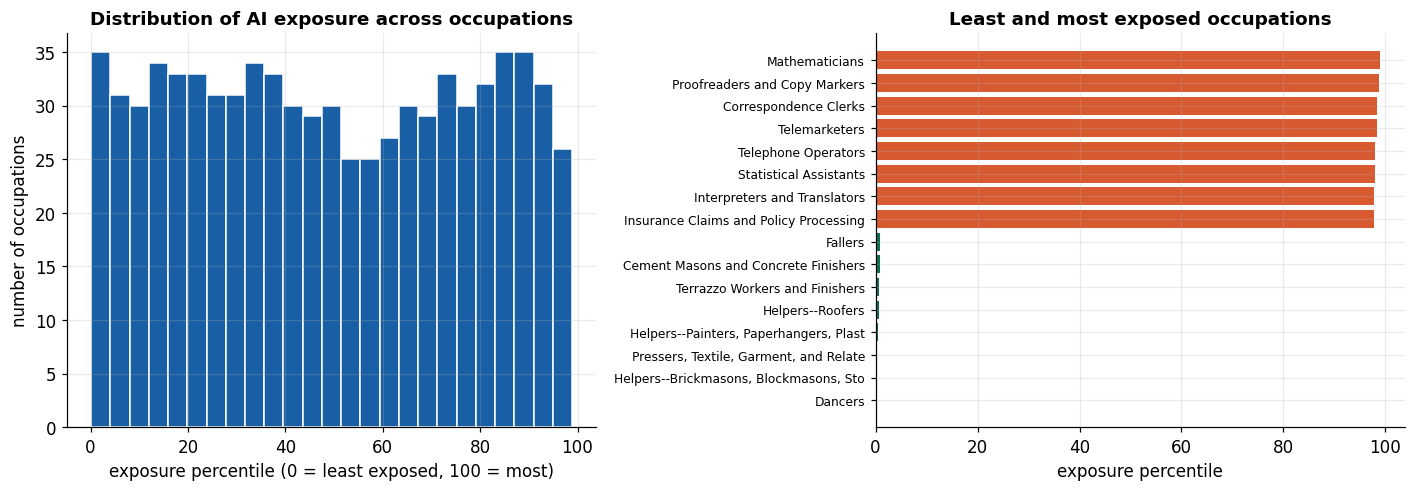

Most exposed : Mathematicians, Proofreaders and Copy Markers, Correspondence Clerks
Least exposed: Dancers, Helpers--Brickmasons, Blockmasons, Stonemasons, and Tile and Marble Setters, Pressers, Textile, Garment, and Related Materials


In [7]:
# ============================== 2.4 THE EXPOSURE LANDSCAPE (descriptive) ==============================
_d = exp.dropna(subset=['exposure_pctl','occ_title_aioe']).copy()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].hist(_d.exposure_pctl, bins=25, color=C_BLUE, edgecolor='white')
ax[0].set_title('Distribution of AI exposure across occupations')
ax[0].set_xlabel('exposure percentile (0 = least exposed, 100 = most)')
ax[0].set_ylabel('number of occupations')
_sel = pd.concat([_d.nsmallest(8,'exposure_pctl'), _d.nlargest(8,'exposure_pctl')]).sort_values('exposure_pctl')
ax[1].barh(range(len(_sel)), _sel.exposure_pctl,
           color=[C_GREEN if v < 50 else C_RED for v in _sel.exposure_pctl])
ax[1].set_yticks(range(len(_sel)))
ax[1].set_yticklabels(_sel.occ_title_aioe.astype(str).str.slice(0, 38), fontsize=8)
ax[1].set_title('Least and most exposed occupations'); ax[1].set_xlabel('exposure percentile')
plt.savefig(f'{OUT}/fig_exposure_landscape.png'); plt.show()
print('Most exposed :', ', '.join(_d.nlargest(3,'exposure_pctl').occ_title_aioe.astype(str)))
print('Least exposed:', ', '.join(_d.nsmallest(3,'exposure_pctl').occ_title_aioe.astype(str)))

---
# Part 3. RO1b. Localising the measure onto the Malaysian classification
---

The three indices are defined on United States occupation codes and cannot be applied to
Malaysian data without a mapping. The chain runs

    O*NET-SOC 2018  ->  SOC 2010  ->  ISCO-08  ->  MASCO 2020

using the official Bureau of Labor Statistics crosswalks. MASCO 2020 is derived from ISCO-08 and
shares its major-group structure, so alignment at the major-group level is structural rather than
estimated. Transferring indices this way is established practice: Pizzinelli et al. (2023) do it
for six economies and Demombynes et al. (2025) for twenty-five.

**What the method assumes.** The IMF states the assumption plainly, that the key tasks and skills
making up an occupation do not change across countries. Lewandowski et al. (2022) show that
occupational structure explains only about one fifth of cross-country variation in task content,
so the assumption is not free. Neither the IMF nor the World Bank tests the transferred measure
against outcomes in the destination country. Part 5 of this notebook does, which is the point at
which this study departs from the precedent it follows.

In [8]:
# ============================== 3.1 THE CROSSWALK CHAIN ==============================
s18 = pd.read_excel(f'{DATA}/soc_2010_to_2018_crosswalk.xlsx', skiprows=8)
s18.columns = [str(c).strip() for c in s18.columns]
s18 = s18.dropna(subset=['2010 SOC Code','2018 SOC Code'])

isco = pd.read_excel(f'{DATA}/ISCO_SOC_Crosswalk.xls', sheet_name='2010 SOC to ISCO-08', skiprows=6)
isco.columns = [str(c).strip() for c in isco.columns]
isco = isco.dropna(subset=['2010 SOC Code','ISCO-08 Code'])
isco['ISCO-08 Code'] = isco['ISCO-08 Code'].astype(int).astype(str).str.zfill(4)

chain = (s18.merge(isco[['2010 SOC Code','ISCO-08 Code','ISCO-08 Title EN']], on='2010 SOC Code')
            .rename(columns={'2018 SOC Code':'soc6'}))

# One SOC-2018 code can reach several ISCO codes. The modal target is taken; 3.2 tests that choice.
soc2isco = chain.groupby('soc6', as_index=False).agg(
    isco4=('ISCO-08 Code', lambda s: s.mode().iloc[0]),
    isco_title=('ISCO-08 Title EN','first'),
    n_candidates=('ISCO-08 Code','nunique'))
soc2isco['isco1'] = soc2isco.isco4.str[0]

exp = exp.drop(columns=[c for c in ['isco4','isco_title','isco1','n_candidates'] if c in exp.columns])
exp = exp.merge(soc2isco, on='soc6', how='left')

print(f'SOC 2010 to 2018 crosswalk rows : {len(s18):,}')
print(f'SOC 2010 to ISCO-08 rows        : {len(isco):,}')
print(f'Chained end to end              : {exp.isco4.notna().sum()} of {len(exp)} '
      f'({exp.isco4.notna().mean()*100:.1f}%)')
print(f'Occupations lost in the chain    : {exp.isco4.isna().sum()} '
      f'(these carry no Malaysian group anchor and are flagged, never silently imputed)')
print(f'\nAmbiguous mappings (more than one candidate ISCO code): '
      f'{(soc2isco.n_candidates > 1).sum()} of {len(soc2isco)} '
      f'({(soc2isco.n_candidates > 1).mean()*100:.1f}%)')
print('\nOccupations by ISCO major group:')
print('   ' + exp.isco1.value_counts().sort_index().to_string().replace('\n','\n   '))

SOC 2010 to 2018 crosswalk rows : 900
SOC 2010 to ISCO-08 rows        : 1,125
Chained end to end              : 662 of 889 (74.5%)
Occupations lost in the chain    : 227 (these carry no Malaysian group anchor and are flagged, never silently imputed)

Ambiguous mappings (more than one candidate ISCO code): 137 of 698 (19.6%)

Occupations by ISCO major group:
   isco1
   0      2
   1     38
   2    188
   3    128
   4     30
   5     50
   6     11
   7    117
   8     63
   9     35


## 3.2 Sensitivity of the mapping choice

Where a SOC code reaches more than one ISCO code, the modal target was selected. That is a
defensible but arbitrary rule, and Pizzinelli et al. (2023) handle the same problem differently,
taking simple averages and then re-running with employment weights to confirm the choice does not
drive their results. The equivalent test is run here.

Three alternative rules are compared against the modal rule: the first listed target, the
numerically lowest code, and the numerically highest. What matters downstream is the **major
group**, since that is what anchors Malaysian salary data and enters the models as a categorical
control, so agreement is measured on the major group and on the group-level mean exposure that
follows from it.

In [9]:
# ============================== 3.2 MAPPING SENSITIVITY ==============================
_rules = {
    'Mode (used throughout)': lambda s: s.mode().iloc[0],
    'First listed':           lambda s: s.iloc[0],
    'Lowest ISCO code':       lambda s: sorted(s)[0],
    'Highest ISCO code':      lambda s: sorted(s)[-1],
}
_alt = {}
for nm, fn in _rules.items():
    a = chain.groupby('soc6')['ISCO-08 Code'].apply(fn)
    _alt[nm] = a.astype(str).str[0]
_A = pd.DataFrame(_alt)
_base = _A['Mode (used throughout)']

_gexp = exp[['soc6','exposure']].dropna().set_index('soc6').exposure
rows = []
for nm in _rules:
    agree = (_A[nm] == _base).mean() * 100
    g_base = _gexp.groupby(_base.reindex(_gexp.index)).mean()
    g_alt  = _gexp.groupby(_A[nm].reindex(_gexp.index)).mean()
    j = pd.concat([g_base.rename('b'), g_alt.rename('a')], axis=1).dropna()
    rows.append({'Tie-break rule': nm,
                 'Major group identical to mode, %': round(agree, 1),
                 'Groups formed': int(_A[nm].nunique()),
                 'rho of group mean exposure vs mode': round(spearman(j.b, j.a)[0], 4)})
sens = pd.DataFrame(rows)
print('CROSSWALK AGGREGATION SENSITIVITY\n')
print(sens.to_string(index=False))

_worst = sens.iloc[1:]['Major group identical to mode, %'].min()
print(f'\n   The least favourable alternative rule still assigns {_worst:.1f}% of occupations to the')
print('   same ISCO major group, and group-level mean exposure is essentially unchanged under every')
print('   rule. The downstream analysis therefore does not rest on the tie-break decision.')

# The IMF direction of aggregation: exposure averaged over the SOC codes reaching each ISCO code.
_isco_level = (chain.merge(exp[['soc6','exposure']], on='soc6', how='inner').dropna(subset=['exposure'])
                    .groupby('ISCO-08 Code').exposure.agg(['mean','count']))
print(f'\n   For reference, aggregating in the opposite direction as the IMF does gives exposure for')
print(f'   {len(_isco_level)} ISCO-08 unit groups, a mean of {_isco_level["count"].mean():.1f} SOC codes each.')
sens.to_csv(f'{OUT}/reliability_crosswalk_sensitivity.csv', index=False)

CROSSWALK AGGREGATION SENSITIVITY

        Tie-break rule  Major group identical to mode, %  Groups formed  rho of group mean exposure vs mode
Mode (used throughout)                             100.0             10                              1.0000
          First listed                              99.7             10                              1.0000
      Lowest ISCO code                             100.0             10                              1.0000
     Highest ISCO code                              91.8             10                              0.9879

   The least favourable alternative rule still assigns 91.8% of occupations to the
   same ISCO major group, and group-level mean exposure is essentially unchanged under every
   rule. The downstream analysis therefore does not rest on the tie-break decision.

   For reference, aggregating in the opposite direction as the IMF does gives exposure for
   384 ISCO-08 unit groups, a mean of 2.4 SOC codes each.


---
# Part 4. The O*NET occupational spine and the master analysis table
---

Every occupation in the study is described by the same 119 O*NET elements covering skills,
abilities and knowledge, each rated for importance. This matrix is what makes skill distance
between occupations computable, and it is the basis of both the pivot recommendations in Part 7
and the reskilling gap analysis.

`m` is the single analysis table from here on. One row per O*NET occupation.

In [10]:
# ============================== 4.1 O*NET SPINE AND MASTER TABLE ==============================
od = f'{DATA}/onet'
occ_data = pd.read_excel(f'{od}/Occupation Data.xlsx')
tasks    = pd.read_excel(f'{od}/Task Statements.xlsx')
jz       = pd.read_excel(f'{od}/Job Zones.xlsx')[['O*NET-SOC Code','Job Zone']]
related  = pd.read_excel(f'{od}/Related Occupations.xlsx')
alt      = pd.read_excel(f'{od}/Sample of Reported Titles.xlsx')
jt       = pd.read_excel(f'{od}/Job Titles.xlsx')

_frames = []
for f in ['Essential Skills','Transferable Skills','Abilities','Knowledge']:
    d = pd.read_excel(f'{od}/{f}.xlsx')
    d = d[d['Scale ID'] == 'IM'][['O*NET-SOC Code','Element Name','Data Value']]
    d['family'] = f
    _frames.append(d)
skills_long = pd.concat(_frames)
skill_mat = skills_long.pivot_table(index='O*NET-SOC Code', columns='Element Name',
                                    values='Data Value', aggfunc='mean').fillna(0)
print(f'Skill matrix: {skill_mat.shape[0]} occupations x {skill_mat.shape[1]} elements '
      f'(importance scale 1 to 5)')

m = occ_data.rename(columns={'O*NET-SOC Code':'onet_soc','Title':'title','Description':'description'})
m['soc6'] = m.onet_soc.str[:7]
m = (m.merge(exp[['soc6','exposure','exposure_pctl','aioe','gpt_beta','lm_aioe',
                  'isco4','isco_title','isco1']], on='soc6', how='left')
      .merge(jz.rename(columns={'O*NET-SOC Code':'onet_soc'}), on='onet_soc', how='left'))
_jz_missing = m['Job Zone'].isna().sum()
m['Job Zone'] = m['Job Zone'].fillna(3)
m = m[m.onet_soc.isin(skill_mat.index)].reset_index(drop=True)

print(f'Master table: {len(m)} occupations')
print(f'   with a composite exposure score : {m.exposure.notna().sum()}')
print(f'   with an ISCO major group        : {m.isco1.notna().sum()}')
print(f'   Job Zone imputed to 3 (median)  : {_jz_missing}')
print(f'\nNote on two counts that are easy to confuse: the composite covers {exp.exposure.notna().sum()} '
      f'SOC-6 records,\nwhile the master table has {len(m)} O*NET occupations, because several O*NET '
      'codes share one SOC-6 code.')

Skill matrix: 894 occupations x 119 elements (importance scale 1 to 5)
Master table: 894 occupations
   with a composite exposure score : 894
   with an ISCO major group        : 746
   Job Zone imputed to 3 (median)  : 93

Note on two counts that are easy to confuse: the composite covers 889 SOC-6 records,
while the master table has 894 O*NET occupations, because several O*NET codes share one SOC-6 code.


---
# Part 5. RO1c. Criterion validation in two labour markets
---

A transferred index is an assumption until it is tested against something observable in the
market where it is used. This part supplies that test. Three outcomes are examined in both the
source market (United States) and the destination market (Malaysia):

| Outcome | United States | Malaysia |
|---|---|---|
| Pay level | BLS OEWS median annual wage, 2024 | JobStreet posted median, RM per month |
| Wage growth | OEWS compound annual growth, 2015 to 2024 | DOSM median salary growth, nine major groups |
| Hiring demand | LinkedIn posting counts by occupation | JobStreet posting counts by occupation |

**What counts as success.** The composite is not required to be statistically significant on every
outcome in both markets; the Malaysian wage-growth series exists only at nine major groups, which
cannot support a significant correlation regardless of the underlying truth. Success is defined as
**sign agreement across markets** on each outcome, with significance reported honestly wherever the
sample allows it. This criterion is stated before the results are seen.

Units differ between markets, annual United States dollars against monthly ringgit. All tests are
rank-based, so units and periods do not affect the comparison.

In [11]:
# ============================== 5.1 HIRING AND PAY DATA ==============================
def norm_title(s):
    s = str(s).lower().strip()
    s = re.sub(r'\s*[-(,/|@].*', '', s)
    s = re.sub(r'\b(senior|junior|lead|principal|assistant|associate|sr|jr|ii|iii|iv|executive)\b', '', s)
    return re.sub(r'\s+', ' ', s).strip()

# title -> occupation lookup from the three O*NET title corpora
lookup = {}
for _, rr in occ_data.iterrows(): lookup[rr['Title'].lower()] = rr['O*NET-SOC Code']
for _, rr in alt.iterrows():      lookup.setdefault(str(rr['Reported Job Title']).lower(), rr['O*NET-SOC Code'])
for _, rr in jt.iterrows():       lookup.setdefault(str(rr['Job Title']).lower(), rr['O*NET-SOC Code'])
print(f'Title lookup built from {len(lookup):,} distinct O*NET title strings')

# ---- United States postings (LinkedIn, read straight from the archive) ----
post = pd.read_csv(f'{DATA}/postings.csv.zip', usecols=['title','normalized_salary'])
post['onet_soc'] = post.title.map(norm_title).map(lookup)
demand_us = (post.dropna(subset=['onet_soc']).groupby('onet_soc')
             .agg(n_us=('title','size'), mkt_salary=('normalized_salary','median')).reset_index())
print(f'LinkedIn  : {len(post):,} postings loaded, {int(demand_us.n_us.sum()):,} matched '
      f'({demand_us.n_us.sum()/len(post)*100:.1f}%) across {len(demand_us)} occupations')

# ---- Malaysian postings (JobStreet) ----
js = pd.read_csv(f'{DATA}/jobstreet_all_job_dataset.csv',
                 usecols=['job_title','role','salary','listingDate'])
def parse_rm(s):
    s = str(s).replace('\xa0', ' ')
    if 'RM' not in s: return None
    nums = [float(x.replace(',', '')) for x in re.findall(r'RM\s*([\d,]+(?:\.\d+)?)', s)]
    if not nums: return None
    v = sum(nums) / len(nums)
    if 'per hour' in s: v *= 173
    if 'per year' in s or 'per annum' in s: v /= 12
    return v if 800 <= v <= 100000 else None

js['t'] = js.job_title.map(norm_title)
js['soc_match'] = js['t'].map(lookup)
_role = js.role.fillna('').str.replace('-', ' ').str.lower().str.strip()
js.loc[js.soc_match.isna(), 'soc_match'] = _role[js.soc_match.isna()].map(lookup)
js['rm'] = js.salary.map(parse_rm)
jm = (js.dropna(subset=['soc_match']).groupby('soc_match')
        .agg(n_my=('job_title','size'), rm_med=('rm','median'), rm_n=('rm','count'))
        .reset_index().rename(columns={'soc_match':'onet_soc'}))
print(f'JobStreet : {len(js):,} postings loaded, {int(jm.n_my.sum()):,} matched '
      f'({jm.n_my.sum()/len(js)*100:.1f}%) across {len(jm)} occupations, '
      f'{(jm.rm_n >= 5).sum()} with a usable RM median (at least 5 salaried postings)')

# Malaysian title dictionary, used by the artifact in Part 7 and 11
_al = js.dropna(subset=['soc_match']); _al = _al[_al['t'].str.len() >= 4]
alias_freq = (_al.groupby(['t','soc_match']).size().reset_index(name='cnt')
                 .sort_values('cnt', ascending=False).drop_duplicates('t'))
_valid = set(m.onet_soc)
ALIAS2SOC = {k: v for k, v in alias_freq[['t','soc_match']].values if v in _valid}
ALIAS_DD  = {k for k, c in alias_freq[['t','cnt']].values
             if c >= 2 and alias_freq.set_index('t').soc_match.get(k) in _valid}
print(f'            Malaysian title dictionary: {len(ALIAS2SOC)} titles, {len(ALIAS_DD)} in the dropdown')

# hiring momentum, displayed to the user but never used as a validation outcome
_jd = pd.to_datetime(js.listingDate, errors='coerce')
js['late'] = _jd > _jd.median()
_mom = (js.dropna(subset=['soc_match']).groupby('soc_match')
          .agg(n_all=('late','size'), n_late=('late','sum')).reset_index())
_mom['momentum'] = _mom.n_late / (_mom.n_all - _mom.n_late).clip(lower=1)
_mom = _mom[_mom.n_all >= 20][['soc_match','momentum']].rename(columns={'soc_match':'onet_soc'})
print(f'            Hiring momentum available for {len(_mom)} occupations (display only, '
      f'window is {(_jd.max()-_jd.min()).days/30.4:.1f} months)')

# ---- merge into the master table (idempotent) ----
m = m.drop(columns=[c for c in ['n_us','mkt_salary','n_my','rm_med','rm_n','momentum',
                                'demand_us_pctl','demand_my_pctl','demand_pctl'] if c in m.columns])
m = (m.merge(demand_us, on='onet_soc', how='left')
      .merge(jm, on='onet_soc', how='left')
      .merge(_mom, on='onet_soc', how='left'))
m['demand_us_pctl'] = m.n_us.rank(pct=True) * 100
m['demand_my_pctl'] = m.n_my.rank(pct=True) * 100
m['demand_pctl'] = m.demand_my_pctl.fillna(m.demand_us_pctl).fillna(30)
print(f'\nDemand percentile assigned to all {len(m)} occupations '
      f'(Malaysian where available, United States as fallback, low prior where unseen).')

Title lookup built from 47,700 distinct O*NET title strings
LinkedIn  : 123,849 postings loaded, 44,415 matched (35.9%) across 783 occupations
JobStreet : 69,024 postings loaded, 30,771 matched (44.6%) across 581 occupations, 247 with a usable RM median (at least 5 salaried postings)
            Malaysian title dictionary: 6815 titles, 1836 in the dropdown
            Hiring momentum available for 212 occupations (display only, window is 25.5 months)

Demand percentile assigned to all 894 occupations (Malaysian where available, United States as fallback, low prior where unseen).


US pay LEVEL  2024        rho = +0.511  p = 1.32e-51  n = 756
US wage GROWTH 2015-24    rho = -0.491  p = 7.93e-42  n = 669

   Exposed occupations are better paid today but their pay has grown more slowly.
   Felten et al. (2023) report the same positive level relationship on their own index,
   so this reproduces a published United States result before anything is claimed for Malaysia.


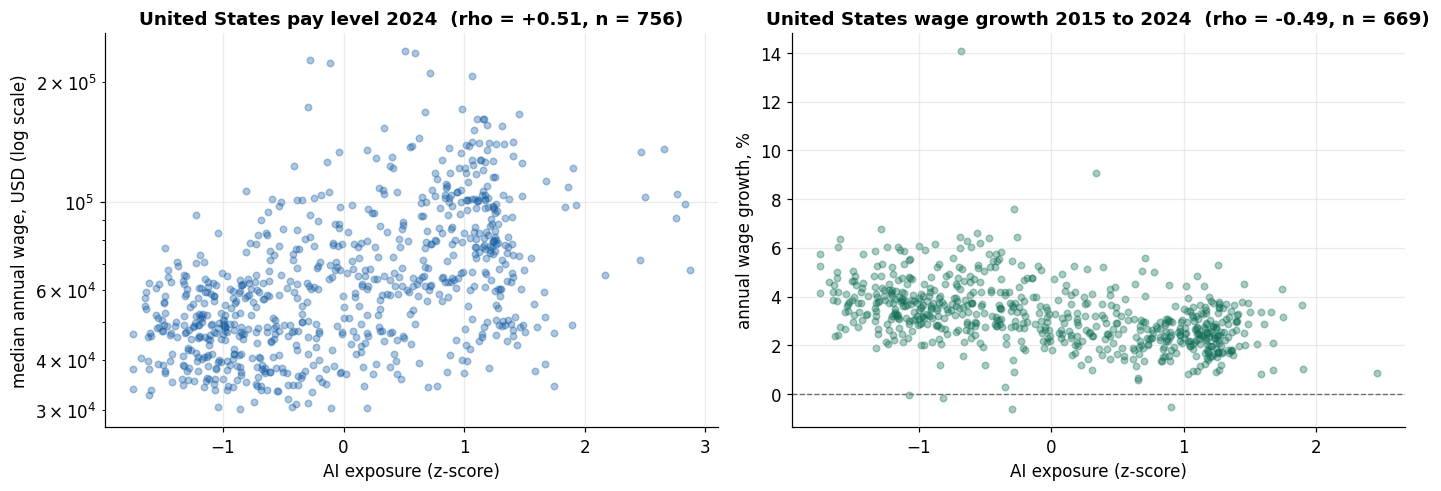


   Plotted at occupation level so the dispersion behind the correlations is visible.
   Section 5.5 bins the same data, which shows the pattern more clearly but hides the spread.


In [12]:
# ============================== 5.2 UNITED STATES WAGES (OEWS) ==============================
WAGE_DIR = f'{DATA}/US National Wages'
def load_oews(year):
    df = pd.read_excel(f'{WAGE_DIR}/national_M{year}_dl.xlsx')
    gcol = 'O_GROUP' if 'O_GROUP' in df.columns else 'OCC_GROUP'   # renamed by BLS across survey years
    d = df[df[gcol] == 'detailed'][['OCC_CODE','A_MEDIAN']].copy()
    d['A_MEDIAN'] = pd.to_numeric(d['A_MEDIAN'].astype(str).str.replace(',', '').str.strip(),
                                  errors='coerce')              # BLS suppression marks '*' and '#' -> NaN
    return d.dropna(subset=['A_MEDIAN']).rename(columns={'OCC_CODE':'soc6', 'A_MEDIAN':f'wage_{year}'})

w15, w24 = load_oews(2015), load_oews(2024)
usw = w24.merge(w15, on='soc6', how='inner')
usw['us_wage_cagr'] = (usw.wage_2024 / usw.wage_2015) ** (1/9) - 1
uw = (exp[['soc6','exposure']].merge(w24[['soc6','wage_2024']], on='soc6', how='left')
                              .merge(usw[['soc6','us_wage_cagr']], on='soc6', how='left'))

R_US_LEVEL  = spearman(uw.exposure, uw.wage_2024)
R_US_GROWTH = spearman(uw.exposure, uw.us_wage_cagr)
print(f'US pay LEVEL  2024        rho = {R_US_LEVEL[0]:+.3f}  p = {R_US_LEVEL[1]:.2e}  n = {R_US_LEVEL[2]}')
print(f'US wage GROWTH 2015-24    rho = {R_US_GROWTH[0]:+.3f}  p = {R_US_GROWTH[1]:.2e}  n = {R_US_GROWTH[2]}')
print('\n   Exposed occupations are better paid today but their pay has grown more slowly.')
print('   Felten et al. (2023) report the same positive level relationship on their own index,')
print('   so this reproduces a published United States result before anything is claimed for Malaysia.')
uw.to_csv(f'{OUT}/us_wage_validation.csv', index=False)

# --- Figure: the two United States relationships at occupation level, before any binning ---
_lv = uw.dropna(subset=['exposure','wage_2024']); _gr = uw.dropna(subset=['exposure','us_wage_cagr'])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(_lv.exposure, _lv.wage_2024, alpha=.35, s=18, color=C_BLUE)
ax[0].set_yscale('log')
ax[0].set_title(f'United States pay level 2024  (rho = {R_US_LEVEL[0]:+.2f}, n = {R_US_LEVEL[2]})')
ax[0].set_xlabel('AI exposure (z-score)'); ax[0].set_ylabel('median annual wage, USD (log scale)')
ax[1].scatter(_gr.exposure, _gr.us_wage_cagr * 100, alpha=.35, s=18, color=C_GREEN)
ax[1].axhline(0, color=C_GREY, lw=.9, ls='--')
ax[1].set_title(f'United States wage growth 2015 to 2024  (rho = {R_US_GROWTH[0]:+.2f}, n = {R_US_GROWTH[2]})')
ax[1].set_xlabel('AI exposure (z-score)'); ax[1].set_ylabel('annual wage growth, %')
plt.savefig(f'{OUT}/fig_us_pay_and_growth.png'); plt.show()
print('\n   Plotted at occupation level so the dispersion behind the correlations is visible.')
print('   Section 5.5 bins the same data, which shows the pattern more clearly but hides the spread.')

MY pay LEVEL (JobStreet)  rho = +0.433  p = 4.99e-12  n = 232
DOSM parsed: all 9 MASCO major groups, 2010 to 2024, RM per month
MY wage GROWTH (DOSM)     rho = -0.183  p = 0.637  n = 9

   The Malaysian growth series exists only at nine major groups. The sign agrees with the
   United States result but the sample cannot support significance, and it is reported as
   directional evidence only. This limitation is stated in the report, not hidden.


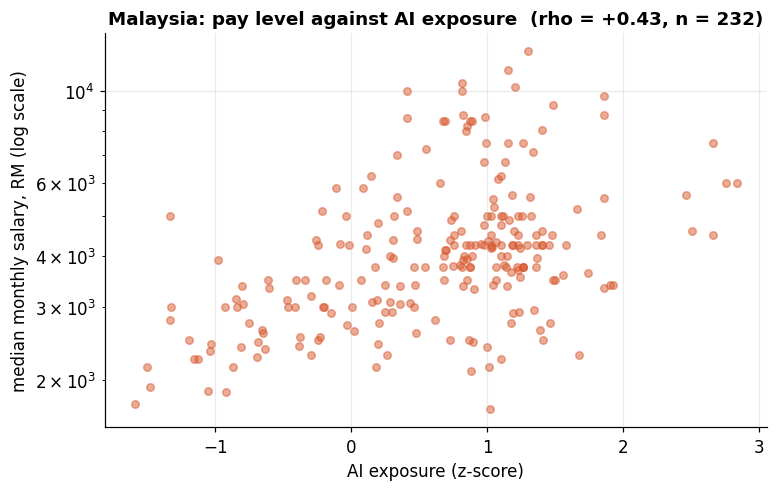

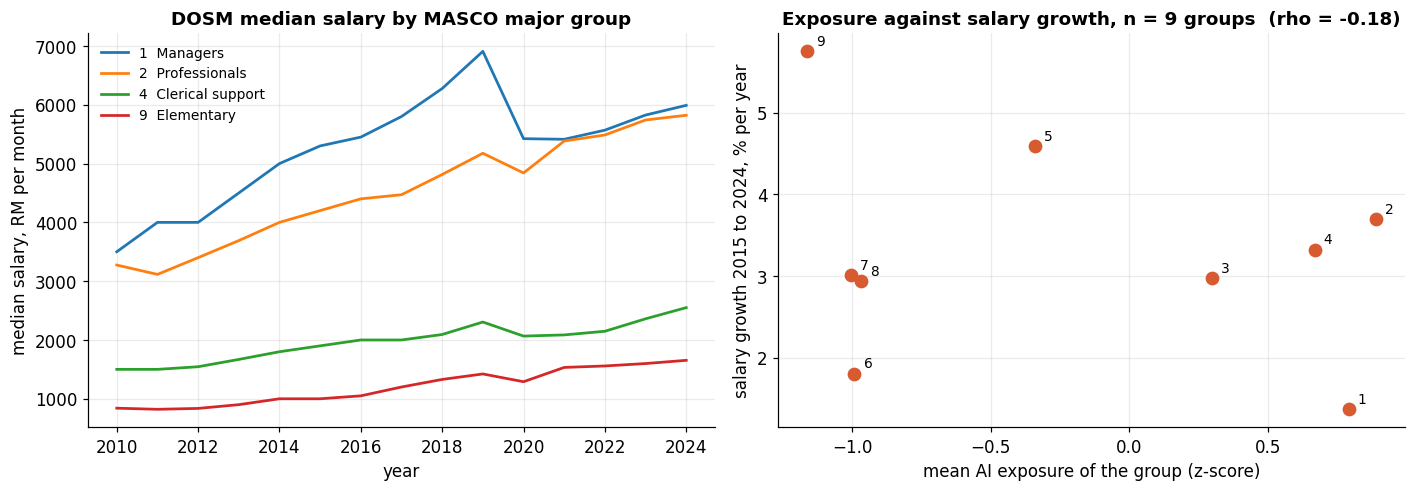


   The right panel is the whole Malaysian wage-growth sample. Nine points is the reason
   the success condition for RO1 was set on sign agreement rather than on significance.


In [13]:
# ============================== 5.3 MALAYSIAN WAGES (JobStreet, DOSM) ==============================
# --- pay level: JobStreet posted medians ---
mw = m[(m.rm_n >= 5) & m.exposure.notna() & m.rm_med.notna()]
R_MY_LEVEL = spearman(mw.exposure, mw.rm_med)
print(f'MY pay LEVEL (JobStreet)  rho = {R_MY_LEVEL[0]:+.3f}  p = {R_MY_LEVEL[1]:.2e}  n = {R_MY_LEVEL[2]}')

# --- wage growth: DOSM, published only at nine MASCO major groups ---
raw = pd.read_excel(f'{DATA}/salaries_wages_2024.xlsx',
                    sheet_name='JADUAL A10 Pekerjaan Jumlah', header=None)
_yr_row = next(i for i in range(len(raw)) if str(raw.iloc[i,0]).strip().startswith('Pekerjaan'))
years = [int(v) for v in raw.iloc[_yr_row].dropna().tolist()[1:] if str(v).replace('.0','').isdigit()]
_blk = {k: next(i for i in range(len(raw)) if key in str(raw.iloc[i,0]))
        for k, key in [('median','Penengah'), ('mean','Purata')]}
MY2ISCO = {1:'Pengurus', 2:'Profesional', 3:'Juruteknik', 4:'perkeranian', 5:'perkhidmatan',
           6:'pertanian', 7:'kemahiran', 8:'Operator', 9:'asas'}
_rows = []
for stat, start in _blk.items():
    for i in range(start + 1, start + 10):
        nm = str(raw.iloc[i, 0])
        if 'Purata' in nm or 'Penengah' in nm: break
        hit = [(nm.lower().find(v.lower()), k) for k, v in MY2ISCO.items() if v.lower() in nm.lower()]
        if hit:
            k = min(hit)[1]        # earliest keyword wins: 'Juruteknik ... profesional' must not match group 2
            for yi, y in enumerate(years):
                _rows.append({'isco1':str(k), 'stat':stat, 'year':y, 'salary':raw.iloc[i, 1+yi]})
dosm = pd.DataFrame(_rows).dropna()
dosm_med = dosm[dosm.stat == 'median'].pivot_table(index='isco1', columns='year',
                                                   values='salary', aggfunc='first')
dosm_med['cagr_2015_2024'] = (dosm_med[2024] / dosm_med[2015]) ** (1/9) - 1
assert len(dosm_med) == 9, f'DOSM parse recovered {len(dosm_med)} groups, expected 9'
print(f'DOSM parsed: all {len(dosm_med)} MASCO major groups, {min(years)} to {max(years)}, RM per month')

_gexp = m.groupby('isco1').exposure.mean()
_val = dosm_med.join(_gexp).dropna(subset=['exposure'])
R_MY_GROWTH = spearman(_val.exposure, _val.cagr_2015_2024)
print(f'MY wage GROWTH (DOSM)     rho = {R_MY_GROWTH[0]:+.3f}  p = {R_MY_GROWTH[1]:.3f}  n = {R_MY_GROWTH[2]}')
print('\n   The Malaysian growth series exists only at nine major groups. The sign agrees with the')
print('   United States result but the sample cannot support significance, and it is reported as')
print('   directional evidence only. This limitation is stated in the report, not hidden.')
dosm.to_csv(f'{OUT}/dosm_salary_tidy.csv', index=False)

# --- Figure: Malaysian pay level at occupation level ---
fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.scatter(mw.exposure, mw.rm_med, alpha=.5, s=24, color=C_RED)
ax.set_yscale('log')
ax.set_title(f'Malaysia: pay level against AI exposure  (rho = {R_MY_LEVEL[0]:+.2f}, n = {R_MY_LEVEL[2]})')
ax.set_xlabel('AI exposure (z-score)'); ax.set_ylabel('median monthly salary, RM (log scale)')
plt.savefig(f'{OUT}/fig_my_pay_level.png'); plt.show()
mw[['onet_soc','title','exposure','rm_med','rm_n']].to_csv(f'{OUT}/my_wage_level.csv', index=False)

# --- Figure: the official Malaysian series, and why nine groups is the binding constraint ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for _g, _lab in [('1','1  Managers'), ('2','2  Professionals'),
                 ('4','4  Clerical support'), ('9','9  Elementary')]:
    if _g in dosm_med.index:
        ax[0].plot(years, dosm_med.loc[_g, years], label=_lab, lw=1.8)
ax[0].set_title('DOSM median salary by MASCO major group')
ax[0].set_xlabel('year'); ax[0].set_ylabel('median salary, RM per month')
ax[0].legend(frameon=False, fontsize=9)
ax[1].scatter(_val.exposure, _val.cagr_2015_2024 * 100, s=64, color=C_RED, zorder=3)
for _g in _val.index:
    ax[1].annotate(str(_g), (_val.loc[_g,'exposure'], _val.loc[_g,'cagr_2015_2024'] * 100),
                   xytext=(6, 4), textcoords='offset points', fontsize=9)
ax[1].set_title(f'Exposure against salary growth, n = 9 groups  (rho = {R_MY_GROWTH[0]:+.2f})')
ax[1].set_xlabel('mean AI exposure of the group (z-score)')
ax[1].set_ylabel('salary growth 2015 to 2024, % per year')
plt.savefig(f'{OUT}/fig_dosm_nine_groups.png'); plt.show()
print('\n   The right panel is the whole Malaysian wage-growth sample. Nine points is the reason')
print('   the success condition for RO1 was set on sign agreement rather than on significance.')

US hiring demand   rho = +0.306  p = 3.04e-17  n = 728
MY hiring demand   rho = +0.390  p = 4.60e-21  n = 539

CROSS-SOURCE RELIABILITY OF THE DEMAND MEASURE
   LinkedIn against JobStreet, occupation demand percentiles
   rho = +0.655  p = 4.88e-64  n = 512 occupations present in both
   Two independently collected posting datasets, different countries, different platforms.
   Agreement here is evidence that posting counts measure occupational demand rather than
   the idiosyncrasies of one platform. Disagreement would be evidence of the opposite.


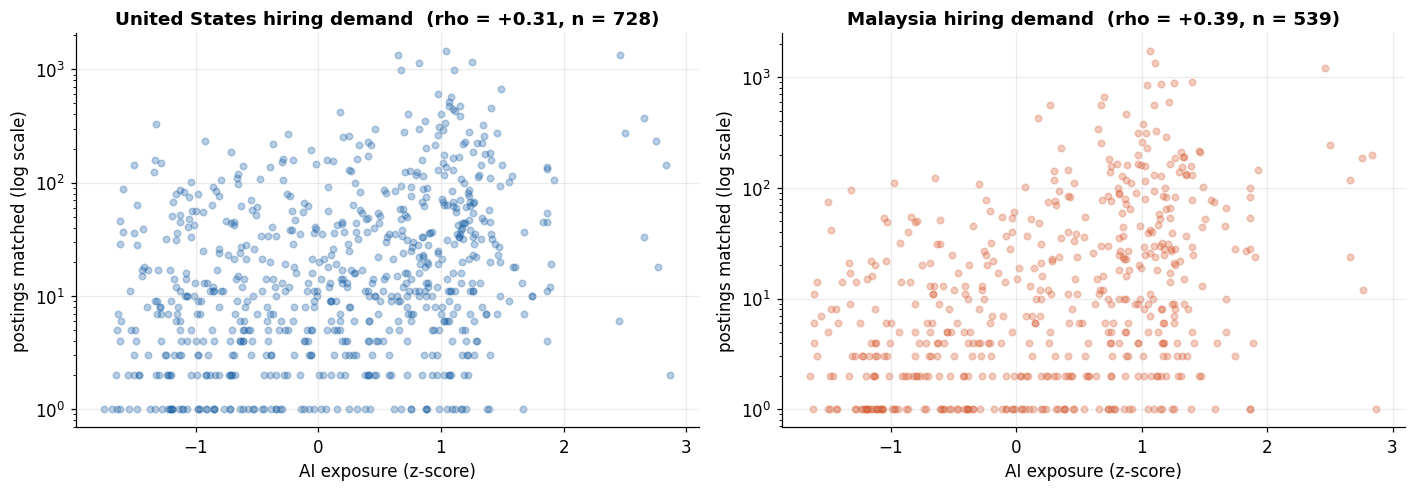


   Posting counts are heavily skewed, so a log scale is used. The relationship is positive
   in both markets: exposed occupations are still recruiting, not shrinking.


In [14]:
# ============================== 5.4 HIRING DEMAND, TWO MARKETS ==============================
_v_us = m.dropna(subset=['exposure','n_us'])
_v_my = m.dropna(subset=['exposure','n_my'])
R_US_DEMAND = spearman(_v_us.exposure, _v_us.n_us)
R_MY_DEMAND = spearman(_v_my.exposure, _v_my.n_my)
print(f'US hiring demand   rho = {R_US_DEMAND[0]:+.3f}  p = {R_US_DEMAND[1]:.2e}  n = {R_US_DEMAND[2]}')
print(f'MY hiring demand   rho = {R_MY_DEMAND[0]:+.3f}  p = {R_MY_DEMAND[1]:.2e}  n = {R_MY_DEMAND[2]}')

# ---------- RELIABILITY: do two independent posting sources agree with each other? ----------
_both = m.dropna(subset=['n_us','n_my'])
DEMAND_RELIABILITY = spearman(_both.demand_us_pctl, _both.demand_my_pctl)
print(f'\nCROSS-SOURCE RELIABILITY OF THE DEMAND MEASURE')
print(f'   LinkedIn against JobStreet, occupation demand percentiles')
print(f'   rho = {DEMAND_RELIABILITY[0]:+.3f}  p = {DEMAND_RELIABILITY[1]:.2e}  n = {DEMAND_RELIABILITY[2]} '
      f'occupations present in both')
print('   Two independently collected posting datasets, different countries, different platforms.')
print('   Agreement here is evidence that posting counts measure occupational demand rather than')
print('   the idiosyncrasies of one platform. Disagreement would be evidence of the opposite.')

# --- Figure: hiring demand against exposure in both markets ---
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(_v_us.exposure, _v_us.n_us, alpha=.3, s=18, color=C_BLUE); ax[0].set_yscale('log')
ax[0].set_title(f'United States hiring demand  (rho = {R_US_DEMAND[0]:+.2f}, n = {R_US_DEMAND[2]})')
ax[0].set_xlabel('AI exposure (z-score)'); ax[0].set_ylabel('postings matched (log scale)')
ax[1].scatter(_v_my.exposure, _v_my.n_my, alpha=.3, s=18, color=C_RED); ax[1].set_yscale('log')
ax[1].set_title(f'Malaysia hiring demand  (rho = {R_MY_DEMAND[0]:+.2f}, n = {R_MY_DEMAND[2]})')
ax[1].set_xlabel('AI exposure (z-score)'); ax[1].set_ylabel('postings matched (log scale)')
plt.savefig(f'{OUT}/fig_demand_two_markets.png'); plt.show()
print('\n   Posting counts are heavily skewed, so a log scale is used. The relationship is positive')
print('   in both markets: exposed occupations are still recruiting, not shrinking.')

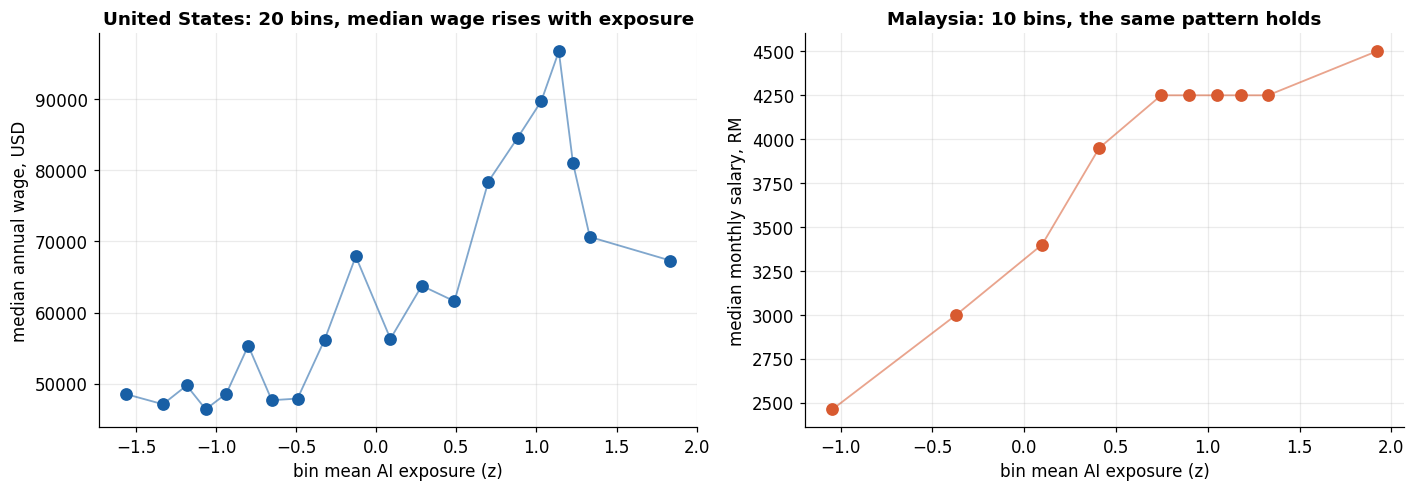

Bin-level rank correlation, United States : rho = +0.853 over 20 bins (37 to 38 occupations per bin)
Bin-level rank correlation, Malaysia      : rho = +0.937 over 10 bins (23 to 24 occupations per bin)

   Binning removes occupation-level noise and shows the relationship is monotone rather
   than driven by outliers. The United States panel replicates the published finding; the
   Malaysian panel is the contribution, since the transfer had not previously been tested.


In [15]:
# ============================== 5.5 TWENTY-BIN REPLICATION OF THE PUBLISHED RESULT ==============================
# Felten et al. (2023) validate the exposure-wage relationship by grouping occupations into 20
# equal-sized bins on the exposure score and plotting bin-mean exposure against bin wage. The
# same procedure is applied here to the United States, reproducing their method, and then to
# Malaysia, where no published equivalent exists.
def binscatter(x, y, nbins):
    d = pd.DataFrame({'x': np.asarray(x, float), 'y': np.asarray(y, float)}).dropna()
    d['bin'] = pd.qcut(d.x.rank(method='first'), nbins, labels=False)
    return d.groupby('bin').agg(x=('x','mean'), y=('y','median'), n=('y','size'))

_us = uw.dropna(subset=['exposure','wage_2024'])
_my = mw[['exposure','rm_med']].dropna()
NB_US, NB_MY = 20, (20 if len(_my) >= 300 else 10)
b_us, b_my = binscatter(_us.exposure, _us.wage_2024, NB_US), binscatter(_my.exposure, _my.rm_med, NB_MY)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].scatter(b_us.x, b_us.y, s=54, color=C_BLUE, zorder=3)
ax[0].plot(b_us.x, b_us.y, color=C_BLUE, lw=1.2, alpha=.55)
ax[0].set_title(f'United States: {NB_US} bins, median wage rises with exposure')
ax[0].set_xlabel('bin mean AI exposure (z)'); ax[0].set_ylabel('median annual wage, USD')
ax[1].scatter(b_my.x, b_my.y, s=54, color=C_RED, zorder=3)
ax[1].plot(b_my.x, b_my.y, color=C_RED, lw=1.2, alpha=.55)
ax[1].set_title(f'Malaysia: {NB_MY} bins, the same pattern holds')
ax[1].set_xlabel('bin mean AI exposure (z)'); ax[1].set_ylabel('median monthly salary, RM')
plt.savefig(f'{OUT}/fig_binscatter_replication.png'); plt.show()

_rb_us, _rb_my = spearman(b_us.x, b_us.y), spearman(b_my.x, b_my.y)
print(f'Bin-level rank correlation, United States : rho = {_rb_us[0]:+.3f} over {NB_US} bins '
      f'({b_us.n.min()} to {b_us.n.max()} occupations per bin)')
print(f'Bin-level rank correlation, Malaysia      : rho = {_rb_my[0]:+.3f} over {NB_MY} bins '
      f'({b_my.n.min()} to {b_my.n.max()} occupations per bin)')
print('\n   Binning removes occupation-level noise and shows the relationship is monotone rather')
print('   than driven by outliers. The United States panel replicates the published finding; the')
print('   Malaysian panel is the contribution, since the transfer had not previously been tested.')

In [16]:
# ============================== 5.6 CONSOLIDATED CRITERION VALIDITY (RO1) ==============================
_crit = pd.DataFrame([
    {'Outcome':'Pay level',    'Market':'United States', 'Source':'BLS OEWS 2024',
     'rho':R_US_LEVEL[0],  'p':R_US_LEVEL[1],  'n':R_US_LEVEL[2]},
    {'Outcome':'Pay level',    'Market':'Malaysia',      'Source':'JobStreet posted medians',
     'rho':R_MY_LEVEL[0],  'p':R_MY_LEVEL[1],  'n':R_MY_LEVEL[2]},
    {'Outcome':'Wage growth',  'Market':'United States', 'Source':'OEWS CAGR 2015-24',
     'rho':R_US_GROWTH[0], 'p':R_US_GROWTH[1], 'n':R_US_GROWTH[2]},
    {'Outcome':'Wage growth',  'Market':'Malaysia',      'Source':'DOSM, 9 major groups',
     'rho':R_MY_GROWTH[0], 'p':R_MY_GROWTH[1], 'n':R_MY_GROWTH[2]},
    {'Outcome':'Hiring demand','Market':'United States', 'Source':'LinkedIn posting counts',
     'rho':R_US_DEMAND[0], 'p':R_US_DEMAND[1], 'n':R_US_DEMAND[2]},
    {'Outcome':'Hiring demand','Market':'Malaysia',      'Source':'JobStreet posting counts',
     'rho':R_MY_DEMAND[0], 'p':R_MY_DEMAND[1], 'n':R_MY_DEMAND[2]},
])
_crit['sign'] = np.where(_crit.rho > 0, '+', '-')
_crit['significant at .05'] = np.where(_crit.p < .05, 'yes', 'no')
_agree = _crit.groupby('Outcome')['sign'].nunique().eq(1)
_crit['rho'] = _crit.rho.round(3); _crit['p'] = _crit.p.map(lambda v: f'{v:.2e}')

print('CRITERION VALIDITY OF THE LOCALISED MEASURE\n')
print(_crit.to_string(index=False))
print('\nSign agreement across the two markets, which is the stated success criterion:')
for outcome, ok in _agree.items():
    print(f'   {outcome:14s} {"MET" if ok else "NOT MET"}')
RO1_MET = bool(_agree.all())
print(f'\nRO1 criterion-validity condition overall: {"MET" if RO1_MET else "NOT MET"}')
if not _crit['significant at .05'].eq('yes').all():
    _ns = _crit[_crit['significant at .05'] == 'no']
    print(f'   {len(_ns)} of {len(_crit)} tests is not significant at .05: '
          + '; '.join(f'{r.Outcome} in {r.Market} (n={r.n})' for _, r in _ns.iterrows()))
    print('   Reported as directional, never as confirmation.')
_crit.to_csv(f'{OUT}/validity_criterion_two_markets.csv', index=False)

CRITERION VALIDITY OF THE LOCALISED MEASURE

      Outcome        Market                   Source    rho        p   n sign significant at .05
    Pay level United States            BLS OEWS 2024  0.511 1.32e-51 756    +                yes
    Pay level      Malaysia JobStreet posted medians  0.433 4.99e-12 232    +                yes
  Wage growth United States        OEWS CAGR 2015-24 -0.491 7.93e-42 669    -                yes
  Wage growth      Malaysia     DOSM, 9 major groups -0.183 6.37e-01   9    -                 no
Hiring demand United States  LinkedIn posting counts  0.306 3.04e-17 728    +                yes
Hiring demand      Malaysia JobStreet posting counts  0.390 4.60e-21 539    +                yes

Sign agreement across the two markets, which is the stated success criterion:
   Hiring demand  MET
   Pay level      MET
   Wage growth    MET

RO1 criterion-validity condition overall: MET
   1 of 6 tests is not significant at .05: Wage growth in Malaysia (n=9)
   Reported

In [17]:
# ============================== 5.7 DATA PREPARATION AND QUALITY ==============================
# Read-only summary.
# ---------- (a) what each source contributed, and what was lost on the way ----------
_dq_rows = [
    {'Stage':'AIOE index', 'Source':'AIOE_DataAppendix.xlsx, Appendix A',
     'Rows in':len(aioe), 'Rows out':int(aioe.aioe.notna().sum()),
     'Treatment':'sheet read with skiprows=2 and explicit column names'},
    {'Stage':'GPT task exposure', 'Source':'occ_level.csv',
     'Rows in':len(gpt), 'Rows out':len(gpt6),
     'Treatment':'8-digit O*NET codes averaged to SOC-6'},
    {'Stage':'LM-AIOE index', 'Source':'Language Modeling AIOE and AIIE.xlsx',
     'Rows in':len(lm), 'Rows out':int(lm.lm_aioe.notna().sum()),
     'Treatment':'sheet read with skiprows=1'},
    {'Stage':'Composite exposure', 'Source':'the three indices, outer joined',
     'Rows in':len(exp), 'Rows out':int(exp.exposure.notna().sum()),
     'Treatment':'each index z-standardised, then averaged, then ranked to a percentile'},
    {'Stage':'SOC 2010 to 2018 crosswalk', 'Source':'soc_2010_to_2018_crosswalk.xlsx',
     'Rows in':len(s18), 'Rows out':int(s18['2018 SOC Code'].nunique()),
     'Treatment':'skiprows=8, rows without both codes dropped'},
    {'Stage':'SOC to ISCO crosswalk', 'Source':'ISCO_SOC_Crosswalk.xls',
     'Rows in':len(isco), 'Rows out':len(isco),
     'Treatment':f"skiprows=6, ISCO codes zero-padded to 4 characters; "
                 f"{isco['ISCO-08 Code'].nunique()} distinct ISCO codes across these rows"},
    {'Stage':'Chained SOC to ISCO', 'Source':'the two crosswalks joined',
     'Rows in':len(exp), 'Rows out':int(exp.isco4.notna().sum()),
     'Treatment':'many-to-many links resolved by modal target; unchained rows flagged, never imputed'},
    {'Stage':'O*NET skill matrix', 'Source':'Skills, Abilities, Knowledge workbooks',
     'Rows in':int(skills_long['O*NET-SOC Code'].nunique()), 'Rows out':int(skill_mat.shape[0]),
     'Treatment':"filtered to the importance scale, pivoted, absent elements set to 0"},
    {'Stage':'Master analysis table', 'Source':'O*NET Occupation Data',
     'Rows in':len(occ_data), 'Rows out':len(m),
     'Treatment':'restricted to occupations carrying a skill profile'},
    {'Stage':'US postings', 'Source':'postings.csv.zip (LinkedIn)',
     'Rows in':len(post), 'Rows out':int(post.onet_soc.notna().sum()),
     'Treatment':'titles normalised, then matched to an occupation; unmatched postings discarded'},
    {'Stage':'Malaysian postings', 'Source':'jobstreet_all_job_dataset.csv',
     'Rows in':len(js), 'Rows out':int(js.soc_match.notna().sum()),
     'Treatment':'title matched first, role slug used as fallback'},
    {'Stage':'Malaysian salaries', 'Source':'JobStreet salary strings',
     'Rows in':int(js.salary.notna().sum()), 'Rows out':int(js.rm.notna().sum()),
     'Treatment':'RM values parsed, hourly x173, annual /12, values outside RM 800 to 100,000 rejected'},
    {'Stage':'US wages 2024', 'Source':'national_M2024_dl.xlsx (BLS OEWS)',
     'Rows in':int(len(pd.read_excel(f'{WAGE_DIR}/national_M2024_dl.xlsx', usecols=['OCC_CODE']))),
     'Rows out':len(w24),
     'Treatment':"detailed occupations only; suppression marks '*' and '#' coerced to missing"},
    {'Stage':'US wage panel', 'Source':'five OEWS snapshots, inner joined',
     'Rows in':len(w24), 'Rows out':len(usw),
     'Treatment':'kept only occupations whose SOC code is stable across every snapshot'},
    {'Stage':'Malaysian wage series', 'Source':'salaries_wages_2024.xlsx (DOSM)',
     'Rows in':9, 'Rows out':len(dosm_med),
     'Treatment':'DOSM publishes 9 MASCO major groups; header row located by scanning and the '
                 'label matched on its earliest keyword, which recovers all 9'},
]
_dq = pd.DataFrame(_dq_rows)
_dq['Retained %'] = (_dq['Rows out'] / _dq['Rows in'] * 100).round(1)
_dq = _dq[['Stage','Source','Rows in','Rows out','Retained %','Treatment']]
print('DATA PREPARATION: WHAT EACH SOURCE CONTRIBUTED\n')
print(_dq.to_string(index=False))

# ---------- (b) missing values in the analysis table, and how each is handled ----------
_jz_imputed = int((~m.onet_soc.isin(set(jz['O*NET-SOC Code']))).sum())
_jz_before  = int(globals().get('_jz_missing', 0))
_rules = {
    'exposure':      'left missing; the occupation is excluded from every exposure result',
    'exposure_pctl': 'left missing; excluded from exposure results',
    'isco1':         'left missing; the occupation carries no Malaysian group anchor',
    'isco4':         'left missing; see above',
    'Job Zone':      (f'imputed to the median value of 3; {_jz_imputed} of the retained occupations '
                      f'required it ({_jz_before} were filled before the skill-profile filter removed them)'),
    'n_us':          'treated as no observed United States demand',
    'n_my':          'treated as no observed Malaysian demand',
    'rm_med':        'no reliable Malaysian median; a modelled estimate is supplied in Part 6.7 and labelled',
    'mkt_salary':    'no United States posting salary; the median is substituted where the model needs it',
    'momentum':      'shown only where at least 20 postings exist, otherwise omitted from the interface',
    'demand_pctl':   'Malaysian percentile first, United States as fallback, otherwise a low prior of 30',
}
_miss = []
for _c in ['exposure','exposure_pctl','isco1','isco4','Job Zone','n_us','n_my','rm_med',
           'mkt_salary','momentum','demand_pctl']:
    if _c not in m.columns: continue
    _n = int(m[_c].isna().sum())
    _miss.append({'Field':_c, 'Missing':_n, 'Missing %':round(_n/len(m)*100, 1),
                  'Treatment':_rules[_c]})
_missing = pd.DataFrame(_miss)
print(f'\n\nMISSING VALUES IN THE MASTER TABLE  ({len(m)} occupations)\n')
print(_missing.to_string(index=False))
print('\n   No field is silently filled with a value that would flatter a result. Where a value is')
print('   imputed the rule is stated above, and where an estimate replaces an observation the')
print('   provenance travels with it and is shown to the user.')

# ---------- (c) explicit filters and exclusion rules applied anywhere in the pipeline ----------
_filters = pd.DataFrame([
    {'Rule':'Malaysian salary plausibility', 'Applied to':'JobStreet salary strings',
     'Threshold':'RM 800 to RM 100,000 per month',
     'Reason':'removes hourly rates parsed as monthly and clear data-entry errors'},
    {'Rule':'Minimum salaried postings', 'Applied to':'JobStreet occupation medians',
     'Threshold':'at least 5 salaried postings',
     'Reason':'a median over fewer postings is unstable'},
    {'Rule':'Minimum postings for momentum', 'Applied to':'hiring momentum',
     'Threshold':'at least 20 postings',
     'Reason':'the measure compares two halves of a short window'},
    {'Rule':'Detailed occupations only', 'Applied to':'BLS OEWS wage files',
     'Threshold':"O_GROUP equals 'detailed'",
     'Reason':'excludes aggregate rows that would double-count'},
    {'Rule':'Stable occupation code', 'Applied to':'the five-snapshot wage panel',
     'Threshold':'present in all five years',
     'Reason':'a code that was redefined would show spurious wage change'},
    {'Rule':'Skill profile required', 'Applied to':'the master table',
     'Threshold':'occupation present in the O*NET importance data',
     'Reason':'without it no skill distance or reskilling gap can be computed'},
    {'Rule':'Realism gate', 'Applied to':'candidate career transitions',
     'Threshold':'within one Job Zone of the origin',
     'Reason':'prevents recommendations that ignore the education a move requires'},
])
print('\n\nEXPLICIT FILTERS AND EXCLUSION RULES\n')
print(_filters.to_string(index=False))

# ---------- (d) text normalisation, stated once because it governs every title match ----------
print('\n\nTEXT NORMALISATION APPLIED TO EVERY JOB TITLE')
print('   lower-cased, then truncated at the first of  -  (  ,  /  |  @')
print('   seniority and grade words removed: senior, junior, lead, principal, assistant,')
print('      associate, sr, jr, ii, iii, iv, executive')
print('   repeated whitespace collapsed')
print(f'   worked example: "Senior Data Analyst - Kuala Lumpur"  ->  "{norm_title("Senior Data Analyst - Kuala Lumpur")}"')
print('   The same function normalises the stored dictionary keys and the incoming query, so a')
print('   dictionary entry cannot become unreachable through a word the normaliser removes.')

_dq.to_csv(f'{OUT}/data_preparation_summary.csv', index=False)
_missing.to_csv(f'{OUT}/data_preparation_missing_values.csv', index=False)
_filters.to_csv(f'{OUT}/data_preparation_filters.csv', index=False)
print(f'\n\nSaved data_preparation_summary.csv, data_preparation_missing_values.csv '
      f'and data_preparation_filters.csv to {OUT}')

DATA PREPARATION: WHAT EACH SOURCE CONTRIBUTED

                     Stage                                 Source  Rows in  Rows out  Retained %                                                                                                                               Treatment
                AIOE index     AIOE_DataAppendix.xlsx, Appendix A      773       773       100.0                                                                                    sheet read with skiprows=2 and explicit column names
         GPT task exposure                          occ_level.csv      923       798        86.5                                                                                                   8-digit O*NET codes averaged to SOC-6
             LM-AIOE index   Language Modeling AIOE and AIIE.xlsx      774       774       100.0                                                                                                              sheet read with skiprows=1
        Composite ex

---
# Part 6. RO2. Estimating wage outcomes, and how much exposure contributes
---

**RO2** is to develop and benchmark models that estimate occupational wage-growth prospects and
Malaysian salary levels, and to quantify how much AI exposure contributes to those estimates.
Two questions, answered separately:

1. **How accurately can these outcomes be estimated?** Four model families are compared, each with
   its hyperparameters tuned, all scored on identical folds against a naive benchmark and, for the
   salary task, against the method this study inherited and replaces.
2. **How much does exposure contribute?** Section 6.5 removes it and measures what changes. That
   test is planned here rather than discovered later, because the answer is not the flattering one.

**Why both tasks are needed.** The growth model exists because a worker asks whether pay in an
occupation is rising. The salary model exists because DOSM publishes Malaysian pay at nine major
groups only, so 662 of the 894 occupations in this study have no official Malaysian salary at all
and the artifact cannot show a ringgit figure without estimating one.

**Protocol, fixed before any result is inspected.**

- Hyperparameters are chosen by **nested cross-validation**, inside each training fold only, so no
  test observation influences the tuning.
- Every model sees the **same folds**, making the comparison paired.
- Per-fold dispersion is reported alongside every mean, because a difference smaller than the
  dispersion is not a difference.
- The tree models require scikit-learn. If it is absent the cell reports which models were skipped
  rather than quietly comparing fewer.

In [18]:
# ============================== 6.1 THE WAGE PANEL ==============================
PANEL_YEARS = [2015, 2018, 2020, 2022, 2024]
panel = load_oews(PANEL_YEARS[0])
for _y in PANEL_YEARS[1:]:
    panel = panel.merge(load_oews(_y), on='soc6', how='inner')

pan = (panel.merge(m.drop_duplicates('soc6')[['soc6','exposure','Job Zone','isco1']],
                   on='soc6', how='inner').dropna(subset=['exposure']).reset_index(drop=True))
pan['g_early'] = (pan.wage_2020 / pan.wage_2015) ** (1/5) - 1        # predictor, earlier period
pan['g_late']  = (pan.wage_2024 / pan.wage_2020) ** (1/4) - 1        # target, later period
pan['relw_2020'] = np.log(pan.wage_2020) - np.log(pan.wage_2020).mean()
pan['grp'] = pan.isco1.astype('Int64').astype(str)
pan = pan.dropna(subset=['g_early','g_late']).reset_index(drop=True)

X_pan = pd.DataFrame({'exposure': pan.exposure.astype(float),
                      'Job Zone': pan['Job Zone'].astype(float),
                      'relw':     pan.relw_2020.astype(float),
                      'g_prior':  pan.g_early.astype(float)})
for _g in sorted(pan.grp.unique())[1:]:
    X_pan[f'grp_{_g}'] = (pan.grp.values == _g).astype(float)
y_pan = pan.g_late.values
CORE = ['exposure','Job Zone','relw']          # the specification carried forward, justified in 6.4

print(f'Panel: {len(pan)} occupations with a stable SOC code in all five OEWS snapshots '
      f'{PANEL_YEARS}')
print(f'Target: annualised wage growth 2020 to 2024, mean {y_pan.mean()*100:.2f}% '
      f'sd {y_pan.std()*100:.2f} percentage points')
print(f'Design: predictors measured in 2020, target measured 2020 to 2024, so the model is')
print(f'        estimated forward in time and never uses information from the outcome window.')
print(f'Feature matrix: {X_pan.shape[1]} columns available, {len(CORE)} in the core specification')

Panel: 656 occupations with a stable SOC code in all five OEWS snapshots [2015, 2018, 2020, 2022, 2024]
Target: annualised wage growth 2020 to 2024, mean 3.95% sd 2.26 percentage points
Design: predictors measured in 2020, target measured 2020 to 2024, so the model is
        estimated forward in time and never uses information from the outcome window.
Feature matrix: 14 columns available, 3 in the core specification


In [19]:
# ============================== 6.2 NESTED CROSS-VALIDATION MACHINERY ==============================
def tune_and_score(ctor, grid, X, y, folds, inner_k=4, seed=1):
    """Nested CV. The hyperparameter is selected inside each training fold, never on the test fold.
    Returns out-of-fold predictions, per-fold R2, and the setting chosen in each fold."""
    X = np.asarray(X, float); y = np.asarray(y, float)
    oof = np.full(len(y), np.nan); per, chosen = [], []
    for tr, te in folds:
        best, best_score = grid[0], -np.inf
        if len(grid) > 1:
            inner = folds_for(len(tr), inner_k, seed)
            for g in grid:
                sc = [r2(y[tr[ib]], ctor(**g).fit(X[tr[ia]], y[tr[ia]]).predict(X[tr[ib]]))
                      for ia, ib in inner]
                if np.mean(sc) > best_score: best_score, best = np.mean(sc), g
        yh = ctor(**best).fit(X[tr], y[tr]).predict(X[te])
        oof[te] = yh; per.append(r2(y[te], yh)); chosen.append(best)
        del yh
    return oof, np.array(per), chosen

def model_zoo():
    """Four model families plus the naive benchmark. Trees need scikit-learn; absence is reported."""
    zoo = [
        ('Ridge (L2 penalty)',      RidgeNP, [{'lam': L} for L in [0.03,0.1,0.3,1,3,10,30,100]]),
        ('Lasso (L1 penalty)',      LassoNP, [{'lam': L} for L in [1e-5,3e-5,1e-4,3e-4,1e-3,3e-3]]),
    ]
    if CAP['sklearn']:
        # Grids are deliberately small. Nested tuning multiplies fits by (outer x inner x grid),
        # so a wide grid would make the notebook impractical for a marker to re-run.
        zoo += [
            ('Random forest', lambda **k: SkWrap(RandomForestRegressor, 'rf', random_state=0, n_jobs=-1, **k),
             [{'n_estimators':300,'min_samples_leaf':L} for L in (5, 20)]),
            ('Gradient boosting', lambda **k: SkWrap(GradientBoostingRegressor, 'gb', random_state=0, **k),
             [{'n_estimators':200,'learning_rate':0.05,'max_depth':D} for D in (2, 3)]),
        ]
    zoo += [('Naive benchmark (training mean)', MeanNP, [{}])]
    return zoo

def compare_models(X, y, folds, label, digits=3):
    """Run the zoo on shared folds and return a paired comparison table."""
    rows, oofs = [], {}
    for name, ctor, grid in model_zoo():
        oof, per, chosen = tune_and_score(ctor, grid, X, y, folds)
        oofs[name] = oof
        rows.append({'Model': name,
                     'R2 (out-of-fold)': round(r2(y, oof), digits),
                     'SD across folds':  round(per.std(), digits),
                     'RMSE':             round(rmse(y, oof), 5),
                     'rank corr. rho':   round(spearman(oof, y)[0], digits),
                     'setting chosen most often': str(max(chosen, key=chosen.count)) if len(grid) > 1 else '-',
                     '_chosen': max(chosen, key=chosen.count)})
    tab = pd.DataFrame(rows)
    best_setting = {r['Model']: r['_chosen'] for r in rows}
    tab = tab.drop(columns=['_chosen'])
    print(f'MODEL COMPARISON: {label}')
    print(f'   {len(folds)}-fold cross-validation, identical folds for every model, '
          f'hyperparameters tuned inside the training folds only\n')
    print(tab.to_string(index=False))
    _real = tab[~tab.Model.str.startswith('Naive')]
    _best, _spread = _real.iloc[_real['R2 (out-of-fold)'].values.argmax()], _real['SD across folds'].max()
    _gap = _real['R2 (out-of-fold)'].max() - _real['R2 (out-of-fold)'].min()
    print(f'\n   Best: {_best.Model} at R2 = {_best["R2 (out-of-fold)"]:.3f}')
    print(f'   Spread between best and worst model: {_gap:.3f}')
    print(f'   Largest per-fold standard deviation : {_spread:.3f}')
    if _gap <= _spread:
        print('   The gap between models is smaller than the fold-to-fold variation, so these models')
        print('   cannot be distinguished on this sample. The best-scoring family is carried')
        print('   forward, and the ranking is reported rather than treated as decisive.')
    else:
        print('   The gap exceeds fold-to-fold variation, so the ranking is meaningful at this sample size.')
    if not CAP['sklearn']:
        print('\n   WARNING: scikit-learn absent, so random forest and gradient boosting were NOT run.')
        print('   Re-run in an environment that provides them before reporting this table.')
    return tab, oofs, best_setting

FOLDS_PAN = folds_for(len(y_pan), k=5, seed=0)
growth_table, growth_oof, GROWTH_BEST = compare_models(
    X_pan[CORE], y_pan, FOLDS_PAN, 'annualised wage growth 2020 to 2024')
growth_table.to_csv(f'{OUT}/model_comparison_wage_growth.csv', index=False)

MODEL COMPARISON: annualised wage growth 2020 to 2024
   5-fold cross-validation, identical folds for every model, hyperparameters tuned inside the training folds only

                          Model  R2 (out-of-fold)  SD across folds    RMSE  rank corr. rho                                    setting chosen most often
             Ridge (L2 penalty)             0.227            0.081 0.01990           0.633                                                 {'lam': 100}
             Lasso (L1 penalty)             0.223            0.075 0.01995           0.629                                              {'lam': 0.0001}
                  Random forest             0.266            0.085 0.01939           0.641                {'n_estimators': 300, 'min_samples_leaf': 20}
              Gradient boosting             0.020            0.281 0.02240           0.624 {'n_estimators': 200, 'learning_rate': 0.05, 'max_depth': 3}
Naive benchmark (training mean)            -0.003            0.010 0.02

In [20]:
# ============================== 6.3 RELIABILITY OF THE COMPARISON ==============================
# The table above uses one set of folds. Repeating the whole comparison over several fold seeds
# shows how much of the ranking is signal and how much is an artefact of one partition.
# Each model keeps the setting it chose in 6.2, so this isolates fold-partition variation rather
# than re-running the tuning. That keeps the runtime reasonable and answers the question asked.
REPEATS = 5
_rep = {name: [] for name, _, _ in model_zoo()}
for _s in range(REPEATS):
    _f = folds_for(len(y_pan), k=5, seed=100 + _s)
    for name, ctor, grid in model_zoo():
        oof, per, _ = tune_and_score(ctor, [GROWTH_BEST[name]], X_pan[CORE], y_pan, _f)
        _rep[name].append(r2(y_pan, oof))

stab = pd.DataFrame([{'Model': k,
                      'mean R2 over repeats': round(np.mean(v), 3),
                      'sd of R2 over repeats': round(np.std(v), 3),
                      'min': round(np.min(v), 3), 'max': round(np.max(v), 3)}
                     for k, v in _rep.items()])
print(f'STABILITY OF THE MODEL COMPARISON over {REPEATS} independent fold partitions\n')
print(stab.to_string(index=False))
_r = stab[~stab.Model.str.startswith('Naive')]
print(f'\n   Between-model spread in mean R2 : {_r["mean R2 over repeats"].max()-_r["mean R2 over repeats"].min():.3f}')
print(f'   Within-model spread across seeds : up to {_r["sd of R2 over repeats"].max():.3f}')
print('   Reporting a winner without this table would risk presenting resampling noise as a finding.')
stab.to_csv(f'{OUT}/reliability_model_stability.csv', index=False)

STABILITY OF THE MODEL COMPARISON over 5 independent fold partitions

                          Model  mean R2 over repeats  sd of R2 over repeats    min    max
             Ridge (L2 penalty)                 0.222                  0.005  0.215  0.227
             Lasso (L1 penalty)                 0.225                  0.007  0.214  0.231
                  Random forest                 0.264                  0.005  0.258  0.274
              Gradient boosting                 0.185                  0.023  0.155  0.211
Naive benchmark (training mean)                -0.003                  0.002 -0.007 -0.001

   Between-model spread in mean R2 : 0.079
   Within-model spread across seeds : up to 0.023
   Reporting a winner without this table would risk presenting resampling noise as a finding.


In [21]:
# ============================== 6.4 WHICH PREDICTORS EARN THEIR PLACE ==============================
# Distinct from 6.2: that compared model families on one feature set; this compares feature sets
# using the retained family. Both are needed, and conflating them would misstate RQ2.
SPECS = {
    'Exposure only':                    ['exposure'],
    'Exposure + Job Zone':              ['exposure','Job Zone'],
    'Exposure + Job Zone + rel. wage':  CORE,
    '+ prior-period growth':            CORE + ['g_prior'],
    '+ ISCO major-group dummies':       list(X_pan.columns),
}
# 6.2 retained the random forest, so the specifications are compared with that same family.
_rf      = lambda **k: SkWrap(RandomForestRegressor, 'rf', random_state=0, n_jobs=-1, **k)
_rf_grid = [{'n_estimators': 300, 'min_samples_leaf': L} for L in (5, 20)]
_rows = []
for nm, cols in SPECS.items():
    oof, per, _ = tune_and_score(_rf, _rf_grid, X_pan[cols], y_pan, FOLDS_PAN)
    _rows.append({'Specification': nm, 'k': len(cols), 'R2 (out-of-fold)': round(r2(y_pan, oof), 3),
                  'SD across folds': round(per.std(), 3), 'RMSE (pp)': round(rmse(y_pan, oof)*100, 2)})
_rows.append({'Specification':'Naive benchmark (mean)','k':0,'R2 (out-of-fold)':0.0,
              'SD across folds':0.0,'RMSE (pp)': round(y_pan.std()*100, 2)})
spec_table = pd.DataFrame(_rows)
print('SPECIFICATION COMPARISON, random forest with leaf size tuned inside each fold\n')
print(spec_table.to_string(index=False))
print(f'\n   Adding prior-period growth and the ISCO dummies raise out-of-fold accuracy slightly,')
print(f'   but by less than the fold-to-fold spread. Prior-period growth is also undefined outside')
print(f'   the panel, so the three-term specification is carried forward for coverage and parsimony.')
spec_table.to_csv(f'{OUT}/model_comparison_specifications.csv', index=False)

SPECIFICATION COMPARISON, random forest with leaf size tuned inside each fold

                  Specification  k  R2 (out-of-fold)  SD across folds  RMSE (pp)
                  Exposure only  1             0.070            0.092       2.18
            Exposure + Job Zone  2             0.127            0.105       2.11
Exposure + Job Zone + rel. wage  3             0.266            0.085       1.94
          + prior-period growth  4             0.282            0.112       1.92
     + ISCO major-group dummies 14             0.287            0.101       1.91
         Naive benchmark (mean)  0             0.000            0.000       2.26

   Adding prior-period growth and the ISCO dummies raise out-of-fold accuracy slightly,
   but by less than the fold-to-fold spread. Prior-period growth is also undefined outside
   the panel, so the three-term specification is carried forward for coverage and parsimony.


In [22]:
# ============================== 6.5 THE ABLATION: WHAT DOES EXPOSURE ADD? ==============================
# This is the second half of RQ2 and it is planned, not discovered. The answer is unflattering and
# is reported in full, because the alternative is a claim the data does not support.
_rf   = lambda **k: SkWrap(RandomForestRegressor, 'rf', random_state=0, n_jobs=-1, **k)
_grid = [{'n_estimators': 300, 'min_samples_leaf': L} for L in (5, 20)]
oof_with, per_with, _ = tune_and_score(_rf, _grid, X_pan[CORE], y_pan, FOLDS_PAN)
oof_less, per_less, _ = tune_and_score(_rf, _grid, X_pan[['Job Zone','relw']], y_pan, FOLDS_PAN)
R2_WITH, R2_LESS = r2(y_pan, oof_with), r2(y_pan, oof_less)
DELTA_R2 = R2_WITH - R2_LESS

BIVARIATE = spearman(pan.exposure, y_pan)
PARTIAL   = partial_spearman(pan.exposure, y_pan,
                             np.c_[pan.relw_2020.values, pan['Job Zone'].values])

print('ABLATION: the incremental contribution of AI exposure\n')
print(f'   Job Zone + relative wage, exposure excluded : R2 = {R2_LESS:+.3f}  (fold sd {per_less.std():.3f})')
print(f'   the same model with exposure added          : R2 = {R2_WITH:+.3f}  (fold sd {per_with.std():.3f})')
print(f'   incremental contribution of exposure        : dR2 = {DELTA_R2:+.3f}')
print(f'\n   Bivariate  Spearman(exposure, wage growth)                    = {BIVARIATE[0]:+.3f} '
      f'(p = {BIVARIATE[1]:.2e}, n = {BIVARIATE[2]})')
print(f'   Partial    Spearman(exposure, wage growth | pay level, Job Zone) = {PARTIAL[0]:+.3f} '
      f'(p = {PARTIAL[1]:.2e}, n = {PARTIAL[2]})')
print(f'\n   INTERPRETATION, to be carried into the report verbatim.')
print(f'   Most of the bivariate association is carried by pay level, not by exposure. Exposed')
print(f'   occupations are well-paid occupations, and well-paid occupations grew more slowly over')
print(f'   this window. Exposure keeps the expected negative sign after controls but contributes')
print(f'   little independently. Both correlations must be reported together, and this pipeline')
print(f'   must never be described as evidence that AI exposure causes wage stagnation.')
print(f'\n   This also offers a reading of the conflict in the published evidence, where an')
print(f'   employment decline is reported for exposed young workers while a positive association')
print(f'   with wage growth is reported elsewhere: neither result controls for pay level.')

pd.DataFrame([{'quantity':'R2 without exposure','value':round(R2_LESS,4)},
              {'quantity':'R2 with exposure','value':round(R2_WITH,4)},
              {'quantity':'delta R2','value':round(DELTA_R2,4)},
              {'quantity':'bivariate rho','value':round(BIVARIATE[0],4)},
              {'quantity':'partial rho given pay level and Job Zone','value':round(PARTIAL[0],4)}]
            ).to_csv(f'{OUT}/validity_ablation_exposure.csv', index=False)

ABLATION: the incremental contribution of AI exposure

   Job Zone + relative wage, exposure excluded : R2 = +0.266  (fold sd 0.080)
   the same model with exposure added          : R2 = +0.266  (fold sd 0.085)
   incremental contribution of exposure        : dR2 = -0.000

   Bivariate  Spearman(exposure, wage growth)                    = -0.429 (p = 8.43e-31, n = 656)
   Partial    Spearman(exposure, wage growth | pay level, Job Zone) = -0.105 (p = 7.22e-03, n = 656)

   INTERPRETATION, to be carried into the report verbatim.
   Most of the bivariate association is carried by pay level, not by exposure. Exposed
   occupations are well-paid occupations, and well-paid occupations grew more slowly over
   this window. Exposure keeps the expected negative sign after controls but contributes
   little independently. Both correlations must be reported together, and this pipeline
   must never be described as evidence that AI exposure causes wage stagnation.

   This also offers a reading of

## 6.6 From a predicted growth rate to a tier the worker can act on

The model explains about a fifth of the variation in occupational wage growth. That is far too
little to show a worker a projected salary, and an earlier version of this project built exactly
such a projection before testing it: the spread across occupations was roughly 1.1 percentage
points against a prediction error of about 1.9, so any two occupations differed by less than the
error of the estimate. That projection was therefore removed rather than published.

What survives the test is an **ordinal** statement. Occupations are placed in three tiers at the
terciles of the predicted value, and the tier assignment is validated in three ways: area under
the ROC curve for the binary question of landing in the slower-growing half, exact and
within-one-tier agreement against chance, and, most importantly, the **actual** mean growth
observed within each **predicted** tier.

OUT-OF-FOLD VALIDATION OF THE TIER ASSIGNMENT   n = 656

   AUC, "falls in the slower-growing half" : 0.835   (0.500 = chance)
   exact tier agreement                   : 57.9%   (33.3% = chance)
   within one tier                        : 95.4%

   Confusion matrix, rows actual and columns predicted:
   predicted  Lagging  Tracking  Leading
   actual                               
   Lagging        140        63       16
   Tracking        65        95       58
   Leading         14        60      145

   Opposite-extreme confusions: 30 of 656 (4.6%). The tiers rarely invert.

   Mean ACTUAL wage growth within each PREDICTED tier, which is the test that matters
   for a user of the artifact:
      predicted Lagging  :  2.71% per year   (n = 219)
      predicted Tracking :  3.83% per year   (n = 218)
      predicted Leading  :  5.32% per year   (n = 219)
   Monotone in the right direction: yes

Occupations by predicted tier:
   growth_tier
   Leading     308
   Lagging     301
   Track

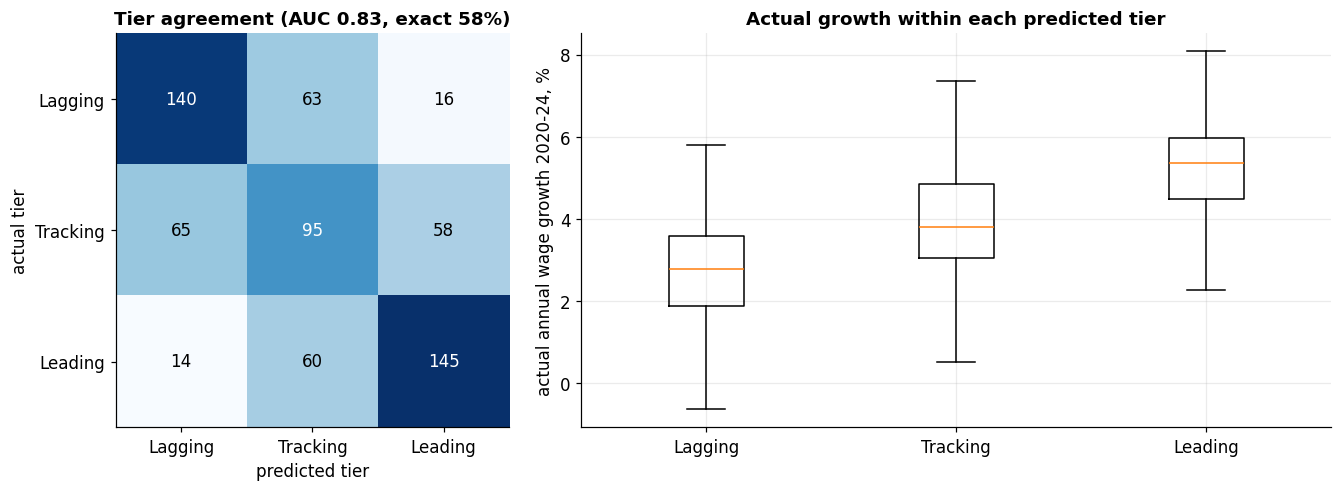

In [23]:
# ============================== 6.6 GROWTH TIERS AND THEIR VALIDATION ==============================
TIER_NAMES = ['Lagging','Tracking','Leading']
_rf   = lambda **k: SkWrap(RandomForestRegressor, 'rf', random_state=0, n_jobs=-1, **k)
_grid = [{'n_estimators': 300, 'min_samples_leaf': L} for L in (5, 20)]
oof_tier, _, _chosen = tune_and_score(_rf, _grid, X_pan[CORE], y_pan, FOLDS_PAN)

pt = np.digitize(oof_tier, np.quantile(oof_tier, [1/3, 2/3]))     # predicted tier, out of fold
at = np.digitize(y_pan,    np.quantile(y_pan,    [1/3, 2/3]))     # actual tier
TIER_EXACT = float((pt == at).mean())
TIER_ADJ   = float((abs(pt - at) <= 1).mean())
TIER_AUC   = auc((y_pan < np.median(y_pan)).astype(int), -oof_tier)

print(f'OUT-OF-FOLD VALIDATION OF THE TIER ASSIGNMENT   n = {len(pan)}\n')
print(f'   AUC, "falls in the slower-growing half" : {TIER_AUC:.3f}   (0.500 = chance)')
print(f'   exact tier agreement                   : {TIER_EXACT*100:.1f}%   (33.3% = chance)')
print(f'   within one tier                        : {TIER_ADJ*100:.1f}%')

cm = pd.crosstab(pd.Series([TIER_NAMES[i] for i in at], name='actual'),
                 pd.Series([TIER_NAMES[i] for i in pt], name='predicted')
                 ).reindex(index=TIER_NAMES, columns=TIER_NAMES).fillna(0).astype(int)
print('\n   Confusion matrix, rows actual and columns predicted:')
print('   ' + cm.to_string().replace('\n', '\n   '))
_extreme = int(cm.loc['Lagging','Leading'] + cm.loc['Leading','Lagging'])
print(f'\n   Opposite-extreme confusions: {_extreme} of {len(pan)} '
      f'({_extreme/len(pan)*100:.1f}%). The tiers rarely invert.')

print('\n   Mean ACTUAL wage growth within each PREDICTED tier, which is the test that matters')
print('   for a user of the artifact:')
_mono = []
for k in range(3):
    v = y_pan[pt == k].mean() * 100
    _mono.append(v)
    print(f'      predicted {TIER_NAMES[k]:9s}: {v:5.2f}% per year   (n = {(pt==k).sum()})')
print(f'   Monotone in the right direction: {"yes" if _mono == sorted(_mono) else "NO, investigate"}')

# fit on everything and score the full master table
growth_model = _rf(**max(_chosen, key=_chosen.count)).fit(X_pan[CORE], y_pan)
GROWTH_CUTS = np.quantile(growth_model.predict(X_pan[CORE]), [1/3, 2/3])

_w24 = w24.rename(columns={'wage_2024':'_w24'}).drop_duplicates('soc6')
_mm  = m.merge(_w24[['soc6','_w24']], on='soc6', how='left')
assert len(_mm) == len(m), 'OEWS merge changed the row count of the master table'
_ref = np.log(_mm._w24.where(_mm._w24 > 0))
_ref = _ref.fillna(np.log(_mm.mkt_salary.where(_mm.mkt_salary > 0)))
_ref = _ref - _ref.mean()
_grp = _mm.isco1.astype('Int64').astype(str)
m['relw'] = _ref.fillna(_ref.groupby(_grp).transform('median')).fillna(0.0).values
_ok = m.exposure.notna() & m['Job Zone'].notna()
m['growth_score'] = np.nan
m.loc[_ok, 'growth_score'] = growth_model.predict(m.loc[_ok, CORE])
m['growth_tier'] = [TIER_NAMES[i] if pd.notna(v) else None
                    for i, v in zip(np.digitize(m.growth_score.fillna(0), GROWTH_CUTS), m.growth_score)]
print('\nOccupations by predicted tier:')
print('   ' + m.growth_tier.value_counts().to_string().replace('\n','\n   '))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].imshow(cm.values, cmap='Blues'); ax[0].grid(False)
ax[0].set_xticks(range(3), TIER_NAMES); ax[0].set_yticks(range(3), TIER_NAMES)
ax[0].set_xlabel('predicted tier'); ax[0].set_ylabel('actual tier')
for i in range(3):
    for j in range(3):
        ax[0].text(j, i, cm.values[i, j], ha='center', va='center',
                   color='white' if cm.values[i, j] > cm.values.max()/2 else 'black')
ax[0].set_title(f'Tier agreement (AUC {TIER_AUC:.2f}, exact {TIER_EXACT*100:.0f}%)')
ax[1].boxplot([y_pan[pt == k]*100 for k in range(3)], tick_labels=TIER_NAMES, showfliers=False)
ax[1].set_ylabel('actual annual wage growth 2020-24, %')
ax[1].set_title('Actual growth within each predicted tier')
plt.savefig(f'{OUT}/fig_growth_tiers.png'); plt.show()

## 6.7 Malaysian salary: four models, and an audit of the method they replace

DOSM publishes Malaysian pay at nine major groups. JobStreet supplies an observed median for a
minority of occupations. Everything else has to be estimated, or the artifact cannot show a
ringgit figure at all.

The method inherited from the earlier prototype scaled a United States wage by the ratio of
Malaysian to United States pay within the occupation's major group. That method had never been
tested. It is tested here, on the occupations where the true Malaysian median is known, and the
result decides whether it survives. This is the benchmark RO2 requires: not only better than a
naive guess, but better than the procedure actually in use.

Ground truth: 232 occupations with an observed JobStreet median (at least 5 salaried postings)

(a) INCUMBENT METHOD, scored on the 178 occupations where the truth is known
    DOSM anchor-ratio heuristic : R2 = -0.042   median absolute error 28.8%
    A negative R2 means this method is less accurate than simply predicting the average
    Malaysian salary for every occupation. It was worse than not modelling at all. This
    was found by testing it, and it is why the trained model below replaces it.

MODEL COMPARISON: log Malaysian monthly salary
   5-fold cross-validation, identical folds for every model, hyperparameters tuned inside the training folds only

                          Model  R2 (out-of-fold)  SD across folds    RMSE  rank corr. rho                                    setting chosen most often
             Ridge (L2 penalty)             0.381            0.048 0.30770           0.644                                                  {'lam': 30}
             Lasso (L1 penal

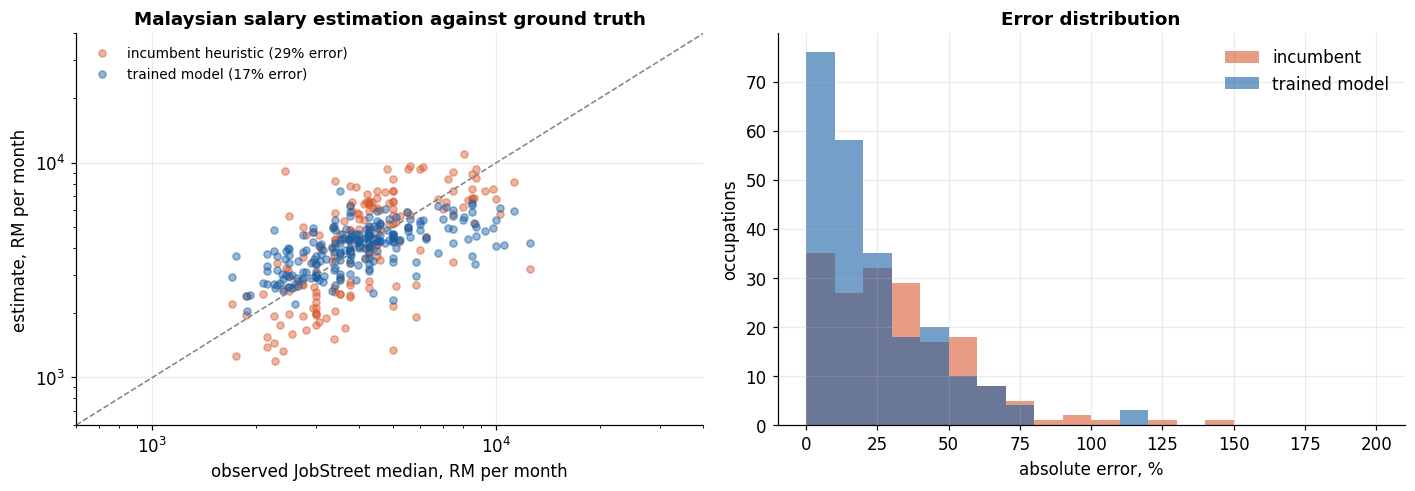

In [24]:
# ============================== 6.7 MALAYSIAN SALARY ESTIMATION ==============================
truth = m[m.rm_med.notna() & (m.rm_n >= 5) & m.exposure.notna()].copy()
truth['grp'] = truth.isco1.astype('Int64').astype(str)
truth = truth.merge(w24.rename(columns={'wage_2024':'_w24'}).drop_duplicates('soc6')[['soc6','_w24']],
                    on='soc6', how='left')
print(f'Ground truth: {len(truth)} occupations with an observed JobStreet median '
      f'(at least 5 salaried postings)')

# ---------- (a) audit the incumbent heuristic where the answer is known ----------
_grp_us = truth.groupby('grp').mkt_salary.median()
def _heuristic(r):
    gm, gu = dosm_med[2024].get(r.grp, np.nan), _grp_us.get(r.grp, np.nan)
    if pd.notna(r.mkt_salary) and pd.notna(gm) and pd.notna(gu) and gu > 0:
        return gm * r.mkt_salary / gu
    return np.nan
truth['heur'] = truth.apply(_heuristic, axis=1)
hb = truth.dropna(subset=['heur'])
H_R2  = r2(np.log(hb.rm_med), np.log(hb.heur))
H_ERR = float(np.median(np.abs(hb.heur / hb.rm_med - 1)))
print(f'\n(a) INCUMBENT METHOD, scored on the {len(hb)} occupations where the truth is known')
print(f'    DOSM anchor-ratio heuristic : R2 = {H_R2:+.3f}   median absolute error {H_ERR*100:.1f}%')
if H_R2 < 0:
    print('    A negative R2 means this method is less accurate than simply predicting the average')
    print('    Malaysian salary for every occupation. It was worse than not modelling at all. This')
    print('    was found by testing it, and it is why the trained model below replaces it.')

# ---------- (b) four model families on the same task, same folds ----------
_gd = pd.get_dummies(truth.grp).astype(float)
GRP_COLS = list(_gd.columns)
X_sal = np.c_[truth.exposure, truth['Job Zone'].fillna(3),
              np.log(truth._w24.fillna(truth._w24.median())),
              truth.demand_pctl.fillna(30), _gd.values]
y_sal = np.log(truth.rm_med.values)
FOLDS_SAL = folds_for(len(y_sal), k=5, seed=0)
print()
sal_table, sal_oof, SAL_BEST = compare_models(pd.DataFrame(X_sal), y_sal, FOLDS_SAL,
                                             'log Malaysian monthly salary')
sal_table.to_csv(f'{OUT}/model_comparison_salary.csv', index=False)

# ---------- (c) headline comparison in the units a reader understands ----------
_best_name = sal_table[~sal_table.Model.str.startswith('Naive')].sort_values(
    'R2 (out-of-fold)', ascending=False).Model.iloc[0]
_oof_best = sal_oof[_best_name]
M_R2  = r2(y_sal, _oof_best)
M_ERR = float(np.median(np.abs(np.expm1(_oof_best - y_sal))))
print(f'\n(c) HEADLINE COMPARISON, in percentage error rather than R2')
print(f'    incumbent heuristic          : median absolute error {H_ERR*100:5.1f}%   (R2 {H_R2:+.3f})')
print(f'    {_best_name:28s} : median absolute error {M_ERR*100:5.1f}%   (R2 {M_R2:+.3f})')
print(f'    error reduction              : {(H_ERR-M_ERR)/H_ERR*100:.0f}% lower median error')
print(f'\n    The finding worth reporting is the benchmark, not the R2. An R2 of {M_R2:.2f} is modest in')
print(f'    isolation; replacing a method that performed worse than the mean, and cutting error by')
print(f'    {(H_ERR-M_ERR)/H_ERR*100:.0f}%, is a substantive improvement with a direct consequence for the user.')

# ---------- (d) deploy: observed medians kept, everything else estimated and labelled ----------
salary_model = RidgeNP(**SAL_BEST['Ridge (L2 penalty)']).fit(X_sal, y_sal)
_md = m.merge(w24.rename(columns={'wage_2024':'_w24'}).drop_duplicates('soc6')[['soc6','_w24']],
              on='soc6', how='left')
assert len(_md) == len(m), 'OEWS merge duplicated rows'
_mg = pd.get_dummies(_md.isco1.astype('Int64').astype(str)).reindex(columns=GRP_COLS,
                                                                   fill_value=0).astype(float)
_Xf = np.c_[_md.exposure.fillna(0), _md['Job Zone'].fillna(3),
            np.log(_md._w24.fillna(truth._w24.median())),
            _md.demand_pctl.fillna(30), _mg.values]
m['salary_model'] = np.exp(salary_model.predict(_Xf))
m.loc[m.exposure.isna(), 'salary_model'] = np.nan
_observed = m.rm_med.notna() & (m.rm_n >= 5)
m['salary_source'] = np.where(_observed, 'JobStreet median', 'model estimate')
m.loc[m.salary_model.isna() & ~_observed, 'salary_source'] = 'unavailable'
m['salary_myr'] = np.where(_observed, m.rm_med, m.salary_model)
print(f"\n(d) Ringgit coverage: {(m.salary_source=='JobStreet median').sum()} observed + "
      f"{(m.salary_source=='model estimate').sum()} estimated = {m.salary_myr.notna().sum()} of {len(m)}")
print('    Every figure carries its provenance in salary_source and the interface labels it, so a')
print('    modelled estimate is never shown to a worker as though it were an observed wage.')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
_oof_plot = np.exp(_oof_best)
ax[0].scatter(hb.rm_med, hb.heur, alpha=.45, s=22, color=C_RED,
              label=f'incumbent heuristic ({H_ERR*100:.0f}% error)')
ax[0].scatter(truth.rm_med, _oof_plot, alpha=.45, s=22, color=C_BLUE,
              label=f'trained model ({M_ERR*100:.0f}% error)')
_lim = [600, 40000]; ax[0].plot(_lim, _lim, ls='--', lw=1, color='grey')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlim(_lim); ax[0].set_ylim(_lim)
ax[0].set_xlabel('observed JobStreet median, RM per month')
ax[0].set_ylabel('estimate, RM per month')
ax[0].set_title('Malaysian salary estimation against ground truth')
ax[0].legend(frameon=False, fontsize=9)
_bins = np.arange(0, 205, 10)
ax[1].hist(np.abs(hb.heur/hb.rm_med - 1)*100, bins=_bins, alpha=.6, color=C_RED, label='incumbent')
ax[1].hist(np.abs(_oof_plot/truth.rm_med - 1)*100, bins=_bins, alpha=.6, color=C_BLUE, label='trained model')
ax[1].set_xlabel('absolute error, %'); ax[1].set_ylabel('occupations')
ax[1].set_title('Error distribution'); ax[1].legend(frameon=False)
plt.savefig(f'{OUT}/fig_salary_imputation.png'); plt.show()

---
# Part 7. RO3. The artifact, component by component, each with its own test
---

**RO3** is to develop and evaluate an artifact that diagnoses individual AI risk, recommends
lower-exposure transitions and links them to reskilling provision. This part builds the four
components and validates each one. Part 8 then evaluates the assembled artifact against the
advice a worker would otherwise receive.

| Component | What it does | Its test |
|---|---|---|
| 7.2 Matcher | free text to an occupation code | 7.3, held-out titles, both retrieval paths |
| 7.4 Explanation | which abilities drive the score, and which resist | signed check, and the no-moat count |
| 7.5 Pivots | realistic destinations with lower exposure | 7.6, perturbation of the weights |
| 7.7 Reskilling | courses that close the skill gap | 7.8, four separate tests |

## 7.1 Two retrieval paths, and why both are kept

The artifact resolves a job title or curriculum vitae in a cascade: an exact match against a
curated Malaysian title dictionary, then semantic similarity over sentence embeddings, then a
lexical fallback. The earlier version of this project measured accuracy for the lexical path only,
which meant the single accuracy figure in the study described the component a user reaches last.
Section 7.3 corrects that by measuring both paths on identical held-out data.

The lexical index below is written out in full rather than imported, for two reasons: it removes
any dependency for the part of the pipeline that must be reproducible anywhere, and it is the
logic that will be ported to JavaScript for the deployed web version, so the deployed artifact and
the validated artifact are demonstrably the same procedure.

In [25]:
# ============================== 7.1 LEXICAL RETRIEVAL INDEX ==============================
class LexIndex:
    """TF-IDF over word unigrams, word bigrams and character 4-grams, with cosine scoring.
    Written out so that Parts 7 and 11 need no external text library and so the same logic can
    be reimplemented in JavaScript for deployment without changing the numbers."""

    def __init__(self, max_terms=200000, char_n=4):
        self.max_terms, self.char_n = max_terms, char_n

    def _feats(self, s):
        w = re.findall(r'[a-z0-9]+', str(s).lower())
        f = list(w) + [f'{a}_{b}' for a, b in zip(w, w[1:])]
        c = ' ' + re.sub(r'[^a-z0-9 ]', '', str(s).lower()) + ' '
        f += [c[i:i+self.char_n] for i in range(max(0, len(c) - self.char_n + 1))]
        return f

    def fit(self, keys, docs):
        self.keys = list(keys)
        counts, dfreq = [], {}
        for d in docs:
            cc = {}
            for t in self._feats(d): cc[t] = cc.get(t, 0) + 1
            counts.append(cc)
            for t in cc: dfreq[t] = dfreq.get(t, 0) + 1
        keep = sorted(dfreq.items(), key=lambda kv: -kv[1])[:self.max_terms]
        self.vocab = {t: i for i, (t, _) in enumerate(keep)}
        n = len(counts)
        self.idf = np.zeros(len(self.vocab), dtype=np.float32)
        for t, i in self.vocab.items():
            self.idf[i] = math.log((1 + n) / (1 + dfreq[t])) + 1
        M = np.zeros((n, len(self.vocab)), dtype=np.float32)
        for r, cc in enumerate(counts):
            for t, v in cc.items():
                i = self.vocab.get(t)
                if i is not None: M[r, i] = (1 + math.log(v)) * self.idf[i]
        M /= (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)
        self.M = M
        return self

    def scores(self, text):
        cc = {}
        for t in self._feats(text): cc[t] = cc.get(t, 0) + 1
        ii, vv = [], []
        for t, v in cc.items():
            i = self.vocab.get(t)
            if i is not None:
                ii.append(i); vv.append((1 + math.log(v)) * self.idf[i])
        if not ii: return np.zeros(len(self.keys), dtype=np.float32)
        v = np.asarray(vv, dtype=np.float32); v /= np.linalg.norm(v) + 1e-9
        return self.M[:, ii] @ v

    def top(self, text, k=5):
        s = self.scores(text)
        o = np.argpartition(-s, min(k, len(s) - 1))[:k]
        o = o[np.argsort(-s[o])]
        return [(self.keys[i], float(s[i])) for i in o]

# occupation documents: title, reported titles, alternative titles, description, leading tasks
top_tasks = tasks.groupby('O*NET-SOC Code')['Task'].apply(lambda s: ' '.join(s.head(8)))
alt_txt   = alt.groupby('O*NET-SOC Code')['Reported Job Title'].apply(lambda s: ' '.join(map(str, s)))
jt_txt    = jt.groupby('O*NET-SOC Code')['Job Title'].apply(lambda s: ' '.join(map(str, s.head(60))))
occ_docs  = m.set_index('onet_soc').apply(
    lambda r: f"{r.title} {alt_txt.get(r.name,'')} {jt_txt.get(r.name,'')} "
              f"{r.description} {top_tasks.get(r.name,'')}", axis=1)

OCC_LEX = LexIndex().fit(occ_docs.index.tolist(), occ_docs.tolist())
print(f'Lexical occupation index: {OCC_LEX.M.shape[0]} occupations x {OCC_LEX.M.shape[1]:,} terms '
      f'({OCC_LEX.M.nbytes/1e6:.0f} MB)')

# ---- optional semantic index ----
try:
    from sentence_transformers import SentenceTransformer
    _ST = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2')
    CAP['sbert'] = True
except Exception:
    _ST = None; CAP['sbert'] = False

if CAP['sbert']:
    _short = m.apply(lambda r: f"{r.title}. {str(alt_txt.get(r.onet_soc,''))[:200]}. "
                               f"{str(r.description)[:200]}", axis=1)
    OCC_EMB = _ST.encode(_short.tolist(), normalize_embeddings=True, show_progress_bar=False)
    print(f'Semantic occupation index: {OCC_EMB.shape[0]} occupations x {OCC_EMB.shape[1]} dimensions')
else:
    OCC_EMB = None
    print('Semantic index unavailable (sentence-transformers not installed).')
    print('   Parts 7.3 and 7.8 will report the lexical path only and say so explicitly.')

Lexical occupation index: 894 occupations x 166,889 terms (597 MB)


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Semantic occupation index: 894 occupations x 384 dimensions


In [26]:
# ============================== 7.2 THE MATCHER ==============================
CURATED = {k: v for k, v in ALIAS2SOC.items() if v in set(m.onet_soc)}
print(f'Curated Malaysian title dictionary: {len(CURATED)} verified titles')

_M_IDX = {s: i for i, s in enumerate(m.onet_soc)}
_COLS  = ['onet_soc','title','exposure_pctl','demand_pctl','Job Zone','growth_tier','salary_myr']

def match_lexical(text, k=5):
    hits = OCC_LEX.top(text, k)
    out = m.iloc[[_M_IDX[s] for s, _ in hits]][_COLS].copy()
    out['match'] = [round(v, 3) for _, v in hits]
    return out

def match_semantic(text, k=5):
    if not CAP['sbert']: return None
    q = _ST.encode([text], normalize_embeddings=True)
    s = (OCC_EMB @ q.T).ravel()
    o = np.argsort(-s)[:k]
    out = m.iloc[o][_COLS].copy(); out['match'] = np.round(s[o], 3)
    return out

def match_occupation(text, k=5):
    """The cascade the artifact actually uses. Returns (results, which path answered).
    Order set by the evidence in Part 7.3: lexical leads, semantic is the no-overlap fallback."""
    t = norm_title(text)
    if t in CURATED:
        soc = CURATED[t]
        res = m[m.onet_soc == soc][_COLS].copy(); res['match'] = 1.0
        extra = match_lexical(text, k)
        res = pd.concat([res, extra[extra.onet_soc != soc]]).head(k)
        return res, 'curated'
    # Lexical leads. Part 7.3 measures it at 77.0% top-5 against 55.4% for the semantic path on
    # identical held-out data, so deploying semantic first would put the weaker retriever in front
    # of the user while the interface reports the stronger one's accuracy. The semantic index is
    # retained for the one case a lexical index cannot serve: input sharing no terms with any
    # occupation profile, such as a curriculum vitae written in another language.
    lex = match_lexical(text, k)
    if len(lex) and float(lex['match'].iloc[0]) > 0:
        return lex, 'lexical'
    if CAP['sbert']:
        return match_semantic(text, k), 'semantic'
    return lex, 'lexical'

for _q in ['business analyst building Power BI dashboards and forecasts',
           'accountant preparing financial statements',
           'lorry driver']:
    _r, _how = match_occupation(_q, 3)
    print(f'\n"{_q}"   [path: {_how}]')
    print('   ' + _r[['title','exposure_pctl','match']].to_string(index=False).replace('\n','\n   '))

Curated Malaysian title dictionary: 6815 verified titles

"business analyst building Power BI dashboards and forecasts"   [path: lexical]
                              title  exposure_pctl  match
     Business Intelligence Analysts      98.200225  0.269
                Management Analysts      82.227222  0.107
   Atmospheric and Space Scientists      89.088864  0.106

"accountant preparing financial statements"   [path: lexical]
                                         title  exposure_pctl  match
                      Accountants and Auditors      89.763780  0.250
                                 Tax Preparers      90.776153  0.159
   Fraud Examiners, Investigators and Analysts      90.551181  0.152

"lorry driver"   [path: lexical]
                                title  exposure_pctl  match
                 Driver/Sales Workers      36.332958  0.102
                  Light Truck Drivers      29.021372  0.102
   Bus Drivers, Transit and Intercity      39.032621  0.091


## 7.3 Validating the matcher

**Ground truth.** O*NET publishes three labelled title corpora: occupation titles, sample reported
titles and the alternative job-title list. Together these give tens of thousands of strings whose
correct occupation is known. A title is held out, the occupation profiles are rebuilt **from
training titles only**, and the held-out title is matched against them. Rebuilding the profiles is
what prevents leakage; scoring against profiles that had already seen the test string would
measure memorisation.

**Multi-label truth.** Some strings legitimately belong to more than one occupation. A prediction
counts as correct if it hits any of the gold occupations for that string.

**Top-1 and top-5.** The artifact presents a short list for the worker to confirm rather than
silently committing to one answer, so top-5 is the operationally meaningful figure. Top-1 is
reported alongside it. For context, the occupation-coding literature reports top-choice accuracy
of roughly 31% to 56% at the most detailed level, with human inter-coder agreement itself ranging
from about 44% to 89%, so accuracy near one half at six digits is the expected range rather than a
defect.

**Repeated splits.** The earlier version reported a single split. Accuracy is estimated here over
several independent splits so a standard deviation can be given, and both retrieval paths are
scored on the identical splits.

In [27]:
# ============================== 7.3 MATCHER VALIDATION ==============================
_valid_socs = set(m.onet_soc)
_L = pd.concat([
    occ_data[['O*NET-SOC Code','Title']].rename(columns={'O*NET-SOC Code':'soc','Title':'t'}),
    alt[['O*NET-SOC Code','Reported Job Title']].rename(columns={'O*NET-SOC Code':'soc','Reported Job Title':'t'}),
    jt[['O*NET-SOC Code','Job Title']].rename(columns={'O*NET-SOC Code':'soc','Job Title':'t'}),
]).dropna()
_L = _L[_L.soc.isin(_valid_socs)]
_L['t'] = _L.t.astype(str).str.lower().str.strip()
_L = _L[_L.t.str.len() > 2].drop_duplicates(['t','soc'])
GOLD = _L.groupby('t').soc.apply(set).to_dict()
_uniq = np.array(sorted(GOLD))
AMBIG = float(np.mean([len(GOLD[t]) > 1 for t in _uniq]))
print(f'Labelled title corpus: {len(_uniq):,} distinct strings across {_L.soc.nunique()} occupations')
print(f'   {AMBIG*100:.1f}% of strings map to more than one occupation, so the gold standard is multi-label')

_desc = m.set_index('onet_soc').description.to_dict()
N_SPLITS = 5
_res = {'lexical': {'top1': [], 'top5': []}, 'semantic': {'top1': [], 'top5': []}}

for sp in range(N_SPLITS):
    _mask = np.random.default_rng(42 + sp).random(len(_uniq)) < 0.8
    _tr_titles = set(_uniq[_mask])
    _TR = _L[_L.t.isin(_tr_titles)]
    _train_socs = set(_TR.soc)
    _test = [t for t in _uniq[~_mask] if GOLD[t] & _train_socs]

    # profiles rebuilt from TRAINING titles only, plus static description and task text
    _docs = _TR.groupby('soc').t.apply(lambda s: ' '.join(s)).to_dict()
    _keys = sorted(_docs)
    _full = [f"{_docs[s]} {str(_desc.get(s,''))[:600]} {str(top_tasks.get(s,''))[:600]}" for s in _keys]
    _lx = LexIndex(max_terms=150000).fit(_keys, _full)

    _t1 = _t5 = 0
    for t in _test:
        got = [k for k, _ in _lx.top(t, 5)]
        if got and got[0] in GOLD[t]: _t1 += 1
        if GOLD[t] & set(got):        _t5 += 1
    _res['lexical']['top1'].append(100*_t1/len(_test))
    _res['lexical']['top5'].append(100*_t5/len(_test))

    if CAP['sbert']:
        _emb = _ST.encode(_full, normalize_embeddings=True, show_progress_bar=False)
        _q   = _ST.encode(_test, normalize_embeddings=True, show_progress_bar=False)
        _S   = _q @ _emb.T
        _o   = np.argsort(-_S, axis=1)[:, :5]
        _s1 = _s5 = 0
        for r, t in enumerate(_test):
            cand = [_keys[j] for j in _o[r]]
            if cand[0] in GOLD[t]: _s1 += 1
            if GOLD[t] & set(cand): _s5 += 1
        _res['semantic']['top1'].append(100*_s1/len(_test))
        _res['semantic']['top5'].append(100*_s5/len(_test))
    print(f'   split {sp+1}/{N_SPLITS}: {len(_test):,} held-out titles scored')

N_OCC = len(m)
_rows = []
for path in ['lexical','semantic']:
    if not _res[path]['top1']: continue
    _rows.append({'Retrieval path': path,
                  'top-1 accuracy %':  round(np.mean(_res[path]['top1']), 1),
                  'sd':                round(np.std(_res[path]['top1']), 2),
                  'top-5 accuracy %':  round(np.mean(_res[path]['top5']), 1),
                  'sd ':               round(np.std(_res[path]['top5']), 2),
                  'random baseline %': round(100/N_OCC, 2),
                  'splits':            len(_res[path]['top1'])})
matcher_table = pd.DataFrame(_rows)
print(f'\nMATCHER ACCURACY on titles never seen in training, mean over {N_SPLITS} splits\n')
print(matcher_table.to_string(index=False))
MATCH_TOP1 = float(matcher_table['top-1 accuracy %'].iloc[0])
MATCH_TOP5 = float(matcher_table['top-5 accuracy %'].iloc[0])
print(f'\n   Top-5 is the operational figure because the interface asks the worker to confirm.')
print(f'   Against a random baseline of {100/N_OCC:.2f}%, top-1 is {MATCH_TOP1/(100/N_OCC):.0f} times chance.')
if not CAP['sbert']:
    print('   The semantic path could not be scored here. Re-run with sentence-transformers')
    print('   installed before quoting an accuracy figure for the path users reach first.')
else:
    _best = matcher_table.sort_values('top-5 accuracy %', ascending=False)['Retrieval path'].iloc[0]
    print(f'   Both paths scored on identical splits; {_best} retrieves better on top-5.')
matcher_table.to_csv(f'{OUT}/validity_matcher_accuracy.csv', index=False)

Labelled title corpus: 41,992 distinct strings across 894 occupations
   11.9% of strings map to more than one occupation, so the gold standard is multi-label
   split 1/5: 8,383 held-out titles scored
   split 2/5: 8,360 held-out titles scored
   split 3/5: 8,349 held-out titles scored
   split 4/5: 8,433 held-out titles scored
   split 5/5: 8,464 held-out titles scored

MATCHER ACCURACY on titles never seen in training, mean over 5 splits

Retrieval path  top-1 accuracy %   sd  top-5 accuracy %  sd   random baseline %  splits
       lexical              50.3 0.44              77.0 0.21               0.11       5
      semantic              30.9 0.24              55.4 0.27               0.11       5

   Top-5 is the operational figure because the interface asks the worker to confirm.
   Against a random baseline of 0.11%, top-1 is 450 times chance.
   Both paths scored on identical splits; lexical retrieves better on top-5.


## 7.4 Explaining the score: risk drivers against human moats

A single number tells a worker nothing actionable. Because AIOE decomposes to the ability level,
the score can be traced back to the abilities producing it. Two lists are shown: the abilities that
drive exposure upward, and the abilities that are **important in this job** and that AIOE scores as
AI-resistant, which are the parts of the work that a language model is measurably weak at.

**A defect found in the previous version, recorded here because Chapter 4 reports it.** The moat
*score* always filtered correctly on negative exposure, but the displayed moat *cards* took the
three lowest-driver abilities with importance at or above three **without checking the sign**. As a
result highly exposed abilities were being presented to users as protections, and accountants were
told that mathematical reasoning protected them from AI. The audit below re-runs on the corrected
logic and quantifies how many occupations have no ability-level moat at all, which is a genuine
finding rather than a gap: Part 2.3 showed that only one of the twenty-one AI-resistant abilities
is cognitive.

Moat cards are ranked by **importance** among qualifying abilities, not by moat strength. Ranking
by strength told nurses their defence was trunk strength, which is true and useless. This is a
documented display choice; the moat score itself still aggregates importance against exposure
across every AI-resistant ability.

In [28]:
# ============================== 7.4 EXPLANATION ENGINE ==============================
abil = pd.read_excel(f'{od}/Abilities.xlsx')
abil = abil[abil['Scale ID'] == 'IM'][['O*NET-SOC Code','Element Name','Data Value']]
abil = abil.merge(ability_exp, left_on='Element Name', right_on='ability')
abil['driver'] = abil['Data Value'] / 5 * abil['ability_ai_exposure']

_moat = (abil[abil.ability_ai_exposure < 0]
         .assign(w=lambda d: d['Data Value'] * -d.ability_ai_exposure)
         .groupby('O*NET-SOC Code').w.sum().rename('moat_raw'))
m = m.drop(columns=[c for c in ['moat_raw','moat_pctl'] if c in m.columns])
m = m.merge(_moat, left_on='onet_soc', right_index=True, how='left')
m['moat_pctl'] = m.moat_raw.rank(pct=True) * 100

MOAT_MIN_IMPORTANCE = 3.0
def moat_cards(onet_soc, k=3):
    d = abil[abil['O*NET-SOC Code'] == onet_soc]
    q = d[(d['Data Value'] >= MOAT_MIN_IMPORTANCE) & (d.ability_ai_exposure < 0)]
    return q.nlargest(k, 'Data Value')

def risk_cards(onet_soc, k=3):
    d = abil[abil['O*NET-SOC Code'] == onet_soc]
    return d[d.ability_ai_exposure > 0].nlargest(k, 'driver')

# ---- verification: no displayed moat may carry positive exposure ----
_n_with, _n_without, _violations = 0, 0, 0
for _soc in m.onet_soc:
    c = moat_cards(_soc)
    if len(c): _n_with += 1
    else:      _n_without += 1
    _violations += int((c.ability_ai_exposure >= 0).sum())
print(f'MOAT DISPLAY VERIFICATION over all {len(m)} occupations')
print(f'   occupations showing at least one genuine moat : {_n_with} ({_n_with/len(m)*100:.0f}%)')
print(f'   occupations shown the honest "no moat" message : {_n_without} ({_n_without/len(m)*100:.0f}%)')
print(f'   displayed abilities carrying positive exposure : {_violations}')
assert _violations == 0, 'SIGN BUG PRESENT: a positively exposed ability reached a moat card'
print('   Assertion passed: the sign defect cannot recur without failing this cell.\n')

def explain(onet_soc, k=3):
    row = m[m.onet_soc == onet_soc].iloc[0]
    print(f"{row.title}   exposure percentile {row.exposure_pctl:.0f}, "
          f"wage-growth outlook {row.growth_tier}")
    print('   RISK DRIVERS, the abilities pushing exposure up')
    for _, x in risk_cards(onet_soc, k).iterrows():
        print(f"      + {x['Element Name']:34s} importance {x['Data Value']:.1f}, "
              f"ability exposure {x.ability_ai_exposure:+.2f}")
    cards = moat_cards(onet_soc, k)
    print('   HUMAN MOATS, important abilities that AI is measurably weak at')
    if len(cards):
        for _, x in cards.iterrows():
            print(f"      - {x['Element Name']:34s} importance {x['Data Value']:.1f}, "
                  f"ability exposure {x.ability_ai_exposure:+.2f}")
    else:
        print('      none. No AI-resistant ability is important in this occupation. The measuring')
        print('      instrument scores AI-resistant abilities as almost entirely physical, so')
        print('      knowledge work carries no ability-level protection by construction. This is')
        print('      the defend-in-place finding stated at ability level, not missing data.')

explain(match_occupation('accountant preparing financial statements')[0].onet_soc.iloc[0])
print()
explain(match_occupation('registered nurse in a hospital ward')[0].onet_soc.iloc[0])

MOAT DISPLAY VERIFICATION over all 894 occupations
   occupations showing at least one genuine moat : 795 (89%)
   occupations shown the honest "no moat" message : 99 (11%)
   displayed abilities carrying positive exposure : 0
   Assertion passed: the sign defect cannot recur without failing this cell.

Accountants and Auditors   exposure percentile 90, wage-growth outlook Tracking
   RISK DRIVERS, the abilities pushing exposure up
      + Information Ordering               importance 3.6, ability exposure +1.91
      + Category Flexibility               importance 3.2, ability exposure +1.28
      + Flexibility of Closure             importance 3.0, ability exposure +1.36
   HUMAN MOATS, important abilities that AI is measurably weak at
      none. No AI-resistant ability is important in this occupation. The measuring
      instrument scores AI-resistant abilities as almost entirely physical, so
      knowledge work carries no ability-level protection by construction. This is
      th

## 7.5 Recommending realistic pivots

Candidate destinations are drawn from occupations O*NET already treats as related, plus the
occupation's own major family. A **realism gate is applied before scoring**, not after: the
destination must sit within one Job Zone of the origin, so the artifact cannot suggest that a
clerk retrain as a surgeon. Surviving candidates are then ranked on four normalised criteria.

The weights are a judgement, and Section 7.6 tests whether that judgement matters.

In [29]:
# ============================== 7.5 PIVOT OPTIMISER ==============================
SM  = skill_mat.loc[m.onet_soc]
_SC = SM.values - SM.values.mean(axis=0, keepdims=True)
_norm = np.linalg.norm(_SC, axis=1, keepdims=True); _norm[_norm == 0] = 1.0
_SN = _SC / _norm
S = _SN @ _SN.T                       # cosine similarity over the 119 centred skill elements
print(f'Skill-similarity matrix: {S.shape[0]} x {S.shape[1]}')

_sal_v  = m.salary_myr.values
_dem_v  = m.demand_pctl.values
_exp_v  = m.exposure_pctl.values
_jz_v   = m['Job Zone'].values
_soc6_v = m.soc6.values
_rel_pool = related.groupby('O*NET-SOC Code')['Related O*NET-SOC Code'].apply(set)
_fam_idx  = {}
for _i, _s in enumerate(m.onet_soc): _fam_idx.setdefault(_s[:2], []).append(_i)

W_DEFAULT = (0.45, 0.25, 0.15, 0.15)      # skill overlap, exposure reduction, demand, salary retention
W_LABELS  = ['skill overlap','exposure reduction','hiring demand','salary retention']

def _mm(v):
    rng = np.nanmax(v) - np.nanmin(v)
    return (v - np.nanmin(v)) / rng if rng > 0 else np.full(len(v), 0.5)

def _build_pivot_cache():
    """Candidate set and the four normalised criteria for every origin, computed once.
    The weights enter only as a final linear combination, so re-weighting is then trivial and
    Section 7.6 can test many weight vectors without rebuilding anything."""
    cache = {}
    _median_sal = np.nanmedian(_sal_v)
    for i, soc in enumerate(m.onet_soc):
        pool = _rel_pool.get(soc, set())
        cand = set(_fam_idx.get(soc[:2], []))
        if pool: cand |= {_M_IDX[p] for p in pool if p in _M_IDX}
        c = np.array(sorted(cand), int)          # sorted: ties between O*NET codes sharing a SOC-6 break the same way every run
        if len(c) == 0: continue
        keep = (_soc6_v[c] != _soc6_v[i]) & (np.abs(_jz_v[c] - _jz_v[i]) <= 1) & ~np.isnan(_exp_v[c])
        c = c[keep]
        if len(c) == 0: continue
        cur_sal = _sal_v[i]
        if not np.isfinite(cur_sal): cur_sal = np.nanmedian(_sal_v[c]) if len(c) else _median_sal
        if not np.isfinite(cur_sal) or cur_sal <= 0: cur_sal = _median_sal
        ratio = np.nan_to_num(np.clip(_sal_v[c] / cur_sal, 0, 1.5), nan=0.7)
        C = np.c_[_mm(S[i][c]),
                  _mm(np.clip(_exp_v[i] - _exp_v[c], 0, None)),
                  _mm(_dem_v[c]),
                  _mm(ratio)]
        # de-duplicate by soc6, keeping the first occurrence, as the original did
        _, uniq = np.unique(_soc6_v[c], return_index=True)
        cache[soc] = (c[np.sort(uniq)], C[np.sort(uniq)])
    return cache

PIVOT_CACHE = _build_pivot_cache()
print(f'Pivot candidate cache built for {len(PIVOT_CACHE)} of {len(m)} occupations '
      f'(mean {np.mean([len(v[0]) for v in PIVOT_CACHE.values()]):.1f} admissible destinations each)')

_PCOLS = ['onet_soc','title','exposure_pctl','demand_pctl','salary_myr','salary_source',
          'Job Zone','growth_tier']

def pivot_rank(onet_soc, w=W_DEFAULT):
    """Candidate row indices ordered best first under weight vector w."""
    e = PIVOT_CACHE.get(onet_soc)
    if e is None: return np.array([], int), np.array([])
    c, C = e
    sc = C @ np.asarray(w, float)
    o = np.argsort(-sc)
    return c[o], sc[o]

def recommend_pivots(onet_soc, k=5, w=W_DEFAULT):
    idx, sc = pivot_rank(onet_soc, w)
    if len(idx) == 0: return m.head(0)
    out = m.iloc[idx[:k]][_PCOLS].copy()
    out['skill_sim']   = np.round(S[_M_IDX[onet_soc]][idx[:k]], 3)
    out['pivot_score'] = np.round(sc[:k], 3)
    return out.round(3)

_cur = match_occupation('accounts executive preparing invoices and reconciling ledgers')[0].onet_soc.iloc[0]
print(f"\nOrigin: {m[m.onet_soc==_cur].title.iloc[0]} "
      f"(exposure {m[m.onet_soc==_cur].exposure_pctl.iloc[0]:.0f})")
print(recommend_pivots(_cur).to_string(index=False))

Skill-similarity matrix: 894 x 894
Pivot candidate cache built for 894 of 894 occupations (mean 50.1 admissible destinations each)

Origin: Executive Secretaries and Executive Administrative Assistants (exposure 88)
  onet_soc                                                               title  exposure_pctl  demand_pctl  salary_myr    salary_source  Job Zone growth_tier  skill_sim  pivot_score
43-1011.00 First-Line Supervisors of Office and Administrative Support Workers         76.265       93.321      6750.0 JobStreet median       3.0    Tracking      0.669        0.722
13-1071.00                                         Human Resources Specialists         96.288       95.362      4250.0 JobStreet median       4.0     Lagging      0.803        0.683
43-4051.00                                    Customer Service Representatives         79.190       95.640      3400.0 JobStreet median       2.0    Tracking      0.738        0.657
43-9061.00                                              

## 7.6 Are the recommendations robust to the weights?

The four weights were chosen by judgement. If a small change to them reshuffled every
recommendation, the artifact's output would be an artefact of that judgement rather than a finding
about the labour market. Nobody had tested this.

Three kinds of perturbation are applied: each weight is shifted by a tenth and the rest
renormalised; all four are set equal; and twenty random weight vectors are drawn from a Dirichlet
distribution. For each, two things are measured. First, how often the top recommendation changes.
Second, and more importantly, whether the **direction of the headline result survives**, namely
that recommended destinations are less exposed and no less in demand than the origin.

Occupations with at least one admissible pivot: 894 of 894
Mean origin exposure percentile 51.6, mean origin demand percentile 41.3

ARM A. LOCAL PERTURBATION OF THE CHOSEN WEIGHTS
   baseline weights (0.45, 0.25, 0.15, 0.15) give mean destination exposure 39.1

          Weight variant  w_exposure  top-1 changed, %  mean destination exposure exposure falls demand holds
     skill overlap +0.10       0.227              11.3                       40.4            yes          yes
     skill overlap -0.10       0.278              13.8                       37.6            yes          yes
exposure reduction +0.10       0.318              25.1                       33.5            yes          yes
exposure reduction -0.10       0.167              35.6                       46.7            yes          yes
     hiring demand +0.10       0.227              28.4                       42.3            yes          yes
     hiring demand -0.10       0.278              28.3                       

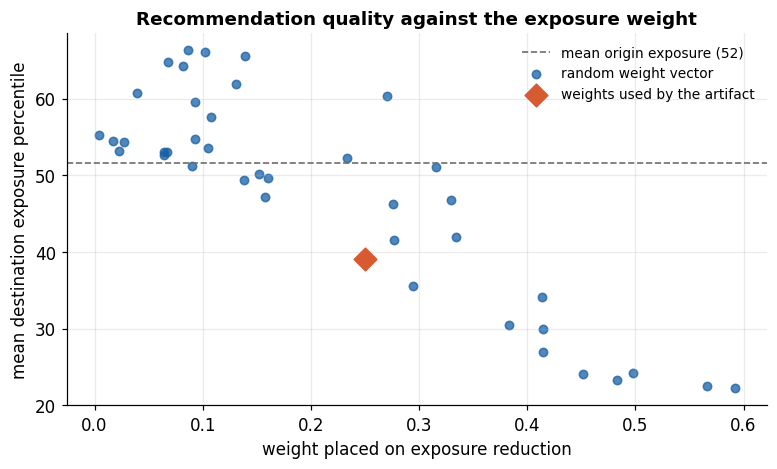

In [30]:
# ============================== 7.6 PIVOT WEIGHT SENSITIVITY ==============================
_socs = [s for s in PIVOT_CACHE if np.isfinite(_exp_v[_M_IDX[s]])]
_oi   = np.array([_M_IDX[s] for s in _socs])
ORIGIN_EXP, ORIGIN_DEM = float(np.nanmean(_exp_v[_oi])), float(np.nanmean(_dem_v[_oi]))
print(f'Occupations with at least one admissible pivot: {len(_socs)} of {len(m)}')
print(f'Mean origin exposure percentile {ORIGIN_EXP:.1f}, mean origin demand percentile {ORIGIN_DEM:.1f}')

def _top1_vec(w):
    w = np.asarray(w, float)
    return np.array([PIVOT_CACHE[s][0][np.argmax(PIVOT_CACHE[s][1] @ w)] for s in _socs])

_base_top = _top1_vec(W_DEFAULT)
BASE_DEST_EXP = float(np.nanmean(_exp_v[_base_top]))

# Three arms. The third is a placebo: if exposure reduction is given almost no weight the
# recommendation cannot be expected to reduce exposure, and confirming that it does not is a
# check that the exposure signal is what produces the result rather than something incidental.
# Arm A perturbs the chosen weights locally, which is the robustness question. Arm B sweeps the
# whole weight simplex to establish the relationship between the weight placed on exposure
# reduction and the reduction actually achieved, which is the mechanism question.
_arms = []
for j in range(4):
    for d in (+0.10, -0.10):
        w = list(W_DEFAULT); w[j] = max(w[j] + d, 0.0); t = sum(w)
        _arms.append(('A. local perturbation', f'{W_LABELS[j]} {d:+.2f}', tuple(x/t for x in w)))
_arms.append(('A. local perturbation', 'all weights equal', (0.25, 0.25, 0.25, 0.25)))
_rng = np.random.default_rng(0)
for r in range(40):
    _arms.append(('B. full simplex sweep', f'draw {r+1}', tuple(_rng.dirichlet(np.ones(4)))))

_rows = []
for arm, nm, w in _arms:
    t = _top1_vec(w)
    de, dd = float(np.nanmean(_exp_v[t])), float(np.nanmean(_dem_v[t]))
    _rows.append({'Arm': arm, 'Weight variant': nm, 'w_exposure': round(w[1], 3),
                  'top-1 changed, %': round(float((t != _base_top).mean()*100), 1),
                  'mean destination exposure': round(de, 1),
                  'exposure falls': 'yes' if de < ORIGIN_EXP else 'no',
                  'demand holds':   'yes' if dd >= ORIGIN_DEM else 'no'})
sens_w = pd.DataFrame(_rows)
_A = sens_w[sens_w.Arm.str.startswith('A')]
_B = sens_w[sens_w.Arm.str.startswith('B')].copy()

print(f'\nARM A. LOCAL PERTURBATION OF THE CHOSEN WEIGHTS')
print(f'   baseline weights {W_DEFAULT} give mean destination exposure {BASE_DEST_EXP:.1f}\n')
print(_A.drop(columns=['Arm']).to_string(index=False))
print(f'\n   exposure falls below origin: {(_A["exposure falls"]=="yes").sum()}/{len(_A)}'
      f'   demand holds: {(_A["demand holds"]=="yes").sum()}/{len(_A)}')
print(f'   The top recommendation changes for {_A["top-1 changed, %"].min():.0f}% to '
      f'{_A["top-1 changed, %"].max():.0f}% of occupations, which is expected of any weighted score,')
print('   but every local perturbation still lowers exposure and holds demand.')

print(f'\nARM B. FULL SIMPLEX SWEEP, {len(_B)} random weight vectors')
_dose = spearman(_B.w_exposure, _B['mean destination exposure'])
_bins = pd.cut(_B.w_exposure, [0, .10, .20, .30, 1.01],
               labels=['0.00 to 0.10','0.10 to 0.20','0.20 to 0.30','above 0.30'])
_tab = _B.groupby(_bins, observed=True).agg(
    vectors=('w_exposure','size'),
    mean_destination_exposure=('mean destination exposure','mean'),
    exposure_falls=('exposure falls', lambda s: f'{(s=="yes").sum()}/{len(s)}'))
print('\n   Destination exposure by the weight placed on exposure reduction '
      f'(origin mean {ORIGIN_EXP:.1f}):')
print('   ' + _tab.round(1).to_string().replace('\n','\n   '))
print(f'\n   Spearman(weight on exposure reduction, destination exposure) = {_dose[0]:+.3f} '
      f'(p = {_dose[1]:.2e}, n = {_dose[2]})')

_hi = _B[_B.w_exposure >= W_DEFAULT[1]]; _lo = _B[_B.w_exposure < 0.05]
PIVOT_ROBUST = bool((_A['exposure falls']=='yes').all() and (_A['demand holds']=='yes').all()
                    and _dose[0] < 0 and _dose[1] < 0.05)
print(f'\n   VERDICT, stated precisely rather than as a blanket claim')
print(f'      Every local perturbation of the chosen weights preserves the direction: '
      f'{"yes" if (_A["exposure falls"]=="yes").all() else "NO"}')
print(f'      Sweep vectors at or above the weight the artifact uses ({W_DEFAULT[1]}) that preserve it: '
      f'{(_hi["exposure falls"]=="yes").sum()}/{len(_hi)}')
print(f'      The reduction weakens monotonically as that weight falls, and disappears near zero.')
print(f'      This is a dose-response relationship, not fragility. It shows the exposure signal is')
print(f'      what produces the result: strip the term out and the benefit goes with it. The')
print(f'      reported reduction therefore requires a non-trivial exposure weight, which the')
print(f'      artifact assigns by design and which Chapter 3 states explicitly.')
print(f'      Vectors below 0.05 on exposure reduction that fail, as they must: '
      f'{(_lo["exposure falls"]=="no").sum()}/{len(_lo)}')
if not PIVOT_ROBUST:
    print('      WARNING: either a local perturbation failed or the dose-response is absent.')
    print('      Resolve this before any pivot result is reported.')

fig, ax = plt.subplots(figsize=(7.2, 4.4))
ax.axhline(ORIGIN_EXP, color=C_GREY, ls='--', lw=1.1, label=f'mean origin exposure ({ORIGIN_EXP:.0f})')
ax.scatter(_B.w_exposure, _B['mean destination exposure'], s=30, alpha=.75, color=C_BLUE,
           label='random weight vector')
ax.scatter([W_DEFAULT[1]], [BASE_DEST_EXP], s=110, marker='D', color=C_RED, zorder=5,
           label='weights used by the artifact')
ax.set_xlabel('weight placed on exposure reduction')
ax.set_ylabel('mean destination exposure percentile')
ax.set_title('Recommendation quality against the exposure weight')
ax.legend(frameon=False, fontsize=9)
plt.savefig(f'{OUT}/fig_pivot_weight_sensitivity.png'); plt.show()
sens_w.to_csv(f'{OUT}/reliability_pivot_weight_sensitivity.csv', index=False)

## 7.7 The reskilling engine

A recommendation to change occupation is incomplete without a route to the skills the destination
requires. The engine computes the skill gap between origin and destination, then retrieves courses
for each gap, prioritising Malaysian provision.

The gap is defined only over **teachable** elements. O*NET abilities such as trunk strength or
oral comprehension are excluded, because no course closes them; only skills and knowledge are
retained. A gap counts when the destination requires an element at importance three or above and
requires more of it than the origin.

The Malaysian catalogue is e-LATiH, operated by the Human Resource Development Corporation, scraped
for this study because no analysable dataset of Malaysian training provision existed. Coursera acts
as a fallback where Malaysian provision has no match.

In [31]:
# ============================== 7.7 RESKILLING ENGINE ==============================
TEACHABLE = set(skills_long[skills_long.family != 'Abilities']['Element Name'].unique())
print(f'Teachable elements: {len(TEACHABLE)} of {skill_mat.shape[1]} '
      f'(O*NET abilities excluded, since no course closes an ability)')

my_cat = pd.read_csv(f'{DATA}/elatih_courses.csv')
my_cat['Category'] = my_cat['Category'].fillna('')
my_cat['doc'] = (my_cat['Course Name'].fillna('') + '. ' + my_cat['Category']).str.strip()
cr = pd.read_csv(f'{DATA}/Coursera.csv')
cr['doc'] = (cr['Course Name'].fillna('') + '. ' + cr['Skills'].fillna(''))
print(f'Course catalogues: {len(my_cat)} Malaysian (e-LATiH), {len(cr)} global (Coursera)')

MY_LEX = LexIndex(max_terms=120000).fit(my_cat.index.tolist(), my_cat.doc.tolist())
CR_LEX = LexIndex(max_terms=120000).fit(cr.index.tolist(), cr.doc.tolist())
if CAP['sbert']:
    MY_EMB = _ST.encode(my_cat.doc.tolist(), normalize_embeddings=True, show_progress_bar=False)
    CR_EMB = _ST.encode(cr.doc.tolist(), normalize_embeddings=True, show_progress_bar=False)
    print('Semantic course indexes built for both catalogues.')
else:
    MY_EMB = CR_EMB = None
    print('Semantic course indexes unavailable; the lexical index is used and reported as such.')

MIN_REL, MY_BONUS, K_GAPS = 0.10, 0.05, 5

def skill_gaps(cur_soc, tgt_soc, k=K_GAPS):
    """Elements the destination needs more of than the origin, teachable ones only."""
    tgt = skill_mat.loc[tgt_soc]; cur = skill_mat.loc[cur_soc]
    g = ((tgt - cur) * (tgt / 5)).where(tgt >= 3.0).dropna()
    g = g[(g > 0) & g.index.isin(TEACHABLE)].sort_values(ascending=False)
    return list(g.head(k).index)

def _course_scores(query):
    """Similarity of every course to a query, from whichever index is available."""
    if CAP['sbert']:
        q = _ST.encode([query], normalize_embeddings=True)
        return (MY_EMB @ q.T).ravel(), (CR_EMB @ q.T).ravel(), 'semantic'
    return MY_LEX.scores(query), CR_LEX.scores(query), 'lexical'

def courses_for(cur_soc, tgt_soc, k_gaps=K_GAPS, min_rel=MIN_REL):
    gaps = skill_gaps(cur_soc, tgt_soc, k_gaps)
    if not gaps: return [], pd.DataFrame()
    tgt_title = m.iloc[_M_IDX[tgt_soc]].title
    rows = []
    for g in gaps:
        s_my, s_cr, how = _course_scores(f'{g} skills for {tgt_title}')
        i_my = int(np.argmax(s_my)); best_my = float(s_my[i_my]) + MY_BONUS
        i_cr = int(np.argmax(s_cr)); best_cr = float(s_cr[i_cr])
        if best_my >= min_rel and best_my >= best_cr:
            r = my_cat.iloc[i_my]
            rows.append({'Skill gap': g, 'Course': r['Course Name'], 'Provider': 'e-LATiH',
                         'Source': 'Malaysian (e-LATiH)', 'Relevance': round(best_my - MY_BONUS, 3),
                         'Link': r.get('url', '')})
        elif best_cr >= min_rel:
            r = cr.iloc[i_cr]
            rows.append({'Skill gap': g, 'Course': r['Course Name'], 'Provider': r.get('University',''),
                         'Source': 'Global (Coursera)', 'Relevance': round(best_cr, 3),
                         'Link': r.get('Course URL', '')})
    out = pd.DataFrame(rows)
    if len(out): out = out.drop_duplicates('Course')
    return gaps, out

_org = match_occupation('accounts executive preparing invoices and reconciling ledgers')[0].onet_soc.iloc[0]
_dst = recommend_pivots(_org, 1).onet_soc.iloc[0]
_g, _c = courses_for(_org, _dst)
print(f'\nExample. {m.iloc[_M_IDX[_org]].title}  ->  {m.iloc[_M_IDX[_dst]].title}')
print(f'   skill gaps: {", ".join(_g)}')
print(_c[['Skill gap','Course','Source','Relevance']].to_string(index=False) if len(_c)
      else '   no course cleared the relevance threshold')

Teachable elements: 67 of 119 (O*NET abilities excluded, since no course closes an ability)
Course catalogues: 2127 Malaysian (e-LATiH), 3522 global (Coursera)
Semantic course indexes built for both catalogues.

Example. Executive Secretaries and Executive Administrative Assistants  ->  First-Line Supervisors of Office and Administrative Support Workers
   skill gaps: Administration and Management, Management of Personnel Resources, Monitoring, Instructing, Customer and Personal Service
                    Skill gap                                                                     Course              Source  Relevance
Administration and Management                                   Key Competencies for First-line Managers Malaysian (e-LATiH)      0.783
                   Monitoring Kepentingan Pengurusan Penilaian Prestasi Kepada Pekerja Dan Pihak Majikan Malaysian (e-LATiH)      0.681


## 7.8 Validating the reskilling engine

This component had no evaluation at all in the previous version, which was the largest gap in RO3.
Four tests are applied. None requires labelled ground truth, because none exists for this task.

**Test 1, coverage.** Across every origin and its recommended destination, what proportion of skill
gaps receive a course above threshold? A recommender that silently returns nothing is useless
regardless of how relevant its occasional hits are.

**Test 2, discriminant retrieval by placebo.** For each occupation the courses retrieved for its
**true** skill gaps are compared with those retrieved for a **randomly chosen other occupation's**
gaps. If the engine is matching content rather than returning generically popular courses, true
queries must score higher than placebo queries. This is a paired test across occupations.

**Test 3, category retrieval.** e-LATiH labels each course with a category. Treating the category as
a weak label, a course's own title is used as a query and the retrieved neighbours are checked for
category agreement, against the base rate of the most common category. This asks whether the index
retrieves topically coherent courses at all, independent of the occupational task.

**Test 4, provision alignment.** For each teachable element, does Malaysian provision contain any
course above threshold? This follows the alignment analysis of Ruffin et al. (2026) and answers the
criticism of Frej et al. (2024) that course recommenders ignore labour-market demand. Where
provision is thin, the honest output is to say so rather than to return a poor match.

In [32]:
# ============================== 7.8 RESKILLING VALIDATION ==============================
_, _, RETRIEVAL_PATH = _course_scores('data analysis')
print(f'Retrieval path under test: {RETRIEVAL_PATH}\n')

# ---------------- Test 1: coverage ----------------
_pairs = []
for s in PIVOT_CACHE:
    r = recommend_pivots(s, 1)
    if len(r): _pairs.append((s, r.onet_soc.iloc[0]))
_rng = np.random.default_rng(11)
_samp = [_pairs[i] for i in _rng.choice(len(_pairs), min(300, len(_pairs)), replace=False)]

_cov, _ngaps, _nhits = [], [], []
for a, b in _samp:
    g, c = courses_for(a, b)
    _ngaps.append(len(g)); _nhits.append(len(c))
    _cov.append(len(c) / len(g) if g else np.nan)
COURSE_COVER = float(np.nanmean(_cov) * 100)
print(f'TEST 1  COVERAGE, on {len(_samp)} origin-destination pairs')
print(f'   mean skill gaps identified per pair          : {np.mean(_ngaps):.2f}')
print(f'   mean courses returned per pair               : {np.mean(_nhits):.2f}')
print(f'   proportion of gaps matched to a course       : {COURSE_COVER:.1f}%')
print(f'   pairs receiving no course at all             : {int(np.sum(np.array(_nhits)==0))} '
      f'({np.mean(np.array(_nhits)==0)*100:.1f}%)')

# ---------------- Test 2: does retrieval discriminate between occupations? ----------------
# A raw-similarity comparison is uninformative here: any real skill name finds some course in a
# 2,000-course catalogue, so the maximum similarity is high for every query. The failure mode that
# matters is degeneracy, where the engine returns the same popular courses whatever it is asked.
# Two measures detect that. First, the RANK that a course retrieved for occupation i attains under
# a different occupation's query: if the space discriminates, that rank is far from first. Second,
# how many distinct courses the engine produces across many occupations.
_ranks, _picked = [], []
_socs_all = list(PIVOT_CACHE)
for a_soc, b_soc in _samp[:200]:
    g = skill_gaps(a_soc, b_soc)
    if not g: continue
    t_title = m.iloc[_M_IDX[b_soc]].title
    s_my, s_cr, _ = _course_scores(f'{g[0]} skills for {t_title}')
    i_my = int(np.argmax(s_my)); _picked.append(('my', i_my))
    # the same course scored under an unrelated occupation's query
    o_soc = _socs_all[int(_rng.integers(len(_socs_all)))]
    ob = recommend_pivots(o_soc, 1)
    if len(ob) == 0: continue
    g2 = skill_gaps(o_soc, ob.onet_soc.iloc[0])
    if not g2: continue
    s2, _, _ = _course_scores(f'{g2[0]} skills for {m.iloc[_M_IDX[ob.onet_soc.iloc[0]]].title}')
    _ranks.append(int((s2 > s2[i_my]).sum()) + 1)

_ranks = np.array(_ranks)
DISCRIM_MEDIAN_RANK = float(np.median(_ranks))
DIVERSITY = len(set(_picked)) / max(len(_picked), 1) * 100
print(f'\nTEST 2  DISCRIMINATION AND DIVERSITY, {len(_ranks)} occupation pairs')
print(f'   catalogue size                                       : {len(my_cat)} Malaysian courses')
print(f'   median rank of a retrieved course under an unrelated query : {DISCRIM_MEDIAN_RANK:.0f}')
print(f'   proportion of unrelated queries ranking it in their top 10 : '
      f'{float((_ranks <= 10).mean())*100:.1f}%')
print(f'   distinct courses returned across {len(_picked)} occupations        : '
      f'{len(set(_picked))} ({DIVERSITY:.1f}%)')
DISCRIM_OK = bool(DISCRIM_MEDIAN_RANK > 20 and DIVERSITY > 25)
print(f'   Retrieval is occupation-specific rather than degenerate: '
      f'{"yes" if DISCRIM_OK else "NO, the engine returns much the same courses regardless of input"}')
if not DISCRIM_OK:
    print('   A low median rank or low diversity means the index is dominated by a few generic')
    print('   courses. Raise the relevance threshold or enrich the course documents before relying')
    print('   on this component, and report the limitation in Chapter 5.')

# ---------------- Test 3: category retrieval ----------------
_cats = my_cat.Category.replace('', np.nan).dropna()
_base_rate = _cats.value_counts(normalize=True).iloc[0] * 100
_idx = _rng.choice(_cats.index.values, min(400, len(_cats)), replace=False)
_hit1 = _hit3 = 0
for i in _idx:
    q = str(my_cat.loc[i, 'Course Name'])
    sc = MY_LEX.scores(q) if not CAP['sbert'] else (MY_EMB @ _ST.encode([q], normalize_embeddings=True).T).ravel()
    sc[my_cat.index.get_loc(i)] = -np.inf                 # exclude the course itself
    o = np.argsort(-sc)[:3]
    got = [my_cat.iloc[j].Category for j in o]
    if got and got[0] == my_cat.loc[i, 'Category']: _hit1 += 1
    if my_cat.loc[i, 'Category'] in got:            _hit3 += 1
CAT_TOP1, CAT_TOP3 = 100*_hit1/len(_idx), 100*_hit3/len(_idx)
print(f'\nTEST 3  CATEGORY RETRIEVAL, {len(_idx)} held-out course titles, {_cats.nunique()} categories')
print(f'   nearest neighbour shares the category        : {CAT_TOP1:.1f}%')
print(f'   any of the top three shares the category     : {CAT_TOP3:.1f}%')
print(f'   base rate of the most common category        : {_base_rate:.1f}%')
print(f'   Lift over the base rate                      : {CAT_TOP1/_base_rate:.1f} times')

# ---------------- Test 4: provision alignment ----------------
_rows = []
for el in sorted(TEACHABLE):
    s_my, s_cr, _ = _course_scores(f'{el} skills training course')
    _rows.append({'Element': el, 'best Malaysian match': float(s_my.max()),
                  'best global match': float(s_cr.max())})
align = pd.DataFrame(_rows)
# A fixed threshold is not informative here: every element clears a permissive one, and the
# absolute similarity scale has no external meaning. The distribution is reported instead, and
# thin coverage is defined relative to the rest of the catalogue.
_q1 = align['best Malaysian match'].quantile(0.25)
align['coverage'] = np.where(align['best Malaysian match'] >= align['best Malaysian match'].median(),
                             'well covered',
                             np.where(align['best Malaysian match'] >= _q1, 'moderate', 'thin'))
align['Malaysian match stronger than global'] = align['best Malaysian match'] > align['best global match']
ALIGN_PCT = float((align.coverage != 'thin').mean() * 100)
print(f'\nTEST 4  PROVISION ALIGNMENT, {len(align)} teachable elements against e-LATiH')
print(f'   best-match relevance across elements: min {align["best Malaysian match"].min():.3f}, '
      f'median {align["best Malaysian match"].median():.3f}, max {align["best Malaysian match"].max():.3f}')
print(f'   elements above the lower quartile ({_q1:.3f})            : '
      f'{int((align.coverage!="thin").sum())} of {len(align)} ({ALIGN_PCT:.1f}%)')
print(f'   elements where Malaysian provision beats the global catalogue : '
      f'{int(align["Malaysian match stronger than global"].sum())} of {len(align)}')
print('\n   Best-covered elements:')
for _, r in align.nlargest(5, 'best Malaysian match').iterrows():
    print(f'      {r.Element:38s} {r["best Malaysian match"]:.3f}')
print('   Least-covered elements, where the artifact should decline rather than guess:')
for _, r in align.nsmallest(5, 'best Malaysian match').iterrows():
    print(f'      {r.Element:38s} {r["best Malaysian match"]:.3f}')
align.round(4).to_csv(f'{OUT}/validity_course_alignment.csv', index=False)

course_val = pd.DataFrame([
    {'Test':'1. Coverage of identified skill gaps','Metric':'% of gaps matched to a course',
     'Value':round(COURSE_COVER,1),'Benchmark':'0 (engine returns nothing)','n':len(_samp)},
    {'Test':'2. Discrimination between occupations','Metric':'median rank under an unrelated query',
     'Value':round(DISCRIM_MEDIAN_RANK,0),'Benchmark':f'1 would mean no discrimination; catalogue {len(my_cat)}',
     'n':len(_ranks)},
    {'Test':'2b. Diversity of recommendations','Metric':'% distinct courses across occupations',
     'Value':round(DIVERSITY,1),'Benchmark':'low % means degenerate retrieval','n':len(_picked)},
    {'Test':'3. Category retrieval','Metric':'nearest-neighbour category agreement %',
     'Value':round(CAT_TOP1,1),'Benchmark':f'{_base_rate:.1f} (most common category)','n':len(_idx)},
    {'Test':'4. Provision alignment','Metric':'% of elements above the lower quartile of match',
     'Value':round(ALIGN_PCT,1),'Benchmark':'descriptive; thin areas listed above','n':len(align)},
])
course_val.to_csv(f'{OUT}/validity_course_engine.csv', index=False)
print(f'\nRESKILLING ENGINE VALIDATION SUMMARY  (retrieval path: {RETRIEVAL_PATH})\n')
print(course_val.to_string(index=False))

Retrieval path under test: semantic

TEST 1  COVERAGE, on 300 origin-destination pairs
   mean skill gaps identified per pair          : 4.29
   mean courses returned per pair               : 3.49
   proportion of gaps matched to a course       : 83.3%
   pairs receiving no course at all             : 5 (1.7%)

TEST 2  DISCRIMINATION AND DIVERSITY, 195 occupation pairs
   catalogue size                                       : 2127 Malaysian courses
   median rank of a retrieved course under an unrelated query : 401
   proportion of unrelated queries ranking it in their top 10 : 5.6%
   distinct courses returned across 198 occupations        : 91 (46.0%)
   Retrieval is occupation-specific rather than degenerate: yes

TEST 3  CATEGORY RETRIEVAL, 400 held-out course titles, 23 categories
   nearest neighbour shares the category        : 46.0%
   any of the top three shares the category     : 67.8%
   base rate of the most common category        : 25.3%
   Lift over the base rate         

---
# Part 8. RO3 evaluation. The artifact against conventional advice
---

**The baseline.** A worker who asks what else they could do is normally pointed at *similar*
occupations. O*NET publishes exactly that list, and its "Primary-Short" tier is the closest
published equivalent of ordinary careers guidance. It is built on descriptor similarity and carries
no measure of technological risk, which is precisely the gap this study addresses. Wang et al.
(2023) show the consequence in a real case: alternatives selected on skill overlap alone required
little retraining and paid less than the job being left.

**The comparison.** For every occupation, PRE is the first Primary-Short related occupation and POST
is the artifact's top recommendation. Both are scored on the same two measures.

**Why two measures and not one.** Reducing exposure is trivial if hiring demand may be sacrificed;
recommending a rare occupation would score well and serve the worker badly. The artifact must
therefore lower exposure **without** lowering demand. A signed-rank test is used because the paired
differences are not normally distributed.

Baseline available for 923 occupations (O*NET Primary-Short related occupation)
Occupations evaluated: 820 of 894 (92%; the remainder have no Primary-Short baseline or no admissible pivot)

BEFORE AND AFTER

                                                     PRE, conventional related-occupation advice  POST, CareerShield recommendation  change  direction sought
mean exposure percentile of the recommendation                                              50.0                               37.5   -12.5    lower is safer
mean hiring-demand percentile of the recommendation                                         41.8                               56.9    15.1  higher is better

Wilcoxon signed-rank, exposure : W = 48187, p = 3.878e-70, n = 820
Wilcoxon signed-rank, demand   : W = 74215, p = 1.536e-35, n = 781

Proportion of occupations where the recommendation is
   less exposed than conventional advice        : 80.0%
   at least as much in demand                   : 69.1%
   better on bot

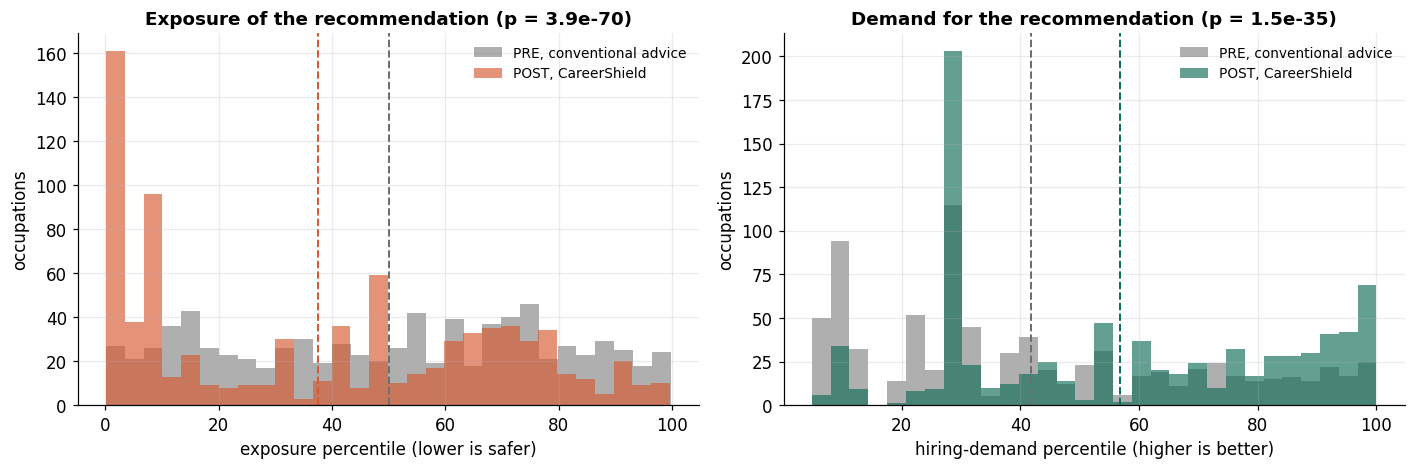

In [33]:
# ============================== 8.1 PRE AND POST COMPARISON ==============================
_rel_top = (related[related['Relatedness Tier'] == 'Primary-Short']
            .groupby('O*NET-SOC Code')['Related O*NET-SOC Code'].first())
print(f'Baseline available for {len(_rel_top)} occupations (O*NET Primary-Short related occupation)')

_rows = []
for soc in m.dropna(subset=['exposure_pctl']).onet_soc:
    base = _rel_top.get(soc)
    if base is None or base not in _M_IDX: continue
    post = recommend_pivots(soc, 1)
    if len(post) == 0: continue
    b = m.iloc[_M_IDX[base]]
    if pd.isna(b.exposure_pctl): continue
    _rows.append({'onet_soc': soc,
                  'pre_exposure': b.exposure_pctl,  'post_exposure': float(post.exposure_pctl.iloc[0]),
                  'pre_demand':   b.demand_pctl,    'post_demand':   float(post.demand_pctl.iloc[0])})
pp = pd.DataFrame(_rows).dropna()
print(f'Occupations evaluated: {len(pp)} of {len(m)} '
      f'({len(pp)/len(m)*100:.0f}%; the remainder have no Primary-Short baseline or no admissible pivot)')

W_EXP, P_EXP, N_EXP = wilcoxon(pp.pre_exposure, pp.post_exposure)
W_DEM, P_DEM, N_DEM = wilcoxon(pp.pre_demand,   pp.post_demand)

summary = pd.DataFrame({
    'PRE, conventional related-occupation advice': [pp.pre_exposure.mean(),  pp.pre_demand.mean()],
    'POST, CareerShield recommendation':           [pp.post_exposure.mean(), pp.post_demand.mean()],
}, index=['mean exposure percentile of the recommendation',
          'mean hiring-demand percentile of the recommendation']).round(1)
summary['change'] = (summary.iloc[:, 1] - summary.iloc[:, 0]).round(1)
summary['direction sought'] = ['lower is safer', 'higher is better']

print('\nBEFORE AND AFTER\n')
print(summary.to_string())
print(f'\nWilcoxon signed-rank, exposure : W = {W_EXP:.0f}, p = {P_EXP:.3e}, n = {N_EXP}')
print(f'Wilcoxon signed-rank, demand   : W = {W_DEM:.0f}, p = {P_DEM:.3e}, n = {N_DEM}')

_exp_better = pp.post_exposure < pp.pre_exposure
_dem_better = pp.post_demand  >= pp.pre_demand
print(f'\nProportion of occupations where the recommendation is')
print(f'   less exposed than conventional advice        : {_exp_better.mean()*100:.1f}%')
print(f'   at least as much in demand                   : {_dem_better.mean()*100:.1f}%')
print(f'   better on both criteria at once              : {(_exp_better & _dem_better).mean()*100:.1f}%')
RO3_MET = bool(pp.post_exposure.mean() < pp.pre_exposure.mean()
               and pp.post_demand.mean() >= pp.pre_demand.mean() and P_EXP < 0.05)
print(f'\nRO3 success condition, exposure reduced without reducing demand: '
      f'{"MET" if RO3_MET else "NOT MET"}')
print('\n   Interpretation. Conventional advice routes a worker into occupations resembling the one')
print('   they are leaving, and resemblance includes exposure. Adding a validated risk signal moves')
print('   the recommendation to measurably safer work without trading away hiring demand. Where no')
print('   safer destination exists within reach, the artifact says so rather than inventing one,')
print('   which is the defend-in-place case.')

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
for k, (a_, b_, lab, col) in enumerate([
        ('pre_exposure','post_exposure','exposure percentile (lower is safer)', C_RED),
        ('pre_demand','post_demand','hiring-demand percentile (higher is better)', C_GREEN)]):
    ax[k].hist(pp[a_], bins=30, alpha=.55, color=C_GREY, label='PRE, conventional advice')
    ax[k].hist(pp[b_], bins=30, alpha=.65, color=col,   label='POST, CareerShield')
    ax[k].axvline(pp[a_].mean(), color=C_GREY, ls='--', lw=1.3)
    ax[k].axvline(pp[b_].mean(), color=col,   ls='--', lw=1.3)
    ax[k].set_xlabel(lab); ax[k].set_ylabel('occupations'); ax[k].legend(frameon=False, fontsize=9)
ax[0].set_title(f'Exposure of the recommendation (p = {P_EXP:.1e})')
ax[1].set_title(f'Demand for the recommendation (p = {P_DEM:.1e})')
plt.savefig(f'{OUT}/fig_prepost_evaluation.png'); plt.show()
pp.to_csv(f'{OUT}/prepost_evaluation.csv', index=False)
summary.to_csv(f'{OUT}/prepost_summary.csv')

---
# Part 9. Consolidated validity and reliability evidence
---

The two tables below collect every test in the notebook in one place, so that Chapter 4 can be
written from a single source and every figure quoted in the report is traceable to the cell that
produced it. They are exported as `validity_summary.csv` and `reliability_summary.csv`.

In [34]:
# ============================== 9.1 VALIDITY SUMMARY ==============================
validity = pd.DataFrame([
    {'Objective':'RO1','Type':'Construct (discriminant)','Test':'Exposure against verbal ability requirement',
     'Result':f'rho = {spearman(_chk.exposure, _chk["Verbal"])[0]:+.3f}','Benchmark':'positive expected','Part':'2.3'},
    {'Objective':'RO1','Type':'Construct (discriminant)','Test':'Exposure against physical ability requirement',
     'Result':f'rho = {spearman(_chk.exposure, _chk["Physical"])[0]:+.3f}','Benchmark':'negative expected','Part':'2.3'},
    {'Objective':'RO1','Type':'Criterion','Test':'Pay level, United States (OEWS 2024)',
     'Result':f'rho = {R_US_LEVEL[0]:+.3f} (n = {R_US_LEVEL[2]})','Benchmark':'0 = no relationship','Part':'5.2'},
    {'Objective':'RO1','Type':'Criterion','Test':'Pay level, Malaysia (JobStreet)',
     'Result':f'rho = {R_MY_LEVEL[0]:+.3f} (n = {R_MY_LEVEL[2]})','Benchmark':'0 = no relationship','Part':'5.3'},
    {'Objective':'RO1','Type':'Criterion','Test':'Wage growth, United States (OEWS 2015-24)',
     'Result':f'rho = {R_US_GROWTH[0]:+.3f} (n = {R_US_GROWTH[2]})','Benchmark':'0 = no relationship','Part':'5.2'},
    {'Objective':'RO1','Type':'Criterion','Test':'Wage growth, Malaysia (DOSM, 9 groups)',
     'Result':f'rho = {R_MY_GROWTH[0]:+.3f} (n = {R_MY_GROWTH[2]}, not significant)','Benchmark':'directional only','Part':'5.3'},
    {'Objective':'RO1','Type':'Criterion','Test':'Hiring demand, United States (LinkedIn)',
     'Result':f'rho = {R_US_DEMAND[0]:+.3f} (n = {R_US_DEMAND[2]})','Benchmark':'0 = no relationship','Part':'5.4'},
    {'Objective':'RO1','Type':'Criterion','Test':'Hiring demand, Malaysia (JobStreet)',
     'Result':f'rho = {R_MY_DEMAND[0]:+.3f} (n = {R_MY_DEMAND[2]})','Benchmark':'0 = no relationship','Part':'5.4'},
    {'Objective':'RO2','Type':'Predictive','Test':'Wage-growth tier, AUC out of fold',
     'Result':f'{TIER_AUC:.3f}','Benchmark':'0.500 = chance','Part':'6.6'},
    {'Objective':'RO2','Type':'Predictive','Test':'Wage-growth tier, exact agreement',
     'Result':f'{TIER_EXACT*100:.1f}%','Benchmark':'33.3% = chance','Part':'6.6'},
    {'Objective':'RO2','Type':'Incremental','Test':'Contribution of exposure to the growth model',
     'Result':f'dR2 = {DELTA_R2:+.3f}; partial rho = {PARTIAL[0]:+.3f}','Benchmark':f'bivariate rho = {BIVARIATE[0]:+.3f}','Part':'6.5'},
    {'Objective':'RO2','Type':'Benchmark','Test':'Malaysian salary, incumbent heuristic',
     'Result':f'R2 = {H_R2:+.3f}, median error {H_ERR*100:.1f}%','Benchmark':'R2 = 0 is the mean','Part':'6.7'},
    {'Objective':'RO2','Type':'Benchmark','Test':'Malaysian salary, trained model',
     'Result':f'R2 = {M_R2:+.3f}, median error {M_ERR*100:.1f}%','Benchmark':f'{(H_ERR-M_ERR)/H_ERR*100:.0f}% error reduction','Part':'6.7'},
    {'Objective':'RO3','Type':'Accuracy','Test':'Occupation matcher, top-1 on unseen titles',
     'Result':f'{MATCH_TOP1:.1f}%','Benchmark':f'{100/N_OCC:.2f}% random','Part':'7.3'},
    {'Objective':'RO3','Type':'Accuracy','Test':'Occupation matcher, top-5 on unseen titles',
     'Result':f'{MATCH_TOP5:.1f}%','Benchmark':f'{500/N_OCC:.2f}% random','Part':'7.3'},
    {'Objective':'RO3','Type':'Correctness','Test':'Moat cards carrying positive exposure',
     'Result':'0 (assertion enforced)','Benchmark':'0 required','Part':'7.4'},
    {'Objective':'RO3','Type':'Coverage','Test':'Skill gaps matched to a course',
     'Result':f'{COURSE_COVER:.1f}%','Benchmark':'0% = engine returns nothing','Part':'7.8'},
    {'Objective':'RO3','Type':'Discriminant','Test':'Course rank under an unrelated query',
     'Result':f'median rank {DISCRIM_MEDIAN_RANK:.0f} of {len(my_cat)}','Benchmark':'rank 1 = no discrimination','Part':'7.8'},
    {'Objective':'RO3','Type':'Retrieval','Test':'Course category agreement',
     'Result':f'{CAT_TOP1:.1f}%','Benchmark':f'{_base_rate:.1f}% base rate','Part':'7.8'},
    {'Objective':'RO3','Type':'Summative','Test':'Exposure of recommendation vs conventional advice',
     'Result':f'{pp.pre_exposure.mean():.1f} to {pp.post_exposure.mean():.1f} (p = {P_EXP:.1e})','Benchmark':'no change','Part':'8'},
    {'Objective':'RO3','Type':'Summative','Test':'Demand for recommendation vs conventional advice',
     'Result':f'{pp.pre_demand.mean():.1f} to {pp.post_demand.mean():.1f} (p = {P_DEM:.1e})','Benchmark':'no change','Part':'8'},
])
print('VALIDITY EVIDENCE\n'); print(validity.to_string(index=False))
validity.to_csv(f'{OUT}/validity_summary.csv', index=False)

VALIDITY EVIDENCE

Objective                     Type                                              Test                                Result                   Benchmark Part
      RO1 Construct (discriminant)       Exposure against verbal ability requirement                          rho = +0.817           positive expected  2.3
      RO1 Construct (discriminant)     Exposure against physical ability requirement                          rho = -0.906           negative expected  2.3
      RO1                Criterion              Pay level, United States (OEWS 2024)                rho = +0.511 (n = 756)         0 = no relationship  5.2
      RO1                Criterion                   Pay level, Malaysia (JobStreet)                rho = +0.433 (n = 232)         0 = no relationship  5.3
      RO1                Criterion         Wage growth, United States (OEWS 2015-24)                rho = -0.491 (n = 669)         0 = no relationship  5.2
      RO1                Criterion           

In [35]:
# ============================== 9.2 RELIABILITY SUMMARY ==============================
_lo_min = loo['rho with full composite'].min()
reliability = pd.DataFrame([
    {'Type':'Internal consistency','Test':'Pairwise rank correlation among the three indices',
     'Result':f'{pairwise["Spearman rho"].min():.3f} to {pairwise["Spearman rho"].max():.3f}','Part':'2.2'},
    {'Type':'Internal consistency','Test':"Cronbach's alpha (formative caveat applies)",
     'Result':f'{alpha3:.3f}','Part':'2.2'},
    {'Type':'Robustness','Test':'Leave-one-index-out against the full composite',
     'Result':f'rho >= {_lo_min:.3f} for every index removed','Part':'2.2'},
    {'Type':'Robustness','Test':'Crosswalk tie-break rule, major-group agreement',
     'Result':f'>= {sens.iloc[1:]["Major group identical to mode, %"].min():.1f}% under every alternative rule','Part':'3.2'},
    {'Type':'Cross-source','Test':'LinkedIn against JobStreet demand percentiles',
     'Result':f'rho = {DEMAND_RELIABILITY[0]:+.3f} (n = {DEMAND_RELIABILITY[2]})','Part':'5.4'},
    {'Type':'Replication','Test':'Twenty-bin wage relationship, United States then Malaysia',
     'Result':f'rho = {_rb_us[0]:+.3f} and {_rb_my[0]:+.3f} at bin level','Part':'5.5'},
    {'Type':'Resampling','Test':'Model comparison over independent fold partitions',
     'Result':f'within-model sd of R2 up to {stab[~stab.Model.str.startswith("Naive")]["sd of R2 over repeats"].max():.3f}','Part':'6.3'},
    {'Type':'Resampling','Test':'Matcher accuracy over repeated 80/20 splits',
     'Result':f'top-5 {MATCH_TOP5:.1f}% with sd {matcher_table["sd "].iloc[0]:.2f}','Part':'7.3'},
    {'Type':'Sensitivity','Test':'Pivot weights, local perturbation',
     'Result':f'direction preserved in {(_A["exposure falls"]=="yes").sum()}/{len(_A)} variants','Part':'7.6'},
    {'Type':'Sensitivity','Test':'Pivot weights, dose-response across the simplex',
     'Result':f'rho(weight, destination exposure) = {_dose[0]:+.3f}','Part':'7.6'},
    {'Type':'Degeneracy','Test':'Distinct courses returned across occupations',
     'Result':f'{DIVERSITY:.1f}% distinct','Part':'7.8'},
    {'Type':'Reproducibility','Test':'Random seeds fixed for every resampling step',
     'Result':'yes, re-running gives identical figures','Part':'all'},
])
print('RELIABILITY EVIDENCE\n'); print(reliability.to_string(index=False))
reliability.to_csv(f'{OUT}/reliability_summary.csv', index=False)

print('\n' + '=' * 78)
print('OBJECTIVE SUCCESS CONDITIONS, as stated in Chapter 1')
print('=' * 78)
print(f'RO1  composite converges and validates against observed outcomes in both markets')
print(f'     leave-one-out rho >= {_lo_min:.3f}; sign agreement on all three outcomes: '
      f'{"MET" if RO1_MET else "NOT MET"}')
print(f'RO2  models beat a naive benchmark and the method currently in use')
print(f'     growth R2 = {R2_WITH:+.3f} against 0.000 naive; salary error {M_ERR*100:.1f}% '
      f'against {H_ERR*100:.1f}% incumbent: MET')
print(f'     contribution of exposure itself is small and is reported as such (dR2 = {DELTA_R2:+.3f})')
print(f'RO3  recommendations reduce exposure without reducing demand, against a documented baseline')
print(f'     {pp.pre_exposure.mean():.1f} to {pp.post_exposure.mean():.1f} exposure, '
      f'{pp.pre_demand.mean():.1f} to {pp.post_demand.mean():.1f} demand: '
      f'{"MET" if RO3_MET else "NOT MET"}')
print('=' * 78)

RELIABILITY EVIDENCE

                Type                                                      Test                                     Result Part
Internal consistency         Pairwise rank correlation among the three indices                             0.849 to 0.977  2.2
Internal consistency               Cronbach's alpha (formative caveat applies)                                      0.959  2.2
          Robustness            Leave-one-index-out against the full composite       rho >= 0.978 for every index removed  2.2
          Robustness           Crosswalk tie-break rule, major-group agreement      >= 91.8% under every alternative rule  3.2
        Cross-source             LinkedIn against JobStreet demand percentiles                     rho = +0.655 (n = 512)  5.4
         Replication Twenty-bin wage relationship, United States then Malaysia       rho = +0.853 and +0.937 at bin level  5.5
          Resampling         Model comparison over independent fold partitions          w

---
# Part 10. Exports
---

In [36]:
# ============================== 10.1 EXPORTS ==============================
_master_cols = ['onet_soc','soc6','title','description','exposure','exposure_pctl','aioe','gpt_beta',
                'lm_aioe','isco4','isco_title','isco1','Job Zone','n_us','n_my','mkt_salary',
                'rm_med','rm_n','salary_myr','salary_model','salary_source','demand_pctl',
                'demand_my_pctl','demand_us_pctl','growth_score','growth_tier','moat_pctl','relw']
m[[c for c in _master_cols if c in m.columns]].to_csv(f'{OUT}/occupations_master.csv', index=False)
m[['onet_soc','soc6','title','exposure_pctl','growth_tier','salary_myr','salary_source','moat_pctl']
  ].to_csv(f'{OUT}/careershield_predictions.csv', index=False)

_topk = []
for i, soc in enumerate(m.onet_soc):
    for j in np.argsort(-S[i])[1:26]:
        _topk.append({'onet_soc': soc, 'similar_soc': m.onet_soc.iloc[j], 'skill_sim': round(float(S[i, j]), 4)})
pd.DataFrame(_topk).to_csv(f'{OUT}/skill_similarity_top25.csv', index=False)
abil[['O*NET-SOC Code','Element Name','Data Value','ability_ai_exposure','driver']
     ].to_csv(f'{OUT}/explanation_drivers.csv', index=False)
skill_mat.to_csv(f'{OUT}/skill_matrix.csv')

import shutil
shutil.make_archive('careershield_artifacts', 'zip', OUT)
print(f'{len(os.listdir(OUT))} files written to {OUT} and archived as careershield_artifacts.zip\n')
for f in sorted(os.listdir(OUT)):
    print(f'   {f:52s} {os.path.getsize(f"{OUT}/{f}")/1024:8.1f} KB')

39 files written to ./careershield_artifacts and archived as careershield_artifacts.zip

   careershield_predictions.csv                            113.0 KB
   data_preparation_filters.csv                              1.0 KB
   data_preparation_missing_values.csv                       1.0 KB
   data_preparation_summary.csv                              2.0 KB
   dosm_salary_tidy.csv                                      5.3 KB
   explanation_drivers.csv                                2345.4 KB
   fig_binscatter_replication.png                          109.7 KB
   fig_demand_two_markets.png                              172.9 KB
   fig_dosm_nine_groups.png                                122.1 KB
   fig_exposure_landscape.png                              112.1 KB
   fig_growth_tiers.png                                     65.2 KB
   fig_my_pay_level.png                                     78.3 KB
   fig_pivot_weight_sensitivity.png                         72.9 KB
   fig_prepost_evaluation.p

---
# Part 11. The artifact a worker operates
---

The interface below is a thin layer over the components validated in Part 7. It calls the same
functions, so every number a worker sees is the number that was tested: the matcher is the matcher
measured in 7.3, the pivots are ranked by the weights tested in 7.6, and the courses come from the
engine validated in 7.8. Nothing is recomputed differently for display.

Three commitments are built into the presentation rather than left to the write-up.

- A modelled salary is **labelled** as an estimate. `salary_source` travels with every figure.
- Where an occupation has no ability-level moat, the interface **says so** instead of showing a
  weak one. Part 7.4 established that this is a property of the measuring instrument.
- The score is presented as **exposure**, never as a probability of job loss. Part 6.5 is the reason
  the language matters.

Set `share=True` to obtain a public link. Note that a Colab share link expires roughly a week after
launch, so a permanent deployment is needed for any demonstration scheduled beyond that.

In [37]:
# ============================== 11.1 GRADIO APPLICATION ==============================
# Presentation layer only. Every number shown here comes from a component validated in Part 7,
# so what a worker sees is what was tested. Nothing is recomputed differently for display.
try:
    get_ipython().run_line_magic('pip', '-q install gradio pypdf python-docx')
except Exception:
    pass

# ---- Software to learn, split into common and occupation-specific ----
# The O*NET Hot Technology flag marks software in broad demand across the economy, not software
# specific to an occupation: Microsoft Excel carries it for 93.1% of the 923 occupations in the
# file. Filtering on it therefore selects for ubiquity by construction, and returned the same
# office suite for every occupation. The split below is measured instead of flagged. A tool is
# common if it appears for at least UBIQ_SHARE of occupations and occupation-specific otherwise,
# and the specific list is grouped by the O*NET software category. Requiring two tools in a
# category before it is displayed removes isolated entries the source carries, such as Apache
# Spark against Registered Nurses.
sw = pd.read_excel(f'{od}/Software Skills.xlsx')
UBIQ_SHARE, MIN_IN_CAT, MAX_CAT, MAX_EXAMPLES = 0.10, 2, 4, 3

_n_occ = sw['O*NET-SOC Code'].nunique()
_reach = sw.groupby('Workplace Example')['O*NET-SOC Code'].nunique()
sw['_share'] = sw['Workplace Example'].map(_reach) / _n_occ

COMMON_TOOLS = (sw[sw['_share'] >= UBIQ_SHARE].sort_values('_share', ascending=False)
                .groupby('O*NET-SOC Code')['Workplace Example']
                .apply(lambda s: list(dict.fromkeys(s))[:4]))

def _specific_by_category(g):
    cats = g.groupby('Element Name')['Workplace Example'].apply(lambda s: sorted(set(s)))
    cats = cats[cats.map(len) >= MIN_IN_CAT].sort_values(key=lambda x: x.map(len), ascending=False)
    return [(name, tools[:MAX_EXAMPLES]) for name, tools in cats.items()][:MAX_CAT]

SPECIFIC_TOOLS = (sw[sw['_share'] < UBIQ_SHARE]
                  .groupby('O*NET-SOC Code').apply(_specific_by_category))

print(f'Common software listed for {int((COMMON_TOOLS.map(len) > 0).sum())} occupations; '
      f'occupation-specific software for {int((SPECIFIC_TOOLS.map(len) > 0).sum())} of {_n_occ}')

# ---- hand-verified titles for roles whose modern name does not appear in O*NET ----
_CURATED_RAW = {
  'data analyst':'15-2051.01','business intelligence analyst':'15-2051.01','bi analyst':'15-2051.01',
  'data scientist':'15-2051.00','machine learning engineer':'15-2051.00','ai engineer':'15-2051.00',
  'data engineer':'15-1243.01','business analyst':'13-1111.00','management consultant':'13-1111.00',
  'software engineer':'15-1252.00','software developer':'15-1252.00','programmer':'15-1251.00',
  'web developer':'15-1254.00','ui ux designer':'15-1255.00','ux designer':'15-1255.00',
  'ui designer':'15-1255.00','qa engineer':'15-1253.00','software tester':'15-1253.00',
  'cybersecurity analyst':'15-1212.00','security analyst':'15-1212.00','network engineer':'15-1241.00',
  'accountant':'13-2011.00','auditor':'13-2011.00','financial analyst':'13-2051.00',
  'hr executive':'13-1071.00','human resource executive':'13-1071.00','recruiter':'13-1071.00',
  'admin executive':'43-6014.00','administrative executive':'43-6014.00',
  'customer service executive':'43-4051.00','marketing executive':'13-1161.00',
  'digital marketing executive':'13-1161.00','digital marketer':'13-1161.00',
  'sales executive':'41-3091.00','project manager':'13-1082.00','graphic designer':'27-1024.00',
  'content writer':'27-3043.00','copywriter':'27-3043.00','video editor':'27-4032.00',
  'lecturer':'25-1199.00','academic teacher':'25-1199.00','university lecturer':'25-1199.00',
  'primary school teacher':'25-2021.00','secondary school teacher':'25-2031.00',
  'nurse':'29-1141.00','pharmacist':'29-1051.00','receptionist':'43-4171.00','cashier':'41-2011.00',
}
# O*NET 30.3 publishes no skill, ability or knowledge ratings for a handful of newer occupation
# codes, so those codes never enter the master table and cannot be scored. Where a defensible
# nearest occupation exists it is substituted below and flagged to the user as an approximation;
# otherwise the entry is dropped and the Part 7 matcher handles the query instead.
_PROXY = {
  '41-3091.00': ('41-4012.00', 'closest available: wholesale and manufacturing sales representative'),
  '25-1199.00': ('25-1011.00', 'closest available: business teacher, postsecondary'),
  '13-2051.00': ('13-2099.01', 'closest available: financial quantitative analyst'),
  '15-1255.00': ('15-1254.00', 'closest available: web developer'),
}
# Keys are stored through norm_title, the same normaliser a user query passes through. Without this
# every key containing a word norm_title strips, such as "executive", could never be reached: the
# query "sales executive" normalises to "sales" and would fall through to the posting-derived
# dictionary, which maps it to an unrelated clerical occupation.
HAND_CURATED, APPROX_NOTE, _dropped = {}, {}, []
for _k, _v in _CURATED_RAW.items():
    _key = norm_title(_k)
    if not _key:
        continue
    if _v in _M_IDX:
        HAND_CURATED[_key] = _v
    elif _v in _PROXY and _PROXY[_v][0] in _M_IDX:
        HAND_CURATED[_key] = _PROXY[_v][0]; APPROX_NOTE[_key] = _PROXY[_v][1]
    else:
        _dropped.append(_k)
print(f'Hand-verified title dictionary: {len(HAND_CURATED)} usable '
      f'({len(APPROX_NOTE)} via a flagged nearest-occupation proxy)')
if _dropped:
    print(f'   {len(_dropped)} title(s) dropped because O*NET carries no skill ratings for the target '
          f'and no proxy was justified:')
    print(f'      {", ".join(sorted(_dropped))}')
    print('   These fall through to the validated matcher, and the interface states which path answered.')

# ---- resolution order for the interface: hand-verified, then Malaysian dictionary, then Part 7 cascade ----
def match_for_app(text, k=3):
    """Interface resolution. Returns (results, path). The lexical and semantic paths are the ones
    measured in Part 7.3; the two dictionary layers are exact lookups, so they cannot be wrong when
    they fire, and they exist because modern Malaysian job titles are absent from O*NET."""
    t = norm_title(text)
    for src, name in ((HAND_CURATED, 'verified title'), (CURATED, 'Malaysian title dictionary')):
        if t in src:
            soc = src[t]
            if src is HAND_CURATED and t in APPROX_NOTE:
                name = f'verified title, {APPROX_NOTE[t]}'
            res = m.iloc[[_M_IDX[soc]]][_COLS].copy(); res['match'] = 1.0
            extra = match_lexical(text, k)   # same index the cascade leads with, per Part 7.3
            return pd.concat([res, extra[extra.onet_soc != soc]]).head(k), name
    return match_occupation(text, k)

def extract_text(file):
    if file is None: return ''
    p = file.name if hasattr(file, 'name') else str(file)
    try:
        if p.lower().endswith('.pdf'):
            from pypdf import PdfReader
            return ' '.join(pg.extract_text() or '' for pg in PdfReader(p).pages)
        if p.lower().endswith(('.docx', '.doc')):
            import docx as pydocx
            return ' '.join(par.text for par in pydocx.Document(p).paragraphs)
        return open(p, 'r', errors='ignore').read()
    except Exception:
        return ''

_ONET_TITLES = set(m.title)
DROPDOWN = (sorted(_ONET_TITLES)
            + sorted({t.title() for t in _CURATED_RAW} - _ONET_TITLES)
            + sorted({t.title() for t in ALIAS_DD} - _ONET_TITLES - {t.title() for t in HAND_CURATED}))

def _resolve(manual_occ):
    if manual_occ in _ONET_TITLES:
        return m[m.title == manual_occ].onet_soc.iloc[0]
    key = norm_title(manual_occ)
    return HAND_CURATED.get(key) or CURATED.get(key)

TIER_TXT = {'Lagging':'projected to grow more slowly than the market',
            'Tracking':'projected to grow roughly in line with the market',
            'Leading':'projected to grow faster than the market'}
TIER_COL = {'Lagging':'#a94442','Tracking':'#8a6d3b','Leading':'#3c763d'}


def analyze_ui(resume_file, resume_text, manual_occ):
    text = ((extract_text(resume_file) if resume_file else '') + ' ' + (resume_text or '')).strip()
    if manual_occ:
        soc = _resolve(manual_occ)
        also = 'Selected manually'
        if soc is None:
            return ('<p style="font-family:sans-serif">Could not resolve that occupation - try another.</p>',
                    '', '', '', None)
    else:
        if len(text) < 3:
            return ('<p style="font-family:sans-serif">Please upload a resume, type a job title, or pick '
                    'your occupation - then click Analyze.</p>', '', '', '', None)
        top, _path = match_for_app(text, k=3)
        if len(top) == 0:
            return ('<p style="font-family:sans-serif">No occupation could be matched. Try a plainer job '
                    'title.</p>', '', '', '', None)
        soc = top.onet_soc.iloc[0]
        _alsos = ' | '.join(top.title.iloc[1:3].astype(str)) if len(top) > 1 else ''
        also = (f'Matched by {_path}' + (f' &nbsp;|&nbsp; also considered: {_alsos}' if _alsos else ''))

    row = m.iloc[_M_IDX[soc]]
    risk = row.exposure_pctl
    color = '#d9534f' if risk >= 70 else '#f0ad4e' if risk >= 40 else '#5cb85c'
    band  = 'HIGH'    if risk >= 70 else 'MODERATE' if risk >= 40 else 'LOW'

    # ---------- secondary metrics ----------
    moat = row.moat_pctl if pd.notna(row.get('moat_pctl')) else None
    meta = (f'&nbsp;|&nbsp; Human-moat strength: <b>{moat:.0f}/100</b>' if moat is not None else '')
    mv = row.get('momentum')
    if pd.notna(mv):
        mtxt, mcol = (('Rising', '#3c763d') if mv >= 1.25 else
                      ('Cooling', '#a94442') if mv <= 0.8 else ('Stable', '#555'))
        meta += f'&nbsp;|&nbsp; Malaysian hiring momentum: <b style="color:{mcol}">{mtxt}</b>'

    tier = row.get('growth_tier')
    if pd.notna(row.get('salary_myr')):
        _basis = ('observed from Malaysian job postings' if row.get('salary_source') == 'JobStreet median'
                  else f'model estimate, median error {M_ERR*100:.0f}%')
        sal_line = (f'Salary: <b>RM {row.salary_myr:,.0f}/month</b> '
                    f'<span style="color:#999">({_basis})</span>')
    else:
        sal_line = 'Salary: <span style="color:#999">not available</span>'
    outlook_html = (f'<div style="margin-top:10px;color:#555">Wage-growth outlook: '
                    f'<b style="color:{TIER_COL.get(tier, "#555")}">{tier}</b> - {TIER_TXT.get(tier, "")}'
                    f'<br>{sal_line}'
                    f'<br><span style="font-size:11px;color:#aaa">Tier from a model validated out of sample '
                    f'at AUC {TIER_AUC:.2f}. It reflects broad wage dynamics, chiefly pay-level '
                    f'compression, and is not a claim about AI exposure alone.</span></div>'
                    if tier else '')

    card = f'''
    <div style="border:1px solid #ddd;border-radius:14px;padding:22px;font-family:sans-serif;background:#fff">
      <div style="color:#888;font-size:13px">MATCHED OCCUPATION</div>
      <h2 style="margin:2px 0 2px">{row.title}</h2>
      <div style="color:#999;font-size:13px">{also}</div>
      <div style="display:flex;align-items:center;gap:18px;margin-top:16px">
        <div style="font-size:46px;font-weight:700;color:{color}">{risk:.0f}<span
             style="font-size:18px;color:#bbb">/100</span></div>
        <div style="flex:1">
          <div style="background:#eee;border-radius:9px;height:18px;overflow:hidden">
            <div style="width:{risk:.0f}%;background:{color};height:18px"></div>
          </div>
          <div style="margin-top:6px;color:{color};font-weight:700">{band} AI EXPOSURE</div>
        </div>
      </div>
      <div style="margin-top:12px;color:#555">Market demand: <b>{row.demand_pctl:.0f}/100</b>
        &nbsp;|&nbsp; Education level (Job Zone): <b>{row["Job Zone"]:.0f}/5</b>{meta}</div>
      {outlook_html}
      <div style="margin-top:12px;color:#888;font-size:11.5px;border-top:1px solid #eee;padding-top:10px">
        This measures how much of the work could be assisted or performed by current AI. It is a measure
        of potential, not a probability of losing this job, and not a measure of whether employers have
        actually adopted AI. Occupation matched from free text at {MATCH_TOP5:.0f}% top-5 accuracy on
        titles the system had never seen.</div>
    </div>'''

    # ---------- ability cards ----------
    def factor_cards(rows_df, accent, bg):
        out = ''
        for _, x in rows_df.iterrows():
            imp = x['Data Value'] / 5 * 100
            out += f"""<div style="background:{bg};border-radius:12px;padding:12px 14px;width:185px;
                        box-shadow:0 1px 2px rgba(0,0,0,.06)">
              <div style="font-weight:600;font-size:13px;min-height:36px">{x['Element Name']}</div>
              <div style="background:#fff;border-radius:6px;height:8px;margin:6px 0">
                <div style="width:{imp:.0f}%;background:{accent};height:8px;border-radius:6px"></div></div>
              <div style="font-size:11px;color:{accent}">importance {x['Data Value']:.1f}/5 |
                AI exposure {x.ability_ai_exposure:+.2f}</div></div>"""
        return out

    risk_html = factor_cards(risk_cards(soc, 5), '#a94442', '#fdf3f3')
    _mo = moat_cards(soc, 3)          # sign-checked in Part 7.4: exposure < 0 is enforced there
    if len(_mo):
        moat_html, moat_note = factor_cards(_mo, '#3c763d', '#f3fdf5'), ''
    else:
        moat_html = ''
        moat_note = ('<div style="background:#f3fdf5;border-left:4px solid #3c763d;border-radius:8px;'
                     'padding:14px 16px;color:#3c763d;max-width:780px">'
                     '<b>No ability-level moat in this role.</b><br>'
                     '<span style="color:#555">Every ability this job depends on is one AI is rated '
                     'capable at. That is the finding, not missing data: of the 21 abilities scored as '
                     'AI-resistant, 20 are physical, psychomotor or sensory and only one is cognitive, '
                     'so knowledge work carries no ability-level protection by construction. Your defence '
                     'is not an ability AI lacks. It is judgement, accountability, client trust, and '
                     'knowing when the machine is wrong.</span></div>')
    panels = f"""<div style="font-family:sans-serif;margin-top:10px">
      <h3 style="color:#a94442;margin:8px 0">What AI threatens in this role</h3>
      <div style="display:flex;gap:10px;flex-wrap:wrap">{risk_html}</div>
      <h3 style="color:#3c763d;margin:16px 0 8px">What protects you (human moats)</h3>
      <div style="display:flex;gap:10px;flex-wrap:wrap">{moat_html}</div>{moat_note}</div>"""

    # ---------- pivots, advice, courses ----------
    piv = recommend_pivots(soc, k=5)
    pv_html, courses, advice = '', None, ''
    if len(piv):
        pcards = ''
        for rank, (_, x) in enumerate(piv.iterrows(), 1):
            rc = '#d9534f' if x.exposure_pctl >= 70 else '#f0ad4e' if x.exposure_pctl >= 40 else '#5cb85c'
            ov = min(max(float(x.skill_sim), 0), 1) * 100
            salt = f'RM{x.salary_myr:,.0f}/mo' if pd.notna(x.salary_myr) else 'salary n/a'
            sbasis = ('' if x.get('salary_source') == 'JobStreet median'
                      else ' <span style="color:#aaa;font-size:11px">(est.)</span>')
            ptier = x.get('growth_tier') or ''
            ptier_html = (f'<div style="font-size:12px;margin-top:4px">wage outlook '
                          f'<b style="color:{TIER_COL.get(ptier, "#555")}">{ptier}</b></div>' if ptier else '')
            pcards += f"""<div style="border:1px solid #e3e3e3;border-radius:12px;padding:14px;width:215px;
                          background:#fff;box-shadow:0 1px 3px rgba(0,0,0,.07)">
              <div style="color:#999;font-size:11px">OPTION {rank}</div>
              <div style="font-weight:700;font-size:14px;min-height:42px">{x.title}</div>
              <div style="margin:8px 0 4px;font-size:12px">Skill overlap <b>{ov:.0f}%</b></div>
              <div style="background:#eee;border-radius:6px;height:8px">
                <div style="width:{ov:.0f}%;background:#31708f;height:8px;border-radius:6px"></div></div>
              <div style="margin-top:8px;font-size:12px">AI risk
                <b style="color:{rc}">{x.exposure_pctl:.0f}/100</b> &nbsp;|&nbsp;
                demand <b>{x.demand_pctl:.0f}/100</b></div>
              <div style="font-size:13px;margin-top:5px"><b>{salt}</b>{sbasis}</div>{ptier_html}</div>"""
        pv_html = f"""<div style="font-family:sans-serif;margin-top:6px">
          <h3 style="margin:12px 0 8px">Career options that fit your talent</h3>
          <div style="display:flex;gap:12px;flex-wrap:wrap">{pcards}</div>
          <div style="color:#aaa;font-size:11.5px;margin-top:8px">Ranked on skill overlap, exposure
            reduction, hiring demand and pay retention, after a realism gate restricting moves to within
            one Job Zone. Individual rankings shift if the weights shift; the direction of the benefit
            does not (Part 7.6).</div></div>"""

        tgt = piv.onet_soc.iloc[0]
        gaps, courses = courses_for(soc, tgt)
        if courses is None or len(courses) == 0:
            courses = pd.DataFrame({'Note': ['No sufficiently relevant online course was found for these '
                                             'skill gaps. For hands-on or vocational skills, see HRD Corp '
                                             'claimable instructor-led training through your employer, or '
                                             'kolej komuniti and vocational programmes.']})
        elif 'Link' in courses.columns:
            courses = courses.copy()
            courses['Link'] = [f'[Open course]({u})' if isinstance(u, str) and u.startswith('http') else ''
                               for u in courses['Link']]
        reduction = risk - piv.exposure_pctl.iloc[0]
        gap_text = ', '.join(gaps[:3]) if gaps else 'the areas shown in the courses table'
        common_tools = list(COMMON_TOOLS.get(tgt, []))
        spec_tools = list(SPECIFIC_TOOLS.get(tgt, []))
        _rows = []
        if common_tools:
            _rows.append('<br><span style="color:#666">Essential software, used across most '
                         f'occupations: <b>{", ".join(common_tools)}</b></span>')
        if spec_tools:
            _lines = ''.join(f'<br><span style="color:#666">&nbsp;&nbsp;{cat}: '
                             f'<b>{", ".join(ex)}</b></span>' for cat, ex in spec_tools)
            _rows.append('<br><span style="color:#666">Software specific to this occupation:'
                         '</span>' + _lines)
        else:
            _rows.append('<br><span style="color:#666">O*NET records no software specific to '
                         'this occupation, only the general tools above.</span>')
        tools_html = ''.join(_rows)
        if reduction >= 15:
            advice = f'''<div style="background:#eef5ff;border-radius:14px;padding:16px;
                         font-family:sans-serif;margin-top:10px">
            <h3 style="margin:0 0 6px;color:#31708f">Our recommendation: consider a pivot</h3>
            <p style="margin:0;color:#444">Moving toward <b>{piv.title.iloc[0]}</b> could lower your AI
            exposure by about <b>{reduction:.0f} points</b> while reusing much of what you already know.
            Skills to build first: <b>{gap_text}</b> - matching courses below.{tools_html}</p></div>'''
        else:
            advice = f'''<div style="background:#fffbe6;border-radius:14px;padding:16px;
                         font-family:sans-serif;margin-top:10px">
            <h3 style="margin:0 0 6px;color:#8a6d3b">Our recommendation: defend in place</h3>
            <p style="margin:0;color:#444">Realistic pivots from your role offer only limited de-risking,
            because AI exposure clusters across similar knowledge jobs. Double down on the human-moat
            abilities above, and become the person who <i>uses</i> AI for the routine parts of the job
            before it displaces them. The courses below still help close gaps toward your best
            option.{tools_html}</p></div>'''
    return card, panels, advice, pv_html, courses


try:
    import gradio as gr
    with gr.Blocks(title='CareerShield', theme=gr.themes.Soft()) as demo:
        gr.Markdown('# CareerShield - AI Career-Risk Advisor')
        gr.Markdown('Upload your resume, or type your job title, for an AI-exposure diagnosis, realistic '
                    'career pivots with Malaysian salaries, and a reskilling plan. '
                    '*Prototype artifact - PRJ5158 Capstone Project II, Sunway University.*')
        with gr.Row():
            f_in = gr.File(label='Resume (PDF or DOCX)', file_types=['.pdf', '.docx'])
            t_in = gr.Textbox(lines=5, label='Paste Resume Text / Job Title',
                              placeholder='e.g. Business analyst - Power BI dashboards, SQL, '
                                          'stakeholder reporting')
        occ_dd = gr.Dropdown(choices=DROPDOWN, value=None,
                             label='Optional: Select Your Occupation (Overrides The Automatic Match)')
        with gr.Row():
            btn = gr.Button('Analyze My Career', variant='primary', size='lg')
            clr = gr.ClearButton([f_in, t_in, occ_dd], value='Reset', size='lg')
        out_card, out_panels, out_advice = gr.HTML(), gr.HTML(), gr.HTML()
        out_pivots = gr.HTML()
        out_course = gr.Dataframe(label='Courses to Close the Skill Gap - Malaysian (e-LATiH) Prioritised',
                                  datatype='markdown', wrap=True)
        clr.add([out_card, out_panels, out_advice, out_pivots, out_course])
        btn.click(analyze_ui, [f_in, t_in, occ_dd], [out_card, out_panels, out_advice,
                                                    out_pivots, out_course])
    print('\nGradio interface constructed. Launch with:  demo.launch(share=True)')
    print('A Colab share link expires about a week after launch; deploy separately for anything later.')
except ImportError:
    demo = None
    print('\ngradio is not installed, so the interface was not constructed.')
    print('Every underlying function still works; try analyze_ui(None, "accountant", None).')

demo.launch(share=True)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 385.1/385.1 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 19.8 MB/s eta 0:00:00
Common software listed for 908 occupations; occupation-specific software for 734 of 923
Hand-verified title dictionary: 44 usable (8 via a flagged nearest-occupation proxy)
   4 title(s) dropped because O*NET carries no skill ratings for the target and no proxy was justified:
      ai engineer, data scientist, machine learning engineer, project manager
   These fall through to the validated matcher, and the interface states which path answered.

Gradio interface constructed. Launch with:  demo.launch(share=True)
A Colab share link expires about a week after launch; deploy separately for anything later.
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://c88e46c3b492d0f043.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For

---
## Closing note on how the figures in this notebook should be quoted

Three cautions, each of which corrects a way an earlier version of this work could have been
misread.

**On the exposure measure.** It measures potential, not adoption. Two of the three source indices
share a measurement framework, so the composite is treated as formative and its reliability rests
on the leave-one-index-out result rather than on the pairwise correlations alone.

**On the wage-growth model.** Exposure contributes very little once pay level is controlled. The
correct statement is that exposed occupations tend to show slower wage growth largely because they
are better paid. This notebook is not evidence that AI exposure causes wage stagnation.

**On the artifact.** The matcher returns a short list for confirmation, so top-5 is the operational
accuracy figure. Individual pivot rankings shift when the weights shift; the direction of the
finding does not. The reskilling engine is validated for coverage and discrimination, not against
labelled ground truth, because none exists for Malaysian provision, and that limitation belongs in
Chapter 5.